# Trabajo Práctico 2 – Aprendizaje de Máquinas
**Universidad Nacional de Colombia – Sede Medellín** · Introducción a la Inteligencia Artificial (3010476)

**Dominio:** educación. Predecimos el **nivel de desempeño en matemáticas** (Nivel 1 a 4) de los estudiantes que presentaron el **Saber 11 de 2022**, a partir de variables del estudiante, de su familia, del colegio y de sus puntajes en las demás áreas.

| Parámetro | Valor |
|---|---|
| Cédula utilizada | **1033178679** |
| Último dígito distinto de 0 | 9 → 5000 + 9 × 150 = **6350 registros** |
| Dos últimos dígitos distintos de 0 | **79** → `random_state = 79`, en la partición, los modelos, el balanceo y los outliers |
| Variable objetivo | `DESEMP_MATEMATICAS` (4 clases) |

Este notebook contiene el código y sus resultados. **La justificación de las decisiones y el análisis de los resultados están en el documento de diseño** (`documento/documento-diseno.md`). Cada sección indica la sección del documento que le corresponde.

### Índice
| Notebook | Contenido | Documento |
|---|---|---|
| **Módulo 1** | **Aprendizaje supervisado** | |
| 0 | Librerías, importaciones y semillas | — |
| 1 | Dataset: generación, carga y verificación de requisitos | 1 y anexo A |
| 2 | Limpieza de variables | 2.1 |
| 3 | Análisis exploratorio (EDA) | 2.2 y 2.3 |
| 4 | Partición y preprocesamiento: los 8 casos de la Figura 1 | 3 |
| 5 | Árboles de decisión y KNN | 4.1, 4.2 y 4.5 |
| 6 | SVM y redes neuronales | 4.3, 4.4 y 4.5 |
| 7 | Evaluación comparativa: Figura 1, gráficas de F1, ROC/PR y costo de los errores | 5 |
| **Módulo 2** | **Aprendizaje no supervisado** | |
| 8 | K-Means y DBSCAN sobre las 8 versiones de la Figura 2 | 6 a 10 |

# Módulo 1 – Aprendizaje supervisado

## 0. Librerías, importaciones y semillas
Instala las dependencias (`imbalanced-learn` aporta SMOTENC; `gdown` solo se usa en la sección 1.1), fija la semilla 79 en Python, NumPy y TensorFlow e imprime las versiones del entorno. Si alguna librería se instala por primera vez, hay que reiniciar el kernel. Las salidas guardadas se generaron con las versiones que imprime la segunda celda de código; con otras versiones o en otro sistema operativo, SMOTENC y TensorFlow pueden cambiar algunas cifras de los casos balanceados y de las redes.

In [1]:
%pip install -q pandas numpy scikit-learn imbalanced-learn matplotlib seaborn tensorflow gdown --disable-pip-version-check

In [2]:
# ------------------------------------------------------------
# Importaciones generales
# ------------------------------------------------------------
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# ------------------------------------------------------------
# Parámetros del equipo (obligatorios según el enunciado)
# ------------------------------------------------------------
CEDULA = "1033178679"
N_REGISTROS = 5000 + 9 * 150   # último dígito distinto de cero = 9 -> 6350
SEMILLA = 79                   # dos últimos dígitos distintos de cero (no es 42)
OBJETIVO = "DESEMP_MATEMATICAS"
CLASES = ["Nivel 1", "Nivel 2", "Nivel 3", "Nivel 4"]   # orden natural de la etiqueta


def fijar_semillas(semilla=SEMILLA):
    """Fija las semillas de Python, NumPy y TensorFlow (si está instalado) para
    que todo el notebook sea reproducible."""
    os.environ["PYTHONHASHSEED"] = str(semilla)
    random.seed(semilla)
    np.random.seed(semilla)
    try:
        import tensorflow as tf
        tf.keras.utils.set_random_seed(semilla)
    except ImportError:
        pass


fijar_semillas()

# ------------------------------------------------------------
# Estilo de las gráficas (paleta común para todo el notebook)
# ------------------------------------------------------------
COLOR_PRINCIPAL = "#2a78d6"                                   # serie única
COLORES_SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",  # orden fijo de colores
                  "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLORES_CLASES = dict(zip(CLASES, COLORES_SERIES[:4]))
CMAP_DIVERGENTE = LinearSegmentedColormap.from_list(
    "azul_rojo", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#b8302f"])

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

print(f"Cédula: {CEDULA} | Registros: {N_REGISTROS} | Semilla: {SEMILLA}")

Cédula: 1033178679 | Registros: 6350 | Semilla: 79


In [3]:
# Versiones con las que se generaron las salidas guardadas del notebook
import platform
from importlib.metadata import version, PackageNotFoundError


def versiones_librerias(paquetes=("numpy", "pandas", "scikit-learn", "imbalanced-learn",
                                  "tensorflow", "matplotlib", "seaborn")):
    """Sistema operativo, Python y versión instalada de cada librería que influye en los resultados."""
    filas = {"Sistema": f"{platform.system()} {platform.machine()}", "Python": platform.python_version()}
    for paquete in paquetes:
        try:
            filas[paquete] = version(paquete)
        except PackageNotFoundError:
            filas[paquete] = "no instalada"
    return pd.Series(filas, name="Versión").to_frame()


display(versiones_librerias())

,Versión
Sistema,Linux x86_64
Python,3.13.18
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
imbalanced-learn,0.14.2
tensorflow,2.21.0
matplotlib,3.10.0
seaborn,0.13.2


## 1. Dataset
### 1.1 Generación del subconjunto (opcional)
Genera los 6350 registros desde el archivo original del ICFES (muestreo estratificado con `random_state = 79`) y verifica su huella SHA-256. Con `GENERAR_SUBCONJUNTO = False` (por defecto) se usa el subconjunto entregado; con `True`, el notebook lo regenera (~1 min y varios GB de RAM) y lo compara con el entregado. *Documento, sección 1.2.*

In [4]:
# ============================================================
# GENERACIÓN DEL SUBCONJUNTO - SABER 11 2022
# Cédula: 1033178679 -> 6350 registros, semilla 79
# ============================================================
import hashlib
import io
import zipfile

GENERAR_SUBCONJUNTO = False   # True para generar el subconjunto desde el original y usarlo en todo el notebook

NOMBRE_ORIGINAL = "Resultados_únicos_Saber_11_20261116"
ID_DRIVE_ORIGINAL = "1gt26zB3NPERbmZ1zwE4fsRLixuNNF6gq"   # ZIP del dataset original en Google Drive
SHA256_ORIGINAL = "c6ab6629ab04a7c937cc7a8ae430c0eb36a5d042bec621901bd314524e9e7b08"   # huella del CSV original


def obtener_original(nombre=NOMBRE_ORIGINAL, id_drive=ID_DRIVE_ORIGINAL):
    """Devuelve la ruta al dataset original. Lo busca en local (.zip o .csv, en practica-2/
    o junto al notebook) y, si no está, descarga el ZIP desde Google Drive con gdown."""
    for carpeta in ("practica-2", "."):
        for extension in (".zip", ".csv"):
            ruta = os.path.join(carpeta, nombre + extension)
            if os.path.exists(ruta):
                print(f"Dataset original encontrado en local: {ruta}")
                return ruta
    import gdown
    ruta = nombre + ".zip"
    print("Descargando el dataset original (ZIP, ~94 MB) desde Google Drive...")
    gdown.download(id=id_drive, output=ruta, quiet=True)
    print(f"Descarga completa: {os.path.getsize(ruta) / 1e6:.1f} MB")
    return ruta


def sha256_original(ruta):
    """Calcula la huella SHA-256 del CSV original; si la ruta es un ZIP, la del CSV que
    contiene. Identifica la versión exacta del archivo, independiente de cómo se comprimió."""
    huella = hashlib.sha256()
    if ruta.endswith(".zip"):
        with zipfile.ZipFile(ruta) as comprimido:
            archivo = comprimido.open(comprimido.namelist()[0])
    else:
        archivo = open(ruta, "rb")
    with archivo:
        for bloque in iter(lambda: archivo.read(1 << 20), b""):
            huella.update(bloque)
    return huella.hexdigest()


def generar_subconjunto(ruta_original):
    """Genera el subconjunto de N_REGISTROS registros a partir del dataset original
    (CSV o ZIP). Retorna el DataFrame del subconjunto."""
    # 1. Cargar el dataset original (pandas lee el ZIP directamente)
    df = pd.read_csv(ruta_original, low_memory=False)
    df.columns = df.columns.str.strip().str.upper()
    print("Dataset original:", df.shape)
    print("Periodos incluidos:", df["PERIODO"].unique() if "PERIODO" in df.columns else "N/A")

    # 2. Limpiar el puntaje de matemáticas
    df["PUNT_MATEMATICAS"] = pd.to_numeric(df["PUNT_MATEMATICAS"], errors="coerce")
    df = df.dropna(subset=["PUNT_MATEMATICAS"])
    df = df[(df["PUNT_MATEMATICAS"] >= 0) & (df["PUNT_MATEMATICAS"] <= 100)]
    print("Registros con puntaje válido:", len(df))

    # 3. Variable objetivo con los rangos oficiales del ICFES
    #    Nivel 1: 0-35 | Nivel 2: 36-50 | Nivel 3: 51-70 | Nivel 4: 71-100
    df[OBJETIVO] = pd.cut(df["PUNT_MATEMATICAS"], bins=[-1, 35, 50, 70, 100],
                          labels=CLASES).astype(str)
    print("\nDistribución de clases en el dataset completo (%):")
    print((df[OBJETIVO].value_counts(normalize=True) * 100).round(2).to_string())

    # 4. Eliminar columnas con fuga de información e identificadores
    columnas_fuga = [c for c in df.columns
                     if c in ["PUNT_MATEMATICAS", "PUNT_GLOBAL"] or c.startswith("PERCENTIL")]
    columnas_id = [c for c in df.columns
                   if any(p in c for p in ["CONSECUTIVO", "COD_", "CODIGO",
                                           "TIPODOCUMENTO", "NOMBRE"])]
    columnas_eliminar = sorted(set(columnas_fuga + columnas_id))
    df = df.drop(columns=columnas_eliminar)
    print("\nColumnas eliminadas:", columnas_eliminar)

    # 5. Extraer el subconjunto de N_REGISTROS registros (estratificado)
    subconjunto, _ = train_test_split(df, train_size=N_REGISTROS,
                                      stratify=df[OBJETIVO], random_state=SEMILLA)
    subconjunto = subconjunto.reset_index(drop=True)
    print("\nSubconjunto:", subconjunto.shape)
    return subconjunto


def verificar_reproducibilidad(subconjunto, df_entregado):
    """Compara el subconjunto regenerado con el entregado. El regenerado se pasa por
    CSV (escritura y lectura) para compararlo en las mismas condiciones que el archivo
    entregado. Retorna True si son idénticos (mismas filas, columnas, orden y valores)."""
    regenerado = pd.read_csv(io.StringIO(subconjunto.to_csv(index=False)))
    return regenerado.equals(df_entregado)


subconjunto_regenerado = None
if GENERAR_SUBCONJUNTO:
    ruta_original = obtener_original()
    huella = sha256_original(ruta_original)
    print(f"SHA-256 del CSV original: {huella}")
    print(f"¿Es la misma versión del dataset que usó el equipo? {huella == SHA256_ORIGINAL}\n")
    subconjunto_regenerado = generar_subconjunto(ruta_original)
else:
    print("Generación omitida (GENERAR_SUBCONJUNTO = False): en la sección 1.2 se carga "
          "el subconjunto ya generado.")

Generación omitida (GENERAR_SUBCONJUNTO = False): en la sección 1.2 se carga el subconjunto ya generado.


### 1.2 Carga del subconjunto
Carga el CSV desde local (junto al notebook o en `practica-2/`) o, si no está, desde la copia en Google Drive.

In [5]:
NOMBRE_CSV = "saber11_2022_subconjunto_6350.csv"
# Junto al notebook o en practica-2/ (si se corre desde la raíz del repo)
RUTAS_LOCALES = [NOMBRE_CSV, os.path.join("practica-2", NOMBRE_CSV)]
ID_DRIVE = "1OlXeSYGOxs5oxV0I4HFMOskja72iIaH-"   # ID del CSV del subconjunto en Google Drive
URL_DRIVE = f"https://drive.google.com/uc?export=download&id={ID_DRIVE}"


def descargar_csv_drive(url):
    """Descarga un CSV público de Google Drive. Si Drive responde con una página HTML
    (archivo no compartido públicamente), lanza un error con instrucciones claras."""
    import io
    import urllib.request
    with urllib.request.urlopen(url) as respuesta:
        contenido = respuesta.read()
    if contenido.lstrip()[:1] == b"<":
        raise RuntimeError(
            "Google Drive devolvió una página web en lugar del CSV. Verifique que el archivo "
            "esté compartido como 'Cualquier persona con el enlace', o suba "
            f"'{NOMBRE_CSV}' (incluido en el ZIP) al panel de archivos de Colab y vuelva "
            "a ejecutar esta celda.")
    return pd.read_csv(io.BytesIO(contenido))


def cargar_subconjunto(rutas_locales=RUTAS_LOCALES, url_drive=URL_DRIVE):
    """Carga el subconjunto. Primero lo busca en las rutas locales y, si no lo
    encuentra, lo descarga desde Google Drive."""
    for ruta in rutas_locales:
        if os.path.exists(ruta):
            df = pd.read_csv(ruta)
            origen = f"local ({ruta})"
            break
    else:
        print("No se encontró el CSV en local; se descarga desde Google Drive.")
        df = descargar_csv_drive(url_drive)
        origen = "Google Drive"
    print(f"Subconjunto cargado desde {origen}: {df.shape[0]} filas x {df.shape[1]} columnas")
    return df


if GENERAR_SUBCONJUNTO:
    # Se usa el subconjunto generado en la 1.1. Se pasa por CSV (escribir y leer) para que
    # quede exactamente igual que al leer el archivo entregado (mismos tipos de datos).
    df_raw = pd.read_csv(io.StringIO(subconjunto_regenerado.to_csv(index=False)))
    print(f"Se usa el subconjunto generado en la sección 1.1: "
          f"{df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
    try:
        df_entregado = cargar_subconjunto()
        print("¿El subconjunto generado es idéntico al entregado?",
              verificar_reproducibilidad(subconjunto_regenerado, df_entregado))
    except Exception as error:
        print(f"No se pudo cargar el subconjunto entregado para compararlo ({error}).")
else:
    df_raw = cargar_subconjunto()

df_raw.head()

No se encontró el CSV en local; se descarga desde Google Drive.
Subconjunto cargado desde Google Drive: 6350 filas x 37 columnas


,PERIODO,COLE_AREA_UBICACION,COLE_BILINGUE,COLE_CALENDARIO,COLE_CARACTER,COLE_DEPTO_UBICACION,COLE_GENERO,COLE_JORNADA,COLE_MCPIO_UBICACION,COLE_NATURALEZA,COLE_SEDE_PRINCIPAL,ESTU_DEPTO_PRESENTACION,ESTU_DEPTO_RESIDE,ESTU_ESTADOINVESTIGACION,ESTU_ESTUDIANTE,ESTU_FECHANACIMIENTO,ESTU_GENERO,ESTU_MCPIO_PRESENTACION,ESTU_MCPIO_RESIDE,ESTU_NACIONALIDAD,ESTU_PAIS_RESIDE,ESTU_PRIVADO_LIBERTAD,FAMI_CUARTOSHOGAR,FAMI_EDUCACIONMADRE,FAMI_EDUCACIONPADRE,FAMI_ESTRATOVIVIENDA,FAMI_PERSONASHOGAR,FAMI_TIENEAUTOMOVIL,FAMI_TIENECOMPUTADOR,FAMI_TIENEINTERNET,FAMI_TIENELAVADORA,DESEMP_INGLES,PUNT_INGLES,PUNT_SOCIALES_CIUDADANAS,PUNT_C_NATURALES,PUNT_LECTURA_CRITICA,DESEMP_MATEMATICAS
0,20224,RURAL,N,A,ACADÉMICO,LA GUAJIRA,MIXTO,UNICA,MANAURE,OFICIAL,S,LA GUAJIRA,LA GUAJIRA,PUBLICAR,ESTUDIANTE,16/12/2004,F,RIOHACHA,MANAURE,COLOMBIA,COLOMBIA,N,Tres,Primaria incompleta,Ninguno,Estrato 1,3 a 4,No,Si,No,Si,A-,0.0,42,39,50,Nivel 3
1,20224,RURAL,N,A,TÉCNICO/ACADÉMICO,HUILA,MIXTO,COMPLETA,LA PLATA,OFICIAL,S,HUILA,HUILA,PUBLICAR,ESTUDIANTE,27/03/2006,F,LA PLATA,LA PLATA,COLOMBIA,COLOMBIA,N,Dos,Primaria incompleta,Primaria incompleta,Estrato 1,5 a 6,No,No,No,No,A1,54.0,32,35,53,Nivel 1
2,20224,URBANO,NaN,A,NaN,ATLANTICO,MIXTO,UNICA,BARRANQUILLA,OFICIAL,S,ATLANTICO,ATLANTICO,PUBLICAR,ESTUDIANTE,24/03/2006,M,BARRANQUILLA,BARRANQUILLA,COLOMBIA,COLOMBIA,N,Dos,Secundaria (Bachillerato) completa,Primaria incompleta,Estrato 1,3 a 4,No,No,Si,Si,B1,73.0,62,53,70,Nivel 3
3,20221,URBANO,N,B,TÉCNICO,VALLE,MIXTO,COMPLETA,GUADALAJARA DE BUGA,NO OFICIAL,S,VALLE,VALLE,PUBLICAR,ESTUDIANTE,30/05/2005,M,GUADALAJARA DE BUGA,GUADALAJARA DE BUGA,COLOMBIA,COLOMBIA,N,Cuatro,Educación profesional incompleta,No Aplica,Estrato 2,5 a 6,No,Si,Si,Si,B1,72.0,74,66,69,Nivel 3
4,20224,URBANO,NaN,A,NaN,BOLIVAR,MIXTO,UNICA,CARTAGENA DE INDIAS,OFICIAL,S,BOLIVAR,BOLIVAR,PUBLICAR,ESTUDIANTE,19/08/2004,F,CARTAGENA DE INDIAS,CARTAGENA DE INDIAS,COLOMBIA,COLOMBIA,N,Dos,Secundaria (Bachillerato) incompleta,Secundaria (Bachillerato) completa,Estrato 5,3 a 4,No,No,No,No,A-,37.0,40,38,52,Nivel 2


### 1.3 Verificación de requisitos
Comprueba los requisitos del enunciado: 6350 registros, 4 clases y variables numéricas y categóricas. *Justificación del dataset: documento, sección 1. Descripción de las variables: documento, anexo A.*

In [6]:
def verificar_requisitos(df, objetivo=OBJETIVO, n_esperado=N_REGISTROS):
    """Verifica los requisitos del enunciado: al menos 5000 registros (exactamente
    N_REGISTROS), al menos 4 clases y presencia de variables numéricas y categóricas."""
    numericas = df.drop(columns=objetivo).select_dtypes(include="number").columns
    categoricas = df.drop(columns=objetivo).select_dtypes(exclude="number").columns
    requisitos = pd.DataFrame({
        "Requisito": ["Registros >= 5000", f"Registros = {n_esperado} (cédula)",
                      "Clases del objetivo >= 4", "Tiene variables numéricas",
                      "Tiene variables categóricas"],
        "Valor": [len(df), len(df), df[objetivo].nunique(), len(numericas), len(categoricas)],
        "Cumple": [len(df) >= 5000, len(df) == n_esperado, df[objetivo].nunique() >= 4,
                   len(numericas) > 0, len(categoricas) > 0],
    })
    assert requisitos["Cumple"].all(), "El dataset no cumple algún requisito del enunciado"
    return requisitos


verificar_requisitos(df_raw)

,Requisito,Valor,Cumple
0,Registros >= 5000,6350,True
1,Registros = 6350 (cédula),6350,True
2,Clases del objetivo >= 4,4,True
3,Tiene variables numéricas,5,True
4,Tiene variables categóricas,31,True


## 2. Limpieza de variables
Muestra la evidencia para eliminar 14 columnas: constantes y casi constantes, `PERIODO`, la fecha de nacimiento, los municipios, las columnas duplicadas y `DESEMP_INGLES`. *Justificación: documento, sección 2.1.*

In [7]:
# ============================================================
# EVIDENCIA CON DATOS DE LAS COLUMNAS QUE SE ELIMINAN
# ============================================================
COLUMNAS_CANDIDATAS = [
    "ESTU_ESTADOINVESTIGACION", "ESTU_ESTUDIANTE", "COLE_CALENDARIO", "ESTU_NACIONALIDAD",
    "ESTU_PRIVADO_LIBERTAD", "PERIODO", "ESTU_FECHANACIMIENTO", "COLE_MCPIO_UBICACION",
    "ESTU_MCPIO_RESIDE", "ESTU_MCPIO_PRESENTACION", "ESTU_DEPTO_RESIDE",
    "ESTU_DEPTO_PRESENTACION", "ESTU_PAIS_RESIDE", "DESEMP_INGLES",
]


def resumen_columnas(df, columnas):
    """Para cada columna: valores distintos, valor más frecuente, % de filas con ese valor y nulos."""
    filas = []
    for col in columnas:
        conteo = df[col].value_counts(dropna=False)
        filas.append({"Columna": col, "Valores distintos": df[col].nunique(),
                      "Valor más frecuente": conteo.index[0],
                      "% del más frecuente": round(conteo.iloc[0] / len(df) * 100, 2),
                      "Nulos": int(df[col].isna().sum())})
    return pd.DataFrame(filas).set_index("Columna")


def dispersion_categorias(df, columnas, minimo=5):
    """Para cada columna: número de categorías, cuántas tienen menos de `minimo`
    registros y cuántas aparecen una sola vez."""
    filas = []
    for col in columnas:
        conteo = df[col].value_counts()
        filas.append({"Columna": col, "Categorías": len(conteo),
                      f"Con < {minimo} registros": int((conteo < minimo).sum()),
                      f"% con < {minimo} registros": round((conteo < minimo).mean() * 100, 1),
                      "Con 1 solo registro": int((conteo == 1).sum())})
    return pd.DataFrame(filas).set_index("Columna")


def coincidencia(df, col_a, col_b):
    """Porcentaje de filas en que dos columnas categóricas tienen el mismo valor."""
    return round((df[col_a] == df[col_b]).mean() * 100, 2)


# a) Tabla general de las 14 columnas
print("a) RESUMEN DE LAS 14 COLUMNAS CANDIDATAS A ELIMINAR")
display(resumen_columnas(df_raw, COLUMNAS_CANDIDATAS))

# b) Constantes y casi constantes (umbral: un valor ocupa > 98 % de las filas)
print("\nb) CONSTANTES Y CASI CONSTANTES (% de filas por valor)")
for col in ["ESTU_ESTADOINVESTIGACION", "ESTU_ESTUDIANTE", "COLE_CALENDARIO",
            "ESTU_NACIONALIDAD", "ESTU_PRIVADO_LIBERTAD"]:
    porcentajes = (df_raw[col].value_counts(normalize=True, dropna=False) * 100).round(2)
    print(f"  {col}: {porcentajes.to_dict()}")

# c) PERIODO: distribución, relación con el calendario y con el objetivo
print("\nc) PERIODO")
print("  Distribución:", df_raw["PERIODO"].value_counts().to_dict())
print("  PERIODO vs. COLE_CALENDARIO (registros):")
display(pd.crosstab(df_raw["PERIODO"], df_raw["COLE_CALENDARIO"], margins=True, margins_name="Total"))
print("  Distribución del objetivo por PERIODO (% por fila):")
display((pd.crosstab(df_raw["PERIODO"], df_raw[OBJETIVO], normalize="index") * 100).round(1))

# d) Fecha de nacimiento
print("d) ESTU_FECHANACIMIENTO")
fechas = pd.to_datetime(df_raw["ESTU_FECHANACIMIENTO"], format="%d/%m/%Y", errors="coerce")
print(f"  Tipo: {df_raw['ESTU_FECHANACIMIENTO'].dtype} (texto) | "
      f"valores distintos: {df_raw['ESTU_FECHANACIMIENTO'].nunique()}")
print(f"  Rango: {fechas.min().date()} a {fechas.max().date()} | nulos: {fechas.isna().sum()} | "
      f"nacidos después de 2009 (imposible para un bachiller): {int((fechas.dt.year > 2009).sum())}")

# e) Municipios: cardinalidad y dispersión (el departamento como referencia)
print("\ne) MUNICIPIOS: CATEGORÍAS CON POCOS REGISTROS")
display(dispersion_categorias(df_raw, ["COLE_MCPIO_UBICACION", "ESTU_MCPIO_RESIDE",
                                       "ESTU_MCPIO_PRESENTACION", "COLE_DEPTO_UBICACION"]))

# f) Columnas duplicadas: coincidencia fila a fila
print("f) COLUMNAS DUPLICADAS (% de filas con el mismo valor)")
for col_a, col_b in [("ESTU_PAIS_RESIDE", "ESTU_NACIONALIDAD"),
                     ("ESTU_DEPTO_RESIDE", "COLE_DEPTO_UBICACION"),
                     ("ESTU_DEPTO_PRESENTACION", "COLE_DEPTO_UBICACION")]:
    print(f"  {col_a:<25} vs {col_b:<22}: {coincidencia(df_raw, col_a, col_b)} %")
print("  ESTU_NACIONALIDAD vs ESTU_PAIS_RESIDE (todos los valores en la diagonal):")
display(pd.crosstab(df_raw["ESTU_NACIONALIDAD"], df_raw["ESTU_PAIS_RESIDE"]))

# g) DESEMP_INGLES es una discretización de PUNT_INGLES
print("g) DESEMP_INGLES vs PUNT_INGLES: rangos de puntaje por nivel (no se traslapan)")
display(df_raw.groupby("DESEMP_INGLES")["PUNT_INGLES"].agg(["min", "max", "count"]).sort_values("min"))
orden_ingles = {"A-": 0, "A1": 1, "A2": 2, "B1": 3, "B+": 4}
rho = df_raw["PUNT_INGLES"].corr(df_raw["DESEMP_INGLES"].map(orden_ingles), method="spearman")
print(f"  Correlación de Spearman entre PUNT_INGLES y DESEMP_INGLES: {rho:.3f}")

a) RESUMEN DE LAS 14 COLUMNAS CANDIDATAS A ELIMINAR


,Valores distintos,Valor más frecuente,% del más frecuente,Nulos
Columna,,,,
ESTU_ESTADOINVESTIGACION,1,PUBLICAR,100.00,0
ESTU_ESTUDIANTE,1,ESTUDIANTE,100.00,0
COLE_CALENDARIO,3,A,98.30,0
ESTU_NACIONALIDAD,6,COLOMBIA,98.72,0
ESTU_PRIVADO_LIBERTAD,2,N,99.91,0
PERIODO,2,20224,98.33,0
ESTU_FECHANACIMIENTO,1699,12/10/2005,0.28,3
COLE_MCPIO_UBICACION,771,BOGOTÁ D.C.,15.24,0
ESTU_MCPIO_RESIDE,774,BOGOTÁ D.C.,15.34,0



b) CONSTANTES Y CASI CONSTANTES (% de filas por valor)
  ESTU_ESTADOINVESTIGACION: {'PUBLICAR': 100.0}
  ESTU_ESTUDIANTE: {'ESTUDIANTE': 100.0}
  COLE_CALENDARIO: {'A': 98.3, 'B': 1.28, 'OTRO': 0.43}
  ESTU_NACIONALIDAD: {'COLOMBIA': 98.72, 'VENEZUELA': 1.21, 'ECUADOR': 0.02, 'BRASIL': 0.02, 'PANAMÁ': 0.02, 'CHILE': 0.02}
  ESTU_PRIVADO_LIBERTAD: {'N': 99.91, 'S': 0.09}

c) PERIODO
  Distribución: {20224: 6244, 20221: 106}
  PERIODO vs. COLE_CALENDARIO (registros):


COLE_CALENDARIO,A,B,OTRO,Total
PERIODO,,,,
20221,28,74,4,106
20224,6214,7,23,6244
Total,6242,81,27,6350


  Distribución del objetivo por PERIODO (% por fila):


DESEMP_MATEMATICAS,Nivel 1,Nivel 2,Nivel 3,Nivel 4
PERIODO,,,,
20221,3.8,22.6,51.9,21.7
20224,12.0,36.8,46.6,4.6


... (3 outputs left out)

ESTU_PAIS_RESIDE,BRASIL,CHILE,COLOMBIA,ECUADOR,PANAMÁ,VENEZUELA
ESTU_NACIONALIDAD,,,,,,
BRASIL,1,0,0,0,0,0
CHILE,0,1,0,0,0,0
COLOMBIA,0,0,6269,0,0,0
ECUADOR,0,0,0,1,0,0
PANAMÁ,0,0,0,0,1,0
VENEZUELA,0,0,0,0,0,77


g) DESEMP_INGLES vs PUNT_INGLES: rangos de puntaje por nivel (no se traslapan)


,min,max,count
DESEMP_INGLES,,,
A-,0.0,47.0,2922
A1,48.0,57.0,1658
A2,58.0,67.0,1015
B1,68.0,78.0,567
B+,79.0,100.0,158


  Correlación de Spearman entre PUNT_INGLES y DESEMP_INGLES: 0.937


#### Limpieza
Aplica las eliminaciones, calcula `EDAD` al 1 de septiembre de 2022, pasa a nulo las edades fuera de 13–80 años y los valores "No sabe" y "No Aplica" de la educación de los padres, y detecta las columnas casi constantes solo con el entrenamiento.

In [8]:
# ------------------------------------------------------------
# Columnas que se eliminan explícitamente y su justificación
# ------------------------------------------------------------
COLUMNAS_A_ELIMINAR = {
    "ESTU_ESTADOINVESTIGACION": "Constante (todos 'PUBLICAR'): no aporta información",
    "ESTU_ESTUDIANTE":          "Constante (todos 'ESTUDIANTE'): no aporta información",
    "PERIODO":                  "Administrativa (periodo de aplicación); no describe al estudiante",
    "ESTU_FECHANACIMIENTO":     "Se reemplaza por la variable numérica EDAD",
    "COLE_MCPIO_UBICACION":     "Alta cardinalidad (~770 municipios): One-Hot inviable; se usa el departamento",
    "ESTU_MCPIO_RESIDE":        "Alta cardinalidad; redundante con la ubicación del colegio",
    "ESTU_MCPIO_PRESENTACION":  "Alta cardinalidad; lugar logístico de la prueba",
    "ESTU_DEPTO_RESIDE":        "Redundante con COLE_DEPTO_UBICACION (coinciden en ~99 % de los casos)",
    "ESTU_DEPTO_PRESENTACION":  "Redundante con COLE_DEPTO_UBICACION; lugar logístico de la prueba",
    "ESTU_PAIS_RESIDE":         "Duplica ESTU_NACIONALIDAD",
    "DESEMP_INGLES":            "Discretización de PUNT_INGLES: información redundante",
}
UMBRAL_CASI_CONSTANTE = 0.98   # si un valor ocupa > 98 % de las filas, la variable casi no varía

# ------------------------------------------------------------
# Variables ordinales y su orden (se usan en el EDA y en la codificación)
# ------------------------------------------------------------
ORDEN_EDUCACION = ["Ninguno", "Primaria incompleta", "Primaria completa",
                   "Secundaria (Bachillerato) incompleta", "Secundaria (Bachillerato) completa",
                   "Técnica o tecnológica incompleta", "Técnica o tecnológica completa",
                   "Educación profesional incompleta", "Educación profesional completa",
                   "Postgrado"]
VARIABLES_ORDINALES = {
    "FAMI_EDUCACIONMADRE":  ORDEN_EDUCACION,
    "FAMI_EDUCACIONPADRE":  ORDEN_EDUCACION,
    "FAMI_ESTRATOVIVIENDA": ["Sin Estrato", "Estrato 1", "Estrato 2", "Estrato 3",
                             "Estrato 4", "Estrato 5", "Estrato 6"],
    "FAMI_CUARTOSHOGAR":    ["Uno", "Dos", "Tres", "Cuatro", "Cinco", "Seis o mas"],
    "FAMI_PERSONASHOGAR":   ["1 a 2", "3 a 4", "5 a 6", "7 a 8", "9 o más"],
}
# "No sabe" / "No Aplica" no tienen posición en el orden educativo -> se tratan como nulos
VALORES_SIN_ORDEN = ["No sabe", "No Aplica"]

FECHA_REFERENCIA = pd.Timestamp("2022-09-01")   # fecha aproximada de la aplicación 2022-2
# Rango plausible de edad para quien presenta Saber 11. Se usa en dos lugares (limpieza
# de EDAD e inyección de outliers), por eso se define una sola vez. El límite superior es
# 80 y no 60 porque el dataset real tiene adultos de hasta 67 años (validación de
# bachillerato, jornadas nocturna y sabatina): un tope de 60 contradeciría los datos reales.
EDAD_MIN, EDAD_MAX = 13, 80


def calcular_edad(fechas, referencia=FECHA_REFERENCIA, edad_min=EDAD_MIN, edad_max=EDAD_MAX):
    """Convierte las fechas de nacimiento (dd/mm/aaaa) a edad en años cumplidos a la
    fecha del examen. Las edades fuera de [EDAD_MIN, EDAD_MAX] (errores de digitación,
    como nacidos en 2022) se dejan como nulas para imputarlas después."""
    nacimiento = pd.to_datetime(fechas, format="%d/%m/%Y", errors="coerce")
    edad = np.floor((referencia - nacimiento).dt.days / 365.25)
    return edad.where(edad.between(edad_min, edad_max))


def indices_entrenamiento(df, semilla=SEMILLA):
    """Índices de las filas que quedarán en el conjunto de entrenamiento: es la misma
    partición (70 %, estratificada, misma semilla) que hace particionar() en la sección 4.1.
    Permite tomar con solo el entrenamiento la única decisión de la limpieza que aprende
    de los datos: qué columnas son casi constantes."""
    indices, _ = train_test_split(df.index, test_size=0.30, stratify=df[OBJETIVO],
                                  random_state=semilla)
    return indices


def columnas_casi_constantes(df, umbral=UMBRAL_CASI_CONSTANTE, excluir=()):
    """Columnas en las que un mismo valor ocupa más de `umbral` de las filas de df.
    Retorna un diccionario {columna: proporción del valor más frecuente}."""
    resultado = {}
    for col in df.columns:
        if col == OBJETIVO or col in excluir:
            continue
        proporcion = df[col].value_counts(normalize=True, dropna=False).iloc[0]
        if proporcion > umbral:
            resultado[col] = proporcion
    return resultado


def limpiar_dataset(df, indices_train, umbral=UMBRAL_CASI_CONSTANTE):
    """Limpia el dataset:
      1. Crea EDAD desde la fecha de nacimiento (transformación fila por fila).
      2. Elimina las columnas de COLUMNAS_A_ELIMINAR y las casi constantes (> umbral).
         Las casi constantes se detectan SOLO con las filas de entrenamiento
         (indices_train), porque es una decisión que se aprende de los datos.
      3. Convierte 'No sabe' / 'No Aplica' de las ordinales en nulos.
      4. Verifica que no quede ninguna variable con fuga de información.
    Retorna (df_limpio, tabla_de_columnas_eliminadas)."""
    df = df.copy()
    df["EDAD"] = calcular_edad(df["ESTU_FECHANACIMIENTO"])

    eliminadas = dict(COLUMNAS_A_ELIMINAR)
    casi_constantes = columnas_casi_constantes(df.loc[indices_train], umbral, excluir=eliminadas)
    for col, proporcion in casi_constantes.items():
        eliminadas[col] = f"Casi constante ({proporcion:.1%} de las filas de entrenamiento con un mismo valor)"
    df = df.drop(columns=list(eliminadas))

    for col in VARIABLES_ORDINALES:
        df[col] = df[col].replace(VALORES_SIN_ORDEN, np.nan)

    fuga = [c for c in df.columns
            if c in ("PUNT_MATEMATICAS", "PUNT_GLOBAL") or c.startswith("PERCENTIL")]
    assert not fuga, f"Variables con fuga de información: {fuga}"

    tabla = pd.DataFrame(eliminadas.items(), columns=["Columna eliminada", "Justificación"])
    return df, tabla


INDICES_TRAIN = indices_entrenamiento(df_raw)
df, tabla_eliminadas = limpiar_dataset(df_raw, INDICES_TRAIN)

# Comprobación: con todo el subconjunto se obtendrían las mismas columnas casi constantes
con_train = set(columnas_casi_constantes(df_raw.loc[INDICES_TRAIN], excluir=COLUMNAS_A_ELIMINAR))
con_todo = set(columnas_casi_constantes(df_raw, excluir=COLUMNAS_A_ELIMINAR))
print(f"Casi constantes (solo entrenamiento): {sorted(con_train)}")
print(f"¿Coinciden con las de todo el subconjunto? {con_train == con_todo}")

# Tipos de variable que usará el preprocesamiento
VARIABLES_NUMERICAS = ["PUNT_LECTURA_CRITICA", "PUNT_C_NATURALES",
                       "PUNT_SOCIALES_CIUDADANAS", "PUNT_INGLES", "EDAD"]
VARIABLES_NOMINALES = [c for c in df.columns
                       if c not in VARIABLES_NUMERICAS + list(VARIABLES_ORDINALES) + [OBJETIVO]]

print(f"Columnas: {df_raw.shape[1]} -> {df.shape[1]} "
      f"({len(VARIABLES_NUMERICAS)} numéricas, {len(VARIABLES_ORDINALES)} ordinales, "
      f"{len(VARIABLES_NOMINALES)} nominales y el objetivo)")
tabla_eliminadas

Casi constantes (solo entrenamiento): ['COLE_CALENDARIO', 'ESTU_NACIONALIDAD', 'ESTU_PRIVADO_LIBERTAD']
¿Coinciden con las de todo el subconjunto? True
Columnas: 37 -> 24 (5 numéricas, 5 ordinales, 13 nominales y el objetivo)


,Columna eliminada,Justificación
0,ESTU_ESTADOINVESTIGACION,Constante (todos 'PUBLICAR'): no aporta inform...
1,ESTU_ESTUDIANTE,Constante (todos 'ESTUDIANTE'): no aporta info...
2,PERIODO,Administrativa (periodo de aplicación); no des...
3,ESTU_FECHANACIMIENTO,Se reemplaza por la variable numérica EDAD
4,COLE_MCPIO_UBICACION,Alta cardinalidad (~770 municipios): One-Hot i...
5,ESTU_MCPIO_RESIDE,Alta cardinalidad; redundante con la ubicación...
6,ESTU_MCPIO_PRESENTACION,Alta cardinalidad; lugar logístico de la prueba
7,ESTU_DEPTO_RESIDE,Redundante con COLE_DEPTO_UBICACION (coinciden...
8,ESTU_DEPTO_PRESENTACION,Redundante con COLE_DEPTO_UBICACION; lugar log...
9,ESTU_PAIS_RESIDE,Duplica ESTU_NACIONALIDAD


### 2.1 Efecto de la limpieza en la dimensionalidad
Compara el número de columnas tras el One-Hot con y sin la limpieza.

In [9]:
def columnas_one_hot(df, excluir=()):
    """Número de columnas que resultaría de aplicar One-Hot a todas las variables no
    numéricas de df (las numéricas cuentan como una columna cada una)."""
    total = 0
    for col in df.columns.drop([OBJETIVO, *excluir], errors="ignore"):
        total += 1 if pd.api.types.is_numeric_dtype(df[col]) else df[col].nunique()
    return total


comparacion_dim = pd.DataFrame({
    "Columnas tras One-Hot": [columnas_one_hot(df_raw), columnas_one_hot(df)],
}, index=["Sin limpieza, One-Hot a todo", "Con limpieza, One-Hot a todo"])
comparacion_dim["Filas por columna (caso desbalanceado, ~2100 filas)"] = (
    2100 / comparacion_dim["Columnas tras One-Hot"]).round(1)
comparacion_dim

,Columnas tras One-Hot,"Filas por columna (caso desbalanceado, ~2100 filas)"
"Sin limpieza, One-Hot a todo",3898,0.5
"Con limpieza, One-Hot a todo",107,19.6


## 3. Análisis exploratorio (EDA)
*Análisis: documento, secciones 2.2 y 2.3.*
### 3.1 Dimensiones y tipos de variables

In [10]:
def resumen_tipos(df):
    """Tabla con el tipo de cada variable (numérica, ordinal, nominal u objetivo),
    su tipo en pandas, la cantidad de valores distintos y un ejemplo."""
    def tipo(col):
        if col == OBJETIVO:
            return "Objetivo (ordinal)"
        if col in VARIABLES_NUMERICAS:
            return "Numérica"
        if col in VARIABLES_ORDINALES:
            return "Categórica ordinal"
        return "Categórica nominal"
    return pd.DataFrame({
        "Tipo": [tipo(c) for c in df.columns],
        "dtype": df.dtypes.astype(str).values,
        "Valores distintos": df.nunique().values,
        "Ejemplo": [df[c].dropna().iloc[0] for c in df.columns],
    }, index=df.columns).sort_values("Tipo")


print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
resumen_tipos(df)

Dimensiones: 6350 filas x 24 columnas


,Tipo,dtype,Valores distintos,Ejemplo
COLE_AREA_UBICACION,Categórica nominal,object,2,RURAL
COLE_BILINGUE,Categórica nominal,object,2,N
COLE_CARACTER,Categórica nominal,object,4,ACADÉMICO
COLE_DEPTO_UBICACION,Categórica nominal,object,33,LA GUAJIRA
COLE_GENERO,Categórica nominal,object,3,MIXTO
COLE_JORNADA,Categórica nominal,object,6,UNICA
COLE_NATURALEZA,Categórica nominal,object,2,OFICIAL
COLE_SEDE_PRINCIPAL,Categórica nominal,object,2,S
ESTU_GENERO,Categórica nominal,object,2,F
FAMI_TIENELAVADORA,Categórica nominal,object,2,Si


### 3.2 Distribución de clases

,Registros,%
DESEMP_MATEMATICAS,,
Nivel 1,756,11.91
Nivel 2,2322,36.57
Nivel 3,2962,46.65
Nivel 4,310,4.88


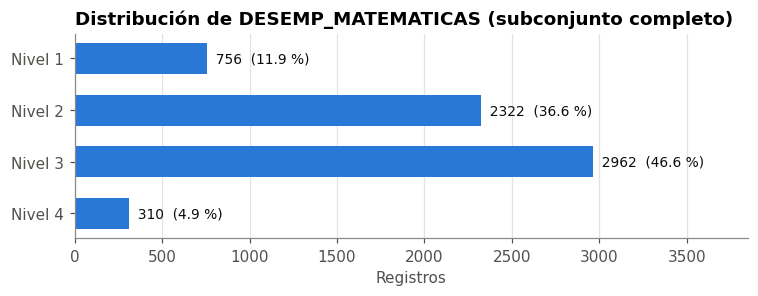

In [11]:
def graficar_distribucion_clases(y, titulo="Distribución de clases", ax=None):
    """Barras horizontales con el número de registros por clase y su porcentaje.
    Se reutiliza para mostrar las versiones balanceadas y desbalanceadas."""
    y = pd.Series(y)
    if pd.api.types.is_numeric_dtype(y):          # etiquetas codificadas 0..3 -> nombres
        y = y.map(dict(enumerate(CLASES)))
    conteo = y.value_counts().reindex(CLASES, fill_value=0)
    pct = conteo / conteo.sum() * 100
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 2.8))
    ax.barh(conteo.index, conteo.values, color=COLOR_PRINCIPAL, height=0.6)
    for i, (n, p) in enumerate(zip(conteo.values, pct.values)):
        ax.text(n, i, f"  {n}  ({p:.1f} %)", va="center", color="#0b0b0b", fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, conteo.max() * 1.3)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Registros")
    ax.set_title(titulo, loc="left")
    return ax


tabla_clases = pd.DataFrame({
    "Registros": df[OBJETIVO].value_counts().reindex(CLASES),
    "%": (df[OBJETIVO].value_counts(normalize=True).reindex(CLASES) * 100).round(2),
})
display(tabla_clases)
graficar_distribucion_clases(df[OBJETIVO], "Distribución de DESEMP_MATEMATICAS (subconjunto completo)")
plt.tight_layout()
plt.show()

### 3.3 Estadísticas descriptivas

In [12]:
print("Variables numéricas:")
display(df[VARIABLES_NUMERICAS].describe().T.round(2))

print("Variables categóricas:")
display(df.drop(columns=VARIABLES_NUMERICAS).describe().T)

Variables numéricas:


,count,mean,std,min,25%,50%,75%,max
PUNT_LECTURA_CRITICA,6350.0,52.99,10.81,0.0,45.0,53.0,61.0,100.0
PUNT_C_NATURALES,6350.0,48.99,10.47,25.0,41.0,48.0,56.0,100.0
PUNT_SOCIALES_CIUDADANAS,6350.0,47.72,12.02,19.0,38.0,47.0,57.0,100.0
PUNT_INGLES,6320.0,50.19,13.36,0.0,39.0,49.0,59.0,100.0
EDAD,6345.0,17.30,2.94,13.0,16.0,17.0,18.0,67.0


Variables categóricas:


,count,unique,top,freq
COLE_AREA_UBICACION,6350,2,URBANO,5272
COLE_BILINGUE,5224,2,N,5135
COLE_CARACTER,6079,4,ACADÉMICO,3265
COLE_DEPTO_UBICACION,6350,33,BOGOTÁ,968
COLE_GENERO,6350,3,MIXTO,6184
COLE_JORNADA,6350,6,MAÑANA,2492
COLE_NATURALEZA,6350,2,OFICIAL,4780
COLE_SEDE_PRINCIPAL,6350,2,S,6006
ESTU_GENERO,6350,2,F,3421
FAMI_CUARTOSHOGAR,6054,6,Dos,2344


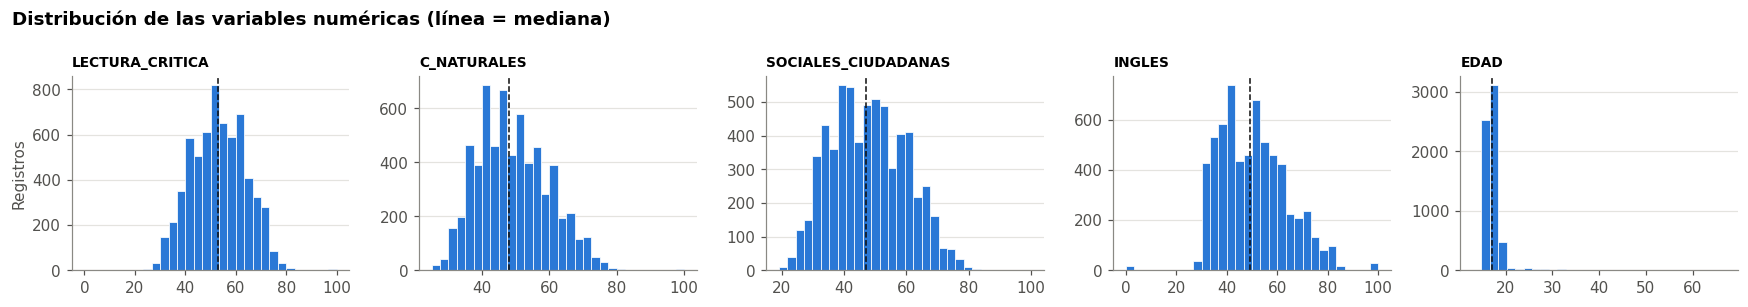

In [13]:
def graficar_histogramas(df, columnas, titulo):
    """Histogramas de las variables numéricas (uno por panel), con la mediana marcada."""
    fig, axes = plt.subplots(1, len(columnas), figsize=(3.2 * len(columnas), 2.8))
    for ax, col in zip(axes, columnas):
        datos = df[col].dropna()
        ax.hist(datos, bins=30, color=COLOR_PRINCIPAL, edgecolor="white", linewidth=0.5)
        ax.axvline(datos.median(), color="#0b0b0b", linestyle="--", linewidth=1)
        ax.set_title(col.replace("PUNT_", ""), fontsize=9, loc="left")
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("Registros")
    fig.suptitle(titulo, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()


graficar_histogramas(df, VARIABLES_NUMERICAS, "Distribución de las variables numéricas (línea = mediana)")

### 3.4 Valores nulos
Cuenta los nulos por variable y compara las filas con nulos con las filas completas, para decidir entre eliminar e imputar.

Variables con nulos: 13 de 24
Filas con al menos un nulo: 2161 (34.0%)


,Nulos,%
COLE_BILINGUE,1126,17.73
FAMI_EDUCACIONPADRE,877,13.81
FAMI_EDUCACIONMADRE,525,8.27
FAMI_ESTRATOVIVIENDA,448,7.06
FAMI_TIENEINTERNET,370,5.83
FAMI_TIENEAUTOMOVIL,305,4.80
FAMI_CUARTOSHOGAR,296,4.66
FAMI_TIENELAVADORA,290,4.57
FAMI_TIENECOMPUTADOR,288,4.54
FAMI_PERSONASHOGAR,287,4.52


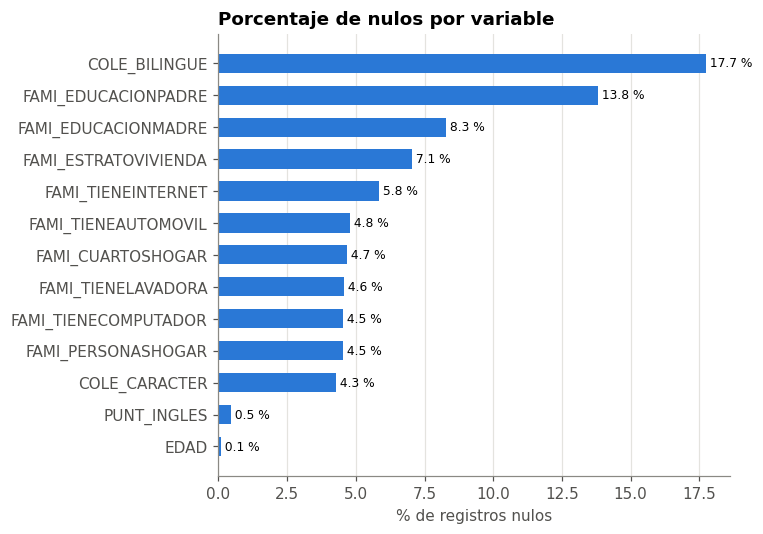

In [14]:
def tabla_nulos(df):
    """Cantidad y porcentaje de nulos por variable (solo las que tienen nulos)."""
    nulos = df.isna().sum()
    tabla = pd.DataFrame({"Nulos": nulos, "%": (nulos / len(df) * 100).round(2)})
    return tabla[tabla["Nulos"] > 0].sort_values("Nulos", ascending=False)


nulos = tabla_nulos(df)
filas_con_nulos = df.isna().any(axis=1).sum()
print(f"Variables con nulos: {len(nulos)} de {df.shape[1]}")
print(f"Filas con al menos un nulo: {filas_con_nulos} ({filas_con_nulos / len(df):.1%})")
display(nulos)

fig, ax = plt.subplots(figsize=(7, 0.32 * len(nulos) + 0.8))
ax.barh(nulos.index, nulos["%"], color=COLOR_PRINCIPAL, height=0.6)
for i, p in enumerate(nulos["%"]):
    ax.text(p, i, f" {p:.1f} %", va="center", fontsize=8)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("% de registros nulos")
ax.set_title("Porcentaje de nulos por variable", loc="left")
plt.tight_layout()
plt.show()

In [15]:
def comparar_filas_con_nulos(df, columnas=("COLE_AREA_UBICACION", "COLE_NATURALEZA")):
    """Compara la distribución del objetivo y de algunas variables de contexto entre
    las filas con al menos un nulo y las filas completas (% por fila)."""
    tiene_nulo = df.isna().any(axis=1).map({False: "Sin nulos", True: "Con nulos"})
    tablas = [pd.crosstab(tiene_nulo, df[OBJETIVO], normalize="index")]
    tablas += [pd.crosstab(tiene_nulo, df[c], normalize="index") for c in columnas]
    tabla = (pd.concat(tablas, axis=1) * 100).round(1)
    tabla.insert(0, "Registros", tiene_nulo.value_counts())
    tabla.index.name = None
    return tabla


comparar_filas_con_nulos(df)

,Registros,Nivel 1,Nivel 2,Nivel 3,Nivel 4,RURAL,URBANO,NO OFICIAL,OFICIAL
Con nulos,2161,14.8,39.5,41.7,4.0,21.9,78.1,30.3,69.7
Sin nulos,4189,10.4,35.1,49.2,5.3,14.4,85.6,21.9,78.1


### 3.5 Matriz de correlación
Correlación de Spearman entre las numéricas, las ordinales (codificadas según su orden) y el objetivo.

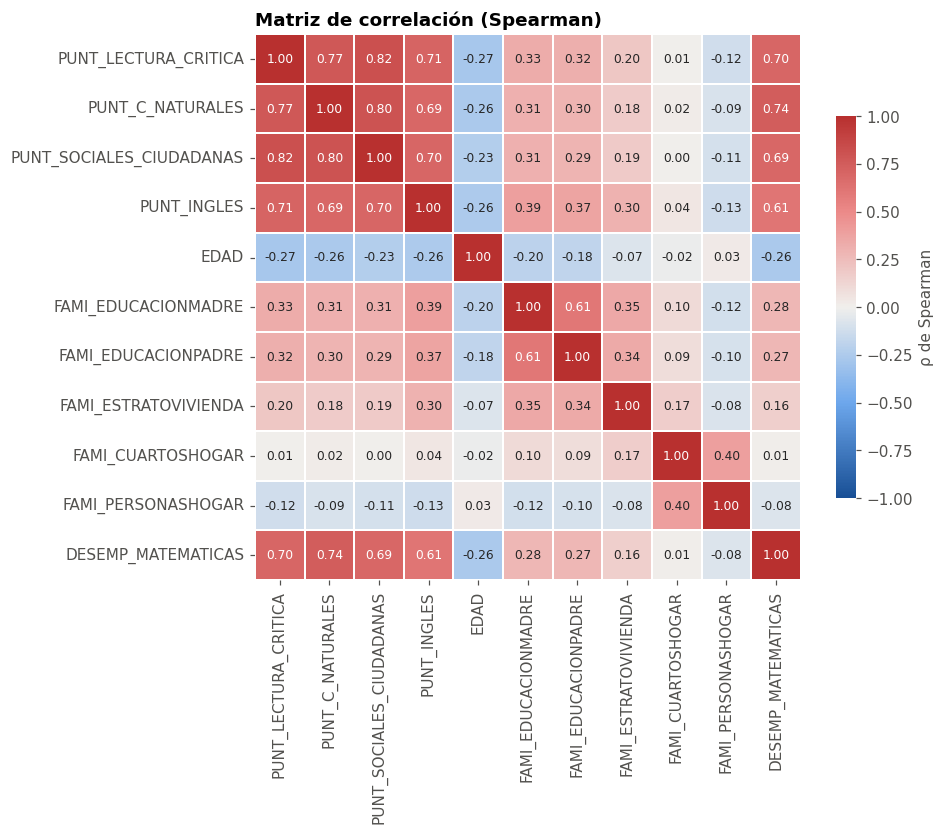

Correlación de cada variable con el objetivo:


,DESEMP_MATEMATICAS
PUNT_C_NATURALES,0.744
PUNT_LECTURA_CRITICA,0.700
PUNT_SOCIALES_CIUDADANAS,0.694
PUNT_INGLES,0.609
FAMI_EDUCACIONMADRE,0.275
FAMI_EDUCACIONPADRE,0.274
FAMI_ESTRATOVIVIENDA,0.161
FAMI_CUARTOSHOGAR,0.014
FAMI_PERSONASHOGAR,-0.075
EDAD,-0.261


In [16]:
def codificar_ordinales_para_eda(df):
    """Versión numérica del dataset solo para el EDA: ordinales y objetivo
    reemplazados por su posición en el orden (los nulos se mantienen como NaN)."""
    datos = df[VARIABLES_NUMERICAS].copy()
    for col, orden in VARIABLES_ORDINALES.items():
        datos[col] = df[col].map({v: i for i, v in enumerate(orden)})
    datos[OBJETIVO] = df[OBJETIVO].map({c: i + 1 for i, c in enumerate(CLASES)})
    return datos


datos_corr = codificar_ordinales_para_eda(df)
matriz_corr = datos_corr.corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap=CMAP_DIVERGENTE, vmin=-1, vmax=1,
            center=0, linewidths=1, linecolor="white", square=True,
            annot_kws={"fontsize": 8}, cbar_kws={"shrink": 0.7, "label": "ρ de Spearman"}, ax=ax)
ax.set_title("Matriz de correlación (Spearman)", loc="left")
ax.grid(False)
plt.tight_layout()
plt.show()

print("Correlación de cada variable con el objetivo:")
matriz_corr[OBJETIVO].drop(OBJETIVO).sort_values(ascending=False).round(3)

### 3.6 Hallazgos del EDA
*Documento, sección 2.2.*

## 4. Partición y preprocesamiento: las 8 versiones de la Figura 1
Todo ajuste que aprende de los datos se hace solo con el entrenamiento. Validación y prueba solo se transforman, y la prueba es la misma en los 8 casos. *Justificación de cada técnica y del orden de los pasos: documento, sección 3.*

| Paso | Qué se hace | Se ajusta con |
|---|---|---|
| 1. Partición | 70 / 15 / 15 estratificada, `random_state = 79` | — (una sola vez) |
| 2. Imputación | Mediana (numéricas) y moda (categóricas) | Entrenamiento base |
| 3. Outliers NO | Se **eliminan** las filas detectadas con IQR | Límites IQR del entrenamiento base |
| 4. CC ordinal | Cada ordinal se reemplaza por su posición en el orden del dominio | Orden fijo (no aprende de los datos) |
| 5. Balanceo | NO → submuestreo a ~70 % de Nivel 3 · SI → SMOTENC | Entrenamiento del caso |
| 6. Outliers SI | Se conservan los reales y se **inyectan** sintéticos hasta llegar al 5 % | Límites IQR del entrenamiento base |
| 7. CC One-Hot | Variables nominales | Entrenamiento base |
| 8. ED | StandardScaler sobre numéricas y ordinales (solo casos 5–8) | Entrenamiento del caso |

### 4.1 Partición estratificada 70 / 15 / 15
Partición única y estratificada con `random_state = 79`. Las etiquetas se codifican como enteros (Nivel 1 → 0, …, Nivel 4 → 3); los nombres están en `CLASES`.

In [17]:
def particionar(df, semilla=SEMILLA):
    """Divide el dataset limpio en entrenamiento (70 %), validación (15 %) y prueba (15 %),
    estratificando por la etiqueta. Retorna X_train, X_val, X_test, y_train, y_val, y_test."""
    X = df.drop(columns=OBJETIVO)
    y = df[OBJETIVO].map({c: i for i, c in enumerate(CLASES)}).astype(int)
    X_train, X_tmp, y_train, y_tmp = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=semilla)
    X_val, X_test, y_val, y_test = train_test_split(
        X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=semilla)
    return X_train, X_val, X_test, y_train, y_val, y_test


X_train_0, X_val_0, X_test_0, y_train_0, y_val_0, y_test_0 = particionar(df)
# La partición coincide con la usada en la limpieza para detectar casi constantes (sección 2)
assert set(X_train_0.index) == set(INDICES_TRAIN), "La partición no coincide con INDICES_TRAIN"

resumen_particion = pd.DataFrame({
    nombre: {"Registros": len(y), "% del total": round(len(y) / len(df) * 100, 1),
             **{c: f"{p:.1f} %" for c, p in zip(CLASES, y.value_counts(normalize=True).sort_index() * 100)}}
    for nombre, y in [("Entrenamiento", y_train_0), ("Validación", y_val_0), ("Prueba", y_test_0)]
}).T
resumen_particion

,Registros,% del total,Nivel 1,Nivel 2,Nivel 3,Nivel 4
Entrenamiento,4445,70.0,11.9 %,36.6 %,46.7 %,4.9 %
Validación,952,15.0,11.9 %,36.6 %,46.6 %,4.9 %
Prueba,953,15.0,12.0 %,36.6 %,46.6 %,4.8 %


### 4.2 Imputación de nulos
Moda para las categóricas y mediana para las numéricas, calculadas con el entrenamiento.

In [18]:
def ajustar_imputacion(X_train):
    """Calcula el valor de relleno de cada columna con el entrenamiento:
    la mediana si es numérica y la moda si es categórica."""
    return {col: (X_train[col].median() if col in VARIABLES_NUMERICAS else X_train[col].mode()[0])
            for col in X_train.columns}


def aplicar_imputacion(X, valores):
    """Rellena los nulos de X con los valores aprendidos en el entrenamiento."""
    return X.fillna(value=valores)


VALORES_IMPUTACION = ajustar_imputacion(X_train_0)
X_train_imp = aplicar_imputacion(X_train_0, VALORES_IMPUTACION)
X_val_imp = aplicar_imputacion(X_val_0, VALORES_IMPUTACION)
X_test_imp = aplicar_imputacion(X_test_0, VALORES_IMPUTACION)

print("Nulos restantes -> train:", X_train_imp.isna().sum().sum(),
      "| val:", X_val_imp.isna().sum().sum(), "| test:", X_test_imp.isna().sum().sum())
pd.Series({c: VALORES_IMPUTACION[c] for c in tabla_nulos(df).index}, name="Valor de imputación").to_frame()

Nulos restantes -> train: 0 | val: 0 | test: 0


,Valor de imputación
COLE_BILINGUE,N
FAMI_EDUCACIONPADRE,Secundaria (Bachillerato) completa
FAMI_EDUCACIONMADRE,Secundaria (Bachillerato) completa
FAMI_ESTRATOVIVIENDA,Estrato 2
FAMI_TIENEINTERNET,Si
FAMI_TIENEAUTOMOVIL,No
FAMI_CUARTOSHOGAR,Dos
FAMI_TIENELAVADORA,Si
FAMI_TIENECOMPUTADOR,Si
FAMI_PERSONASHOGAR,3 a 4


### 4.3 Conversión de categóricas (CC)
Codificación ordinal para las 5 variables con orden (*Sin Estrato* en la posición más baja) y One-Hot para las 13 nominales (`drop="if_binary"`, `handle_unknown="ignore"`), ajustado una sola vez con el entrenamiento base para que los 8 casos tengan las mismas 65 columnas.

In [19]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def codificar_ordinales(X):
    """Reemplaza cada variable ordinal por su posición (0, 1, 2, ...) en el orden
    definido en VARIABLES_ORDINALES."""
    X = X.copy()
    for col, orden in VARIABLES_ORDINALES.items():
        X[col] = X[col].map({v: i for i, v in enumerate(orden)}).astype(int)
    return X


def ajustar_one_hot(X_train):
    """Ajusta el codificador One-Hot de las variables nominales con el entrenamiento."""
    encoder = OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)
    encoder.fit(X_train[VARIABLES_NOMINALES])
    return encoder


def aplicar_one_hot(X, encoder):
    """Aplica el One-Hot a las nominales y conserva numéricas y ordinales.
    Retorna un DataFrame con nombres de columna legibles."""
    dummies = pd.DataFrame(encoder.transform(X[VARIABLES_NOMINALES]),
                           columns=encoder.get_feature_names_out(VARIABLES_NOMINALES),
                           index=X.index)
    return pd.concat([X[VARIABLES_NUMERICAS + list(VARIABLES_ORDINALES)], dummies], axis=1)


X_train_base = codificar_ordinales(X_train_imp)     # entrenamiento base: imputado + ordinal
X_val_base = codificar_ordinales(X_val_imp)
X_test_base = codificar_ordinales(X_test_imp)
ENCODER_OH = ajustar_one_hot(X_train_base)

COLUMNAS_A_ESCALAR = VARIABLES_NUMERICAS + list(VARIABLES_ORDINALES)
print(f"Columnas tras CC: {aplicar_one_hot(X_train_base.head(), ENCODER_OH).shape[1]} "
      f"({len(VARIABLES_NUMERICAS)} numéricas + {len(VARIABLES_ORDINALES)} ordinales + "
      f"{len(ENCODER_OH.get_feature_names_out())} dummies One-Hot)")
X_train_base[list(VARIABLES_ORDINALES)].head()

Columnas tras CC: 65 (5 numéricas + 5 ordinales + 55 dummies One-Hot)


,FAMI_EDUCACIONMADRE,FAMI_EDUCACIONPADRE,FAMI_ESTRATOVIVIENDA,FAMI_CUARTOSHOGAR,FAMI_PERSONASHOGAR
420,5,6,1,3,2
1533,4,4,2,1,1
5011,4,4,2,1,1
5166,4,6,2,1,1
2560,3,4,0,1,1


### 4.4 Escalado (ED)
StandardScaler sobre las numéricas y las ordinales, ajustado con el entrenamiento de cada caso (casos 5–8). Las dummies quedan en 0/1.

In [20]:
def ajustar_escalado(X_train, columnas=COLUMNAS_A_ESCALAR):
    """Ajusta un StandardScaler sobre las columnas indicadas del entrenamiento."""
    return StandardScaler().fit(X_train[columnas])


def aplicar_escalado(X, scaler, columnas=COLUMNAS_A_ESCALAR):
    """Aplica el escalador ya ajustado a las columnas indicadas; el resto queda igual."""
    X = X.copy()
    X[columnas] = scaler.transform(X[columnas])
    return X

### 4.5 Outliers
Detección con IQR (factor 1.5) sobre las 5 numéricas, con límites calculados en el entrenamiento base.
- *Sin outliers:* se eliminan las filas detectadas.
- *Con outliers:* se conservan los reales y se inyectan sintéticos hasta el 5 % del entrenamiento final, cambiando 1 o 2 variables numéricas por fila por un valor fuera de los límites IQR, pero posible (0–100 en los puntajes y 13–80 en la edad).

In [21]:
# Rango posible de cada variable numérica (los valores inyectados deben ser plausibles)
DOMINIO_NUMERICAS = {"PUNT_LECTURA_CRITICA": (0, 100), "PUNT_C_NATURALES": (0, 100),
                     "PUNT_SOCIALES_CIUDADANAS": (0, 100), "PUNT_INGLES": (0, 100),
                     "EDAD": (EDAD_MIN, EDAD_MAX)}   # mismo rango que la limpieza de EDAD
PROPORCION_OUTLIERS = 0.05


def calcular_limites_iqr(X, columnas=VARIABLES_NUMERICAS, factor=1.5):
    """Calcula Q1, Q3, IQR y los límites inferior y superior de cada columna."""
    q1, q3 = X[columnas].quantile(0.25), X[columnas].quantile(0.75)
    iqr = q3 - q1
    return pd.DataFrame({"Q1": q1, "Q3": q3, "IQR": iqr,
                         "Límite inferior": q1 - factor * iqr,
                         "Límite superior": q3 + factor * iqr})


def detectar_outliers(X, limites):
    """Retorna una máscara booleana: True si la fila tiene al menos un valor fuera de los límites."""
    columnas = limites.index
    fuera = (X[columnas] < limites["Límite inferior"]) | (X[columnas] > limites["Límite superior"])
    return fuera.any(axis=1)


LIMITES_IQR = calcular_limites_iqr(X_train_base)
mascara_base = detectar_outliers(X_train_base, LIMITES_IQR)
tabla_outliers = LIMITES_IQR.copy()
tabla_outliers["Outliers en train"] = [
    ((X_train_base[c] < LIMITES_IQR.loc[c, "Límite inferior"]) |
     (X_train_base[c] > LIMITES_IQR.loc[c, "Límite superior"])).sum() for c in LIMITES_IQR.index]
print(f"Filas de entrenamiento con al menos un outlier: {mascara_base.sum()} "
      f"de {len(X_train_base)} ({mascara_base.mean():.2%})")
tabla_outliers.round(2)

Filas de entrenamiento con al menos un outlier: 137 de 4445 (3.08%)


,Q1,Q3,IQR,Límite inferior,Límite superior,Outliers en train
PUNT_LECTURA_CRITICA,45.0,61.0,16.0,21.0,85.0,5
PUNT_C_NATURALES,41.0,57.0,16.0,17.0,81.0,2
PUNT_SOCIALES_CIUDADANAS,38.0,57.0,19.0,9.5,85.5,0
PUNT_INGLES,39.0,59.0,20.0,9.0,89.0,25
EDAD,16.0,18.0,2.0,13.0,21.0,107


In [22]:
def eliminar_outliers(X, y, limites=None):
    """Elimina las filas con al menos un outlier (IQR). Retorna X, y y la cantidad eliminada."""
    limites = LIMITES_IQR if limites is None else limites
    mascara = detectar_outliers(X, limites)
    return X[~mascara], y[~mascara], int(mascara.sum())


def inyectar_outliers(X, y, proporcion=PROPORCION_OUTLIERS, limites=None, semilla=SEMILLA):
    """Completa los outliers del entrenamiento hasta que representen `proporcion` de las filas.

    Conserva los outliers ya presentes (reales o generados por SMOTE) e inyecta los faltantes modificando filas no atípicas:
    a cada fila elegida se le cambian 1 o 2 variables numéricas por un valor entero
    uniforme en la zona atípica (fuera de los límites IQR, dentro de DOMINIO_NUMERICAS).
    Retorna X, y y un diccionario con el reporte (reales, inyectados, total, %)."""
    limites = LIMITES_IQR if limites is None else limites
    rng = np.random.default_rng(semilla)
    X = X.copy()
    X[VARIABLES_NUMERICAS] = X[VARIABLES_NUMERICAS].astype(float)

    mascara = detectar_outliers(X, limites)
    n_reales = int(mascara.sum())
    n_objetivo = int(np.ceil(proporcion * len(X)))
    n_inyectar = max(0, n_objetivo - n_reales)

    filas = rng.choice(np.where(~mascara.values)[0], size=n_inyectar, replace=False)
    variables_usadas = []
    for fila in filas:
        columnas = rng.choice(VARIABLES_NUMERICAS, size=rng.integers(1, 3), replace=False)
        for col in columnas:
            minimo, maximo = DOMINIO_NUMERICAS[col]
            bajo = (minimo, int(np.ceil(limites.loc[col, "Límite inferior"])) - 1)
            alto = (int(np.floor(limites.loc[col, "Límite superior"])) + 1, maximo)
            zonas = [z for z in (bajo, alto) if z[0] <= z[1]]          # zonas no vacías
            inicio, fin = zonas[rng.integers(len(zonas))]
            X.iloc[fila, X.columns.get_loc(col)] = rng.integers(inicio, fin + 1)
            variables_usadas.append(col)

    total = int(detectar_outliers(X, limites).sum())
    reporte = {"Outliers previos": n_reales, "Outliers inyectados": n_inyectar,
               "Outliers totales": total, "% outliers": round(total / len(X) * 100, 2),
               "Variables modificadas": pd.Series(variables_usadas, dtype=str).value_counts().to_dict()}
    return X, y, reporte

### 4.6 Balanceo
- *Desbalanceado:* submuestreo a 70/10/10/10, con Nivel 3 como clase mayoritaria.
- *Balanceado:* SMOTENC hasta igualar la clase mayoritaria.

Ambos se aplican solo al entrenamiento.

In [23]:
from imblearn.over_sampling import SMOTENC

CLASE_MAYORITARIA = CLASES.index("Nivel 3")   # código 2
PROPORCION_MAYORITARIA = 0.70


def desbalancear(X, y, clase_mayoritaria=CLASE_MAYORITARIA,
                 proporcion=PROPORCION_MAYORITARIA, semilla=SEMILLA):
    """Submuestrea para que la clase mayoritaria tenga `proporcion` de los registros y
    las demás se repartan el resto en partes iguales. La clase minoritaria más pequeña
    determina cuántos registros toma cada clase no mayoritaria."""
    conteos = y.value_counts()
    otras = [c for c in conteos.index if c != clase_mayoritaria]
    n_otra = conteos[otras].min()
    n_mayor = int(round(n_otra * len(otras) * proporcion / (1 - proporcion)))
    if n_mayor > conteos[clase_mayoritaria]:          # si no alcanza la mayoritaria, se recorta el resto
        n_mayor = conteos[clase_mayoritaria]
        n_otra = int(round(n_mayor * (1 - proporcion) / (proporcion * len(otras))))
    objetivo = {clase_mayoritaria: n_mayor, **{c: n_otra for c in otras}}
    indices = pd.concat([y[y == c].sample(n=n, random_state=semilla) for c, n in objetivo.items()]).index
    indices = indices.to_series().sample(frac=1, random_state=semilla).index   # mezclar el orden
    return X.loc[indices], y.loc[indices]


def balancear_smote(X, y, semilla=SEMILLA, k_vecinos=5):
    """Balancea con SMOTENC (nominales como categóricas) hasta igualar todas las clases
    a la mayoritaria. Redondea las ordinales al entero más cercano."""
    indices_nominales = [X.columns.get_loc(c) for c in VARIABLES_NOMINALES]
    smote = SMOTENC(categorical_features=indices_nominales, k_neighbors=k_vecinos,
                    random_state=semilla)
    X_res, y_res = smote.fit_resample(X, y)
    X_res = pd.DataFrame(X_res, columns=X.columns)
    for col, orden in VARIABLES_ORDINALES.items():
        X_res[col] = X_res[col].round().clip(0, len(orden) - 1).astype(int)
    return X_res, pd.Series(y_res, name=y.name)

### 4.7 Construcción de los 8 casos
`construir_casos()` devuelve `casos[1..8]`, el formato común para las secciones 5, 6 y 8:

| Clave | Contenido |
|---|---|
| `X_train`, `X_val`, `X_test` | DataFrames codificados (y escalados en los casos 5–8) |
| `y_train`, `y_val`, `y_test` | Series de enteros 0–3 (`CLASES[i]` da el nombre) |
| `normalizacion`, `outliers`, `balanceo` | La fila correspondiente de la Figura 1 |
| `scaler` | El StandardScaler ajustado, o `None` |
| `reporte` | Registros eliminados o inyectados y distribución de clases |

In [24]:
# Configuración de la Figura 1: (ED, outliers, balanceo)
CONFIG_CASOS = {
    1: (False, False, False), 2: (False, False, True),
    3: (False, True,  False), 4: (False, True,  True),
    5: (True,  False, False), 6: (True,  False, True),
    7: (True,  True,  False), 8: (True,  True,  True),
}


def construir_caso(numero):
    """Construye el caso `numero` de la Figura 1 a partir del entrenamiento base
    (imputado y con ordinales codificados) y lo devuelve como diccionario."""
    escalado, con_outliers, balanceado = CONFIG_CASOS[numero]
    X, y = X_train_base.copy(), y_train_0.copy()
    reporte = {}

    # Outliers NO: se eliminan antes de balancear
    if not con_outliers:
        X, y, reporte["Filas eliminadas (outliers)"] = eliminar_outliers(X, y)

    # Balanceo
    X, y = balancear_smote(X, y) if balanceado else desbalancear(X, y)

    # Outliers SI: se completan hasta el 5 % del entrenamiento final
    if con_outliers:
        X, y, rep = inyectar_outliers(X, y)
        reporte.update(rep)
    reporte["% outliers (IQR)"] = round(detectar_outliers(X, LIMITES_IQR).mean() * 100, 2)

    # CC One-Hot (mismo codificador para todos los casos)
    X_train = aplicar_one_hot(X, ENCODER_OH)
    X_val = aplicar_one_hot(X_val_base, ENCODER_OH)
    X_test = aplicar_one_hot(X_test_base, ENCODER_OH)

    # ED: StandardScaler ajustado con el entrenamiento del caso
    scaler = None
    if escalado:
        scaler = ajustar_escalado(X_train)
        X_train, X_val, X_test = (aplicar_escalado(d, scaler) for d in (X_train, X_val, X_test))

    reporte["Distribución train"] = (y.value_counts().sort_index()
                                     .rename(index=dict(enumerate(CLASES))).to_dict())
    return {
        "X_train": X_train.reset_index(drop=True), "y_train": y.reset_index(drop=True),
        "X_val": X_val, "y_val": y_val_0, "X_test": X_test, "y_test": y_test_0,
        "normalizacion": f"CC(SI) y ED({'SI' if escalado else 'NO'})",
        "outliers": "SI" if con_outliers else "NO",
        "balanceo": "SI" if balanceado else "NO",
        "scaler": scaler, "reporte": reporte,
    }


def construir_casos():
    """Construye los 8 casos de la Figura 1. Retorna el diccionario casos[1..8]."""
    fijar_semillas()
    return {numero: construir_caso(numero) for numero in CONFIG_CASOS}


casos = construir_casos()

### 4.8 Verificación y resumen de los 8 casos

In [25]:
def resumen_casos(casos):
    """Tabla resumen de los 8 casos: configuración, tamaño, distribución de clases y % de outliers."""
    filas = []
    for k, c in casos.items():
        dist = c["y_train"].value_counts(normalize=True).sort_index() * 100
        filas.append({
            "Caso": k, "Normalización": c["normalizacion"], "Outliers": c["outliers"],
            "Balanceo": c["balanceo"], "Registros train": len(c["y_train"]),
            **{c_: f"{p:.1f} %" for c_, p in zip(CLASES, dist)},
            "% outliers": c["reporte"]["% outliers (IQR)"],
            "Inyectados": c["reporte"].get("Outliers inyectados", 0),
            "Eliminados": c["reporte"].get("Filas eliminadas (outliers)", 0),
            "Columnas": c["X_train"].shape[1],
            "Filas por columna": round(len(c["y_train"]) / c["X_train"].shape[1], 1),
        })
    return pd.DataFrame(filas).set_index("Caso")


# Verificaciones de consistencia
for k, c in casos.items():
    assert c["y_test"].equals(y_test_0), "El conjunto de prueba debe ser el mismo en los 8 casos"
    assert list(c["X_test"].index) == list(X_test_0.index)
    assert c["X_train"].isna().sum().sum() == 0
for k in range(1, 5):   # casos k y k+4 solo difieren en el escalado
    assert casos[k]["y_train"].equals(casos[k + 4]["y_train"])
print("Verificaciones OK: prueba idéntica en los 8 casos, sin nulos, casos k y k+4 con los mismos registros.")

resumen_casos(casos)

Verificaciones OK: prueba idéntica en los 8 casos, sin nulos, casos k y k+4 con los mismos registros.


,Normalización,Outliers,Balanceo,Registros train,Nivel 1,Nivel 2,Nivel 3,Nivel 4,% outliers,Inyectados,Eliminados,Columnas,Filas por columna
Caso,,,,,,,,,,,,,
1,CC(SI) y ED(NO),NO,NO,2050,10.0 %,10.0 %,70.0 %,10.0 %,0.00,0,137,65,31.5
2,CC(SI) y ED(NO),NO,SI,8208,25.0 %,25.0 %,25.0 %,25.0 %,0.00,0,137,65,126.3
3,CC(SI) y ED(NO),SI,NO,2170,10.0 %,10.0 %,70.0 %,10.0 %,5.02,54,0,65,33.4
4,CC(SI) y ED(NO),SI,SI,8296,25.0 %,25.0 %,25.0 %,25.0 %,5.00,47,0,65,127.6
5,CC(SI) y ED(SI),NO,NO,2050,10.0 %,10.0 %,70.0 %,10.0 %,0.00,0,137,65,31.5
6,CC(SI) y ED(SI),NO,SI,8208,25.0 %,25.0 %,25.0 %,25.0 %,0.00,0,137,65,126.3
7,CC(SI) y ED(SI),SI,NO,2170,10.0 %,10.0 %,70.0 %,10.0 %,5.02,54,0,65,33.4
8,CC(SI) y ED(SI),SI,SI,8296,25.0 %,25.0 %,25.0 %,25.0 %,5.00,47,0,65,127.6


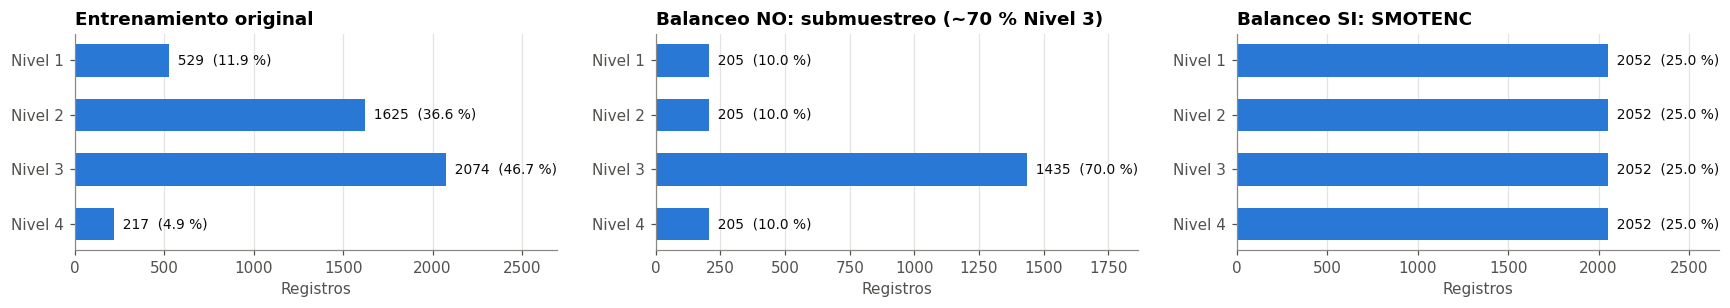

Reporte de outliers inyectados:


,Outliers previos,Outliers inyectados,Outliers totales,% outliers,Variables modificadas
3,55,54,109,5.02,"{'PUNT_SOCIALES_CIUDADANAS': 19, 'EDAD': 18, '..."
4,368,47,415,5.0,"{'PUNT_SOCIALES_CIUDADANAS': 16, 'EDAD': 15, '..."
7,55,54,109,5.02,"{'PUNT_SOCIALES_CIUDADANAS': 19, 'EDAD': 18, '..."
8,368,47,415,5.0,"{'PUNT_SOCIALES_CIUDADANAS': 16, 'EDAD': 15, '..."


In [26]:
# Distribución de clases resultante: desbalanceada vs. balanceada (sin outliers)
fig, axes = plt.subplots(1, 3, figsize=(16, 2.9))
graficar_distribucion_clases(y_train_0, "Entrenamiento original", ax=axes[0])
graficar_distribucion_clases(casos[1]["y_train"], "Balanceo NO: submuestreo (~70 % Nivel 3)", ax=axes[1])
graficar_distribucion_clases(casos[2]["y_train"], "Balanceo SI: SMOTENC", ax=axes[2])
plt.tight_layout()
plt.show()

print("Reporte de outliers inyectados:")
pd.DataFrame({k: casos[k]["reporte"] for k in (3, 4, 7, 8)}).T[
    ["Outliers previos", "Outliers inyectados", "Outliers totales", "% outliers", "Variables modificadas"]]

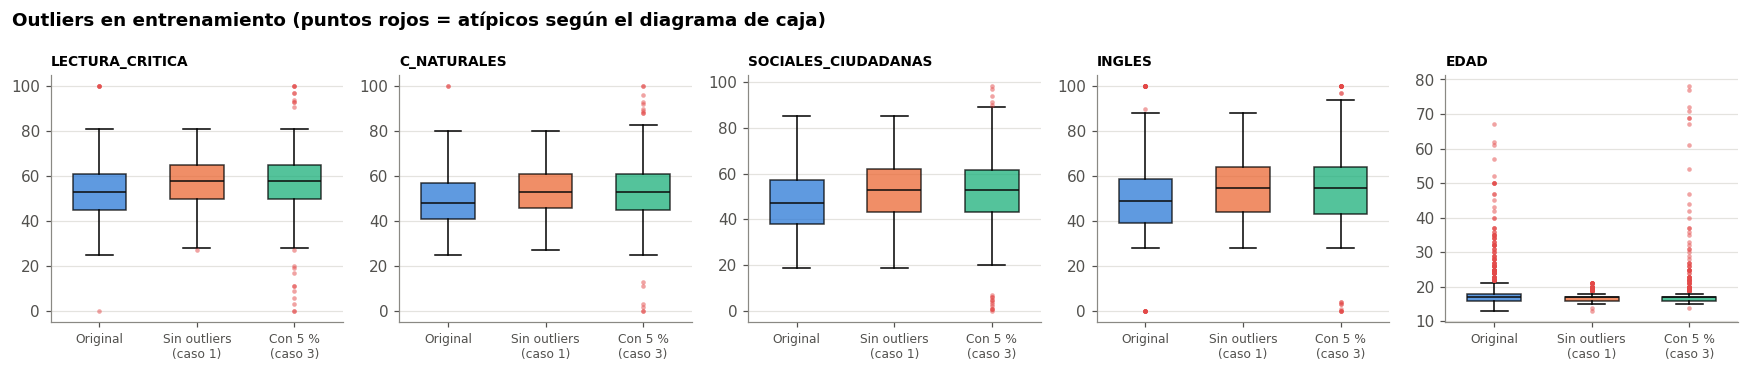

In [27]:
def graficar_outliers(versiones, columnas=VARIABLES_NUMERICAS):
    """Diagramas de caja de las numéricas en varias versiones del entrenamiento
    (sin escalar), para comparar el efecto de eliminar e inyectar outliers."""
    fig, axes = plt.subplots(1, len(columnas), figsize=(3.2 * len(columnas), 3.4))
    for ax, col in zip(axes, columnas):
        datos = [v[col].values for v in versiones.values()]
        caja = ax.boxplot(datos, patch_artist=True, widths=0.55,
                          flierprops={"marker": "o", "markersize": 3, "alpha": 0.5,
                                      "markerfacecolor": "#e34948", "markeredgecolor": "none"},
                          medianprops={"color": "#0b0b0b"})
        for patch, color in zip(caja["boxes"], COLORES_SERIES):
            patch.set_facecolor(color)
            patch.set_alpha(0.75)
        ax.set_xticks(range(1, len(versiones) + 1), list(versiones), fontsize=8)
        ax.set_title(col.replace("PUNT_", ""), fontsize=9, loc="left")
        ax.grid(axis="x", visible=False)
    fig.suptitle("Outliers en entrenamiento (puntos rojos = atípicos según el diagrama de caja)",
                 x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()


# Se comparan los casos 1 y 3: ambos sin escalar y con el MISMO balanceo (submuestreo),
# así la única diferencia entre ellos es el manejo de outliers. Los casos 2 y 4 pasan
# por SMOTE, que genera registros sintéticos y cambiaría la forma de las cajas.
graficar_outliers({"Original": X_train_base,
                   "Sin outliers\n(caso 1)": casos[1]["X_train"],
                   "Con 5 %\n(caso 3)": casos[3]["X_train"]})

### 4.9 Datos de prueba y datos del módulo no supervisado
- `obtener_datos_demo(caso)`: los 3 registros reales de prueba (uno de Nivel 1, uno de Nivel 3 y uno de Nivel 4).
- `obtener_datos_hipoteticos(caso)`: los 3 estudiantes construidos a mano (perfiles bajo, medio y alto), en la versión del caso.
- `obtener_datos_no_supervisado(caso)`: los registros de entrenamiento del caso sin la etiqueta, para la sección 8.

*Las dos lecturas de "3 datos de prueba": documento, sección 3.*

In [28]:
# Índices de los 3 registros de prueba de demostración (uno por clase extrema y uno central)
INDICES_DEMO = [y_test_0[y_test_0 == CLASES.index(c)].sample(1, random_state=SEMILLA).index[0]
                for c in ("Nivel 1", "Nivel 3", "Nivel 4")]


def obtener_datos_demo(numero, casos=casos):
    """Retorna (X, y) de los 3 registros de prueba de demostración en la versión del caso indicado."""
    c = casos[numero]
    return c["X_test"].loc[INDICES_DEMO], c["y_test"].loc[INDICES_DEMO]


def obtener_datos_no_supervisado(numero, casos=casos):
    """Sección 8: retorna (X, etiqueta_externa) del caso indicado.
    X son los registros de entrenamiento del caso (mismo CC, escalado y outliers) sin la
    variable objetivo; la etiqueta se usa ÚNICAMENTE para la validación externa."""
    c = casos[numero]
    return c["X_train"].copy(), c["y_train"].map(dict(enumerate(CLASES)))


X_demo, y_demo = obtener_datos_demo(8)
print("Registros de demostración (caso 8):", [CLASES[v] for v in y_demo])
X_demo.iloc[:, :8]

Registros de demostración (caso 8): ['Nivel 1', 'Nivel 3', 'Nivel 4']


,PUNT_LECTURA_CRITICA,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES,EDAD,FAMI_EDUCACIONMADRE,FAMI_EDUCACIONPADRE,FAMI_ESTRATOVIVIENDA
3576,-1.191977,-1.318805,-1.520853,-1.459107,3.564070,-1.460488,-1.307490,-0.951655
397,0.752427,0.372792,1.213265,0.880304,-0.117279,-0.173082,-0.001312,-0.037890
4354,0.453288,0.961174,0.051265,0.880304,0.145675,-0.173082,-0.001312,0.875875


In [29]:
# Los 3 estudiantes hipotéticos: datos de prueba nuevos, construidos a mano con los valores originales
# del Saber 11 (texto en las categóricas), como los "nuevos_datos" del notebook 5_02, el "nuevo vino"
# del 6-03 y la "nueva flor" del 6-04. Se usan en el módulo supervisado (7.5) y en el no supervisado (8.3.1).
ESTUDIANTES_HIPOTETICOS = pd.DataFrame([
    {"Perfil": "Perfil bajo",
     "PUNT_LECTURA_CRITICA": 38, "PUNT_C_NATURALES": 35, "PUNT_SOCIALES_CIUDADANAS": 33, "PUNT_INGLES": 36.0, "EDAD": 19.0,
     "FAMI_ESTRATOVIVIENDA": "Estrato 1", "FAMI_EDUCACIONMADRE": "Primaria completa",
     "FAMI_EDUCACIONPADRE": "Primaria incompleta", "FAMI_CUARTOSHOGAR": "Dos", "FAMI_PERSONASHOGAR": "5 a 6",
     "COLE_AREA_UBICACION": "RURAL", "COLE_BILINGUE": "N", "COLE_CARACTER": "ACADÉMICO",
     "COLE_DEPTO_UBICACION": "ANTIOQUIA", "COLE_GENERO": "MIXTO", "COLE_JORNADA": "MAÑANA",
     "COLE_NATURALEZA": "OFICIAL", "COLE_SEDE_PRINCIPAL": "N", "ESTU_GENERO": "M",
     "FAMI_TIENEAUTOMOVIL": "No", "FAMI_TIENECOMPUTADOR": "No", "FAMI_TIENEINTERNET": "No", "FAMI_TIENELAVADORA": "No"},
    {"Perfil": "Perfil medio",
     "PUNT_LECTURA_CRITICA": 55, "PUNT_C_NATURALES": 52, "PUNT_SOCIALES_CIUDADANAS": 50, "PUNT_INGLES": 50.0, "EDAD": 17.0,
     "FAMI_ESTRATOVIVIENDA": "Estrato 2", "FAMI_EDUCACIONMADRE": "Secundaria (Bachillerato) completa",
     "FAMI_EDUCACIONPADRE": "Secundaria (Bachillerato) completa", "FAMI_CUARTOSHOGAR": "Tres", "FAMI_PERSONASHOGAR": "3 a 4",
     "COLE_AREA_UBICACION": "URBANO", "COLE_BILINGUE": "N", "COLE_CARACTER": "TÉCNICO/ACADÉMICO",
     "COLE_DEPTO_UBICACION": "ANTIOQUIA", "COLE_GENERO": "MIXTO", "COLE_JORNADA": "UNICA",
     "COLE_NATURALEZA": "OFICIAL", "COLE_SEDE_PRINCIPAL": "S", "ESTU_GENERO": "F",
     "FAMI_TIENEAUTOMOVIL": "No", "FAMI_TIENECOMPUTADOR": "Si", "FAMI_TIENEINTERNET": "Si", "FAMI_TIENELAVADORA": "Si"},
    {"Perfil": "Perfil alto",
     "PUNT_LECTURA_CRITICA": 75, "PUNT_C_NATURALES": 73, "PUNT_SOCIALES_CIUDADANAS": 72, "PUNT_INGLES": 85.0, "EDAD": 16.0,
     "FAMI_ESTRATOVIVIENDA": "Estrato 5", "FAMI_EDUCACIONMADRE": "Educación profesional completa",
     "FAMI_EDUCACIONPADRE": "Postgrado", "FAMI_CUARTOSHOGAR": "Cuatro", "FAMI_PERSONASHOGAR": "3 a 4",
     "COLE_AREA_UBICACION": "URBANO", "COLE_BILINGUE": "S", "COLE_CARACTER": "ACADÉMICO",
     "COLE_DEPTO_UBICACION": "BOGOTÁ", "COLE_GENERO": "MIXTO", "COLE_JORNADA": "COMPLETA",
     "COLE_NATURALEZA": "NO OFICIAL", "COLE_SEDE_PRINCIPAL": "S", "ESTU_GENERO": "F",
     "FAMI_TIENEAUTOMOVIL": "Si", "FAMI_TIENECOMPUTADOR": "Si", "FAMI_TIENEINTERNET": "Si", "FAMI_TIENELAVADORA": "Si"},
]).set_index("Perfil")


def obtener_datos_hipoteticos(numero, casos=casos):
    """Retorna los 3 estudiantes hipotéticos en la versión del caso indicado: codificación ordinal,
    One-Hot con ENCODER_OH y, en los casos 5–8, el StandardScaler ajustado en ese caso. Quedan en las
    mismas 65 columnas, y en el mismo orden, que X_test del caso."""
    c = casos[numero]
    X = aplicar_one_hot(codificar_ordinales(ESTUDIANTES_HIPOTETICOS[X_test_base.columns]), ENCODER_OH)
    if c["scaler"] is not None:
        X = aplicar_escalado(X, c["scaler"])
    return X[c["X_test"].columns]


print("Estudiantes hipotéticos en la versión del caso 8 (primeras columnas):")
obtener_datos_hipoteticos(8).iloc[:, :8]

Estudiantes hipotéticos en la versión del caso 8 (primeras columnas):


,PUNT_LECTURA_CRITICA,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES,EDAD,FAMI_EDUCACIONMADRE,FAMI_EDUCACIONPADRE,FAMI_ESTRATOVIVIENDA
Perfil,,,,,,,,
Perfil bajo,-1.191977,-1.171710,-1.110735,-1.028163,0.408628,-1.031353,-1.307490,-0.951655
Perfil medio,0.079364,0.078601,0.051265,-0.166275,-0.117279,-0.173082,-0.001312,-0.037890
Perfil alto,1.575059,1.623103,1.555029,1.988445,-0.380232,1.543460,2.175652,2.703404


### 4.10 Registro de resultados (funciones comunes de evaluación)
- `registrar_resultado(algoritmo, caso, modelo)`: evalúa el modelo en la prueba del caso (accuracy, precisión, recall y F1 con promedio `macro`) y guarda las predicciones y las probabilidades.
- `registrar_clustering(tecnica, caso, X, etiquetas, modelo)`: inercia y silhouette (sin los puntos de ruido) para la Figura 3.
- `predecir_demo`, `reporte_por_clase`, `graficar_matriz_confusion`, `tabla_figura1` y `tabla_figura3`: funciones de apoyo con el mismo formato para todas las técnicas.

In [30]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, silhouette_score)

ALGORITMOS = ["Árboles", "KNN", "SVM", "Redes Neuronales"]   # nombres exactos (columnas de la Figura 1)
METRICAS = ["Accuracy", "Precision", "Recall", "F1"]
TECNICAS_CLUSTERING = ["K-Means", "DBSCAN"]

RESULTADOS = {}              # (algoritmo, caso) -> métricas, predicciones y probabilidades
RESULTADOS_CLUSTERING = {}   # (tecnica, caso)   -> inercia, silhouette, clusters, ruido


def _es_keras(modelo):
    """True si el modelo es de Keras/TensorFlow."""
    return "keras" in type(modelo).__module__


def predecir_con_probabilidades(modelo, X):
    """Devuelve (y_pred, y_proba) para un modelo de scikit-learn o de Keras.
    - scikit-learn: y_pred = predict(X), y_proba = predict_proba(X).
    - Keras: y_proba = predict(X) (salida softmax), y_pred = clase de mayor probabilidad."""
    if _es_keras(modelo):
        y_proba = np.asarray(modelo.predict(np.asarray(X, dtype="float32"), verbose=0))
        return y_proba.argmax(axis=1), y_proba
    if not hasattr(modelo, "predict_proba"):
        raise ValueError("El modelo no tiene predict_proba. En SVM use SVC(probability=True, "
                         "random_state=SEMILLA); las probabilidades se necesitan para las curvas ROC/PR.")
    return np.asarray(modelo.predict(X)).astype(int), np.asarray(modelo.predict_proba(X))


def registrar_resultado(algoritmo, caso, modelo, parametros=None, casos=casos):
    """Evalúa `modelo` (ya entrenado) sobre el conjunto de PRUEBA del `caso` y guarda el resultado.

    algoritmo  : uno de ALGORITMOS ("Árboles", "KNN", "SVM", "Redes Neuronales").
    caso       : entero de 1 a 8 (fila de la Figura 1).
    modelo     : modelo de scikit-learn (con predict_proba) o de Keras (salida softmax de 4 neuronas).
    parametros : dict opcional con los hiperparámetros elegidos (se muestra en la tabla final).

    Calcula Accuracy y Precision/Recall/F1 con promedio macro. Si el par (algoritmo, caso)
    ya estaba registrado, lo reemplaza. Retorna el diccionario de métricas."""
    if algoritmo not in ALGORITMOS:
        raise ValueError(f"algoritmo debe ser uno de {ALGORITMOS}, no '{algoritmo}'")
    if caso not in casos:
        raise ValueError(f"caso debe estar entre 1 y 8, no {caso}")

    X_test, y_test = casos[caso]["X_test"], casos[caso]["y_test"].to_numpy()
    y_pred, y_proba = predecir_con_probabilidades(modelo, X_test)
    if y_proba.shape != (len(y_test), len(CLASES)):
        raise ValueError(f"Las probabilidades deben tener forma {(len(y_test), len(CLASES))}, "
                         f"no {y_proba.shape}. La salida debe tener una columna por clase.")

    metricas = {
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1":        f1_score(y_test, y_pred, average="macro", zero_division=0),
    }
    if (algoritmo, caso) in RESULTADOS:
        print(f"Aviso: se reemplaza el resultado previo de {algoritmo} en el caso {caso}.")
    RESULTADOS[(algoritmo, caso)] = {**metricas, "y_pred": y_pred, "y_proba": y_proba,
                                     "parametros": parametros or {}}
    print(f"{algoritmo} | caso {caso} | " + " | ".join(f"{m}: {v:.4f}" for m, v in metricas.items()))
    return metricas


def tabla_figura1(resultados=RESULTADOS, casos=casos):
    """Tabla de la Figura 1: una fila por caso y, por algoritmo, Accuracy/Precision/Recall/F1.
    Las celdas sin resultado registrado quedan vacías (NaN)."""
    filas = {}
    for k, c in casos.items():
        fila = {("Configuración", "Normalización"): c["normalizacion"],
                ("Configuración", "Outliers"): c["outliers"],
                ("Configuración", "Balanceo"): c["balanceo"]}
        for alg in ALGORITMOS:
            r = resultados.get((alg, k), {})
            for m in METRICAS:
                fila[(alg, m)] = round(r[m], 4) if m in r else np.nan
        filas[k] = fila
    tabla = pd.DataFrame(filas).T
    tabla.columns = pd.MultiIndex.from_tuples(tabla.columns)
    tabla.index.name = "Caso"
    return tabla


def reporte_por_clase(algoritmo, caso, casos=casos):
    """Reporte de precisión, recall y F1 por clase de un resultado registrado."""
    r = RESULTADOS[(algoritmo, caso)]
    reporte = classification_report(casos[caso]["y_test"], r["y_pred"], target_names=CLASES,
                                    output_dict=True, zero_division=0)
    return pd.DataFrame(reporte).T.round(4)


def graficar_matriz_confusion(algoritmo, caso, ax=None, casos=casos):
    """Matriz de confusión (conteos) de un resultado registrado, con los nombres de las clases."""
    r = RESULTADOS[(algoritmo, caso)]
    matriz = confusion_matrix(casos[caso]["y_test"], r["y_pred"], labels=range(len(CLASES)))
    if ax is None:
        _, ax = plt.subplots(figsize=(4.6, 3.9))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=1,
                linecolor="white", xticklabels=CLASES, yticklabels=CLASES, ax=ax)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.set_title(f"{algoritmo} – caso {caso}", loc="left")
    ax.grid(False)
    return ax


def predecir_demo(algoritmo, caso, modelo):
    """Evaluación de los 3 datos de prueba de demostración (INDICES_DEMO): clase real,
    clase predicha y probabilidad de cada clase."""
    X_demo, y_demo = obtener_datos_demo(caso)
    y_pred, y_proba = predecir_con_probabilidades(modelo, X_demo)
    tabla = pd.DataFrame(y_proba.round(3), columns=[f"P({c})" for c in CLASES], index=X_demo.index)
    tabla.insert(0, "Predicho", [CLASES[p] for p in y_pred])
    tabla.insert(0, "Real", [CLASES[v] for v in y_demo])
    tabla.insert(0, "Técnica", f"{algoritmo} (caso {caso})")
    return tabla


def registrar_clustering(tecnica, caso, X, etiquetas, modelo=None, parametros=None):
    """Registra un agrupamiento para la Figura 3.

    tecnica   : "K-Means" o "DBSCAN".
    X         : los datos usados para agrupar (de obtener_datos_no_supervisado(caso)).
    etiquetas : etiqueta de cluster de cada registro (en DBSCAN, -1 = ruido).
    modelo    : el modelo ajustado (en K-Means se toma su inertia_).

    El silhouette excluye el ruido (-1) y requiere al menos 2 clusters; si no se cumple, queda NaN."""
    if tecnica not in TECNICAS_CLUSTERING:
        raise ValueError(f"tecnica debe ser una de {TECNICAS_CLUSTERING}, no '{tecnica}'")
    etiquetas = np.asarray(etiquetas)
    no_ruido = etiquetas != -1
    n_clusters = len(set(etiquetas[no_ruido]))
    silhouette = (silhouette_score(np.asarray(X)[no_ruido], etiquetas[no_ruido], random_state=SEMILLA)
                  if n_clusters >= 2 else np.nan)
    inercia = getattr(modelo, "inertia_", np.nan) if tecnica == "K-Means" else np.nan
    RESULTADOS_CLUSTERING[(tecnica, caso)] = {
        "Inertia": inercia, "Silhouette": silhouette, "Clusters": n_clusters,
        "Ruido": int((~no_ruido).sum()), "parametros": parametros or {}}
    print(f"{tecnica} | caso {caso} | clusters: {n_clusters} | ruido: {int((~no_ruido).sum())} | "
          f"inercia: {inercia:.2f} | silhouette: {silhouette:.4f}")
    return RESULTADOS_CLUSTERING[(tecnica, caso)]


def tabla_figura3(casos=casos):
    """Tabla de la Figura 3: inercia y silhouette de K-Means y silhouette de DBSCAN por caso."""
    filas = {}
    for k, c in casos.items():
        km = RESULTADOS_CLUSTERING.get(("K-Means", k), {})
        db = RESULTADOS_CLUSTERING.get(("DBSCAN", k), {})
        filas[k] = {"Normalización": c["normalizacion"], "Outliers": c["outliers"],
                    "Balanceo": c["balanceo"],
                    "K-Means Inertia": km.get("Inertia", np.nan),
                    "K-Means Silhouette": km.get("Silhouette", np.nan),
                    "DBSCAN Silhouette": db.get("Silhouette", np.nan)}
    tabla = pd.DataFrame(filas).T
    tabla.index.name = "Caso"
    return tabla


print(f"Funciones de evaluación listas. Algoritmos: {ALGORITMOS} | Técnicas de clustering: {TECNICAS_CLUSTERING}")
print(f"Resultados registrados: {len(RESULTADOS)} supervisados, {len(RESULTADOS_CLUSTERING)} de clustering")

Funciones de evaluación listas. Algoritmos: ['Árboles', 'KNN', 'SVM', 'Redes Neuronales'] | Técnicas de clustering: ['K-Means', 'DBSCAN']
Resultados registrados: 0 supervisados, 0 de clustering


## 5. Árboles de decisión y KNN
Árboles (`DecisionTreeClassifier`) y KNN (`KNeighborsClassifier`) en los 8 casos, como en los notebooks de clase `5_01` y `5_02`. Los hiperparámetros se eligen sin mirar la prueba. *Análisis: documento, secciones 4.1, 4.2 y 4.5.*

### 5.1 Árboles de decisión
#### 5.1.1 Profundidad máxima y criterio (Gini frente a entropía)
`max_depth` de 1 a 15 con Gini y con entropía. Se elige la profundidad con mayor accuracy de validación (en empate, la menor) y se registra el árbol con Gini.

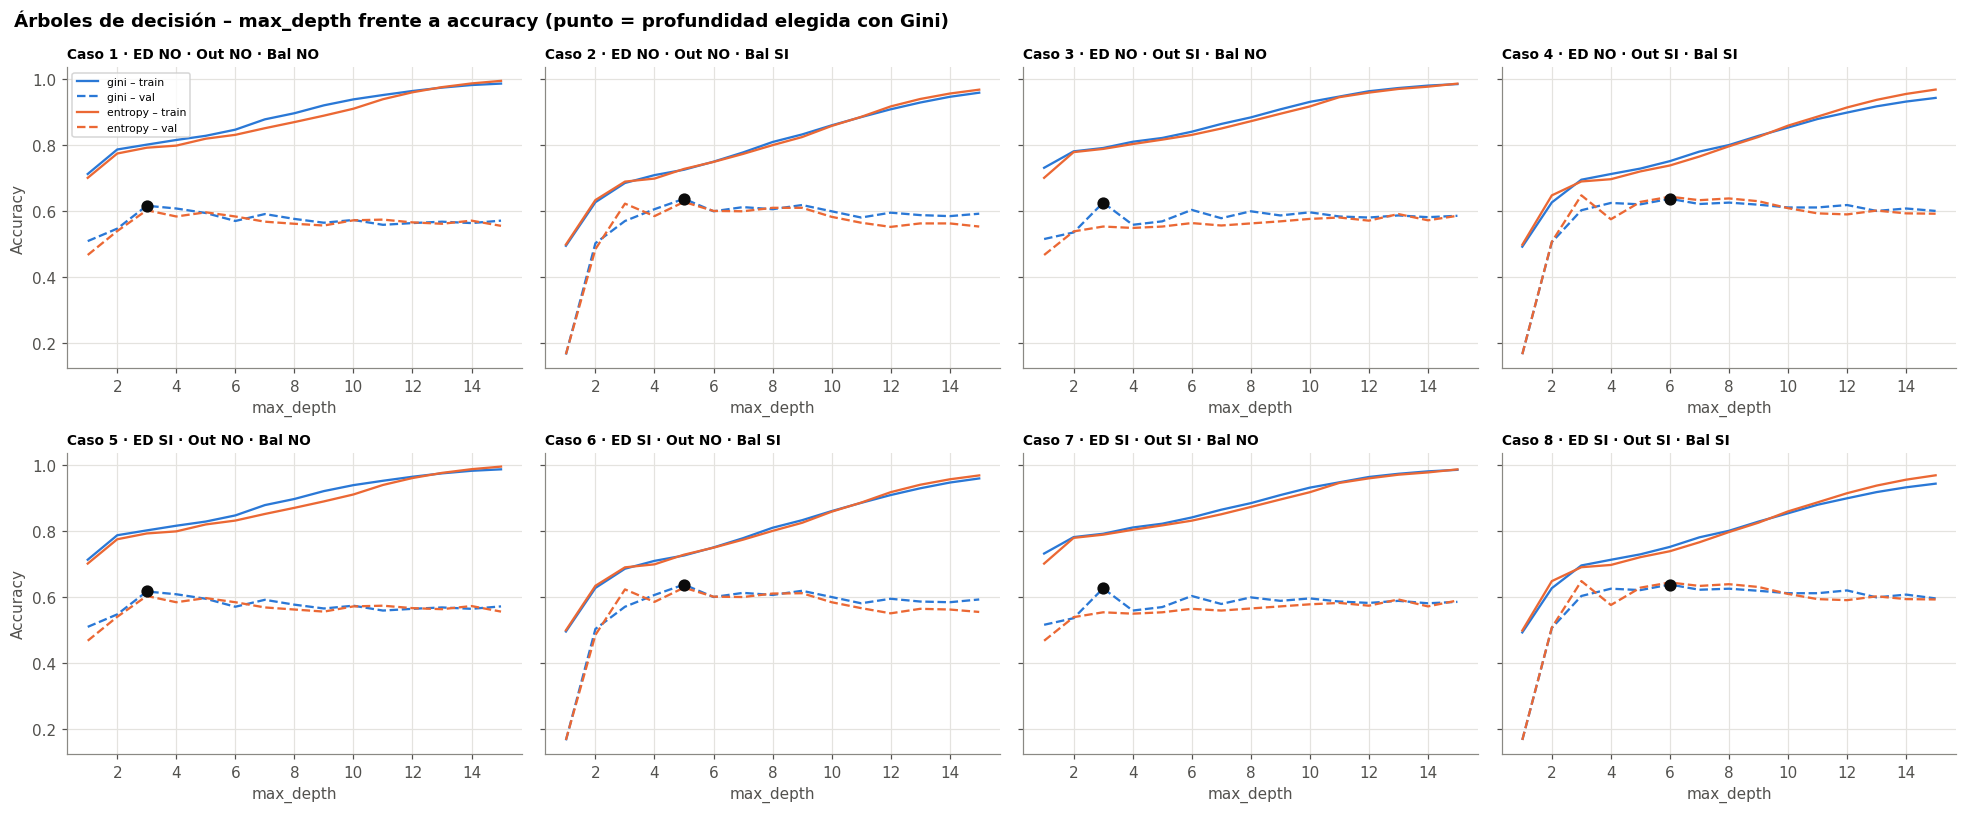

,Gini: max_depth,Gini: Accuracy train,Gini: Accuracy val,Gini: F1 val,Entropía: max_depth,Entropía: Accuracy train,Entropía: Accuracy val,Entropía: F1 val
Caso,,,,,,,,
1,3,0.8005,0.6155,0.5434,3,0.7912,0.6019,0.5304
2,5,0.7245,0.6366,0.6026,5,0.7270,0.6271,0.5835
3,3,0.7903,0.6250,0.5505,13,0.9691,0.5903,0.5222
4,6,0.7506,0.6366,0.5901,3,0.6890,0.6471,0.6086
5,3,0.8005,0.6155,0.5434,3,0.7912,0.6019,0.5304
6,5,0.7245,0.6366,0.6026,5,0.7270,0.6271,0.5835
7,3,0.7903,0.6250,0.5505,13,0.9691,0.5914,0.5238
8,6,0.7506,0.6366,0.5901,3,0.6890,0.6471,0.6086


In [31]:
# ============================================================
# 5.1 Árboles de decisión: max_depth y criterio con el conjunto de validación
# ============================================================
from sklearn.tree import DecisionTreeClassifier, plot_tree

PROFUNDIDADES_ARBOL = list(range(1, 16))   # profundidades evaluadas (de 1 a 15)
CRITERIOS_ARBOL = ["gini", "entropy"]


def curva_profundidad(caso, criterio, profundidades=PROFUNDIDADES_ARBOL):
    """Entrena un árbol por profundidad con el entrenamiento del caso y retorna una tabla con
    el accuracy de entrenamiento y de validación (y el F1 macro de validación, como referencia).
    Es el procedimiento del notebook de clase 5_01, medido en validación y no en prueba."""
    d = casos[caso]
    filas = []
    for profundidad in profundidades:
        arbol = DecisionTreeClassifier(criterion=criterio, max_depth=profundidad, random_state=SEMILLA)
        arbol.fit(d["X_train"], d["y_train"])
        y_pred_val = arbol.predict(d["X_val"])
        filas.append({"max_depth": profundidad,
                      "Accuracy train": accuracy_score(d["y_train"], arbol.predict(d["X_train"])),
                      "Accuracy val": accuracy_score(d["y_val"], y_pred_val),
                      "F1 val": f1_score(d["y_val"], y_pred_val, average="macro")})
    return pd.DataFrame(filas)


def mejor_profundidad(curva):
    """Profundidad con el mayor accuracy de validación; en empate, la menor (árbol más simple)."""
    return int(curva.sort_values(["Accuracy val", "max_depth"], ascending=[False, True]).iloc[0]["max_depth"])


# Curvas de los 8 casos con los dos criterios
CURVAS_ARBOL = {(k, criterio): curva_profundidad(k, criterio) for k in casos for criterio in CRITERIOS_ARBOL}


def graficar_profundidad(curvas=CURVAS_ARBOL):
    """max_depth frente a accuracy de entrenamiento (línea continua) y de validación (línea
    discontinua) para Gini y entropía en los 8 casos. El punto marca la profundidad elegida con Gini."""
    fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), sharey=True)
    for ax, k in zip(axes.ravel(), casos):
        for i, criterio in enumerate(CRITERIOS_ARBOL):
            curva = curvas[(k, criterio)]
            ax.plot(curva["max_depth"], curva["Accuracy train"], "-", color=COLORES_SERIES[i],
                    label=f"{criterio} – train")
            ax.plot(curva["max_depth"], curva["Accuracy val"], "--", color=COLORES_SERIES[i],
                    label=f"{criterio} – val")
        p = mejor_profundidad(curvas[(k, "gini")])
        ax.plot(p, curvas[(k, "gini")].set_index("max_depth").loc[p, "Accuracy val"], "o",
                color="#0b0b0b", markersize=7)
        c = casos[k]
        ax.set_title(f"Caso {k} · ED {c['normalizacion'][-3:-1]} · Out {c['outliers']} · Bal {c['balanceo']}",
                     loc="left", fontsize=9)
        ax.set_xlabel("max_depth")
    for ax in axes[:, 0]:
        ax.set_ylabel("Accuracy")
    axes[0, 0].legend(fontsize=7)
    fig.suptitle("Árboles de decisión – max_depth frente a accuracy (punto = profundidad elegida con Gini)",
                 x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


def comparar_criterios(curvas=CURVAS_ARBOL):
    """Por caso y criterio: profundidad elegida y sus métricas de entrenamiento y validación."""
    filas = []
    for k in casos:
        fila = {"Caso": k}
        for criterio in CRITERIOS_ARBOL:
            curva = curvas[(k, criterio)].set_index("max_depth")
            p = mejor_profundidad(curvas[(k, criterio)])
            nombre = "Gini" if criterio == "gini" else "Entropía"
            fila.update({f"{nombre}: max_depth": p,
                         f"{nombre}: Accuracy train": round(curva.loc[p, "Accuracy train"], 4),
                         f"{nombre}: Accuracy val": round(curva.loc[p, "Accuracy val"], 4),
                         f"{nombre}: F1 val": round(curva.loc[p, "F1 val"], 4)})
        filas.append(fila)
    return pd.DataFrame(filas).set_index("Caso")


graficar_profundidad()
display(comparar_criterios())

#### 5.1.2 Árbol final (Gini) en los 8 casos
Entrena y registra el árbol con Gini y la profundidad elegida.

In [32]:
# Árbol final de cada caso: criterio Gini con la profundidad elegida en validación
MODELOS_ARBOL = {}   # caso -> árbol registrado
for k in casos:
    p = mejor_profundidad(CURVAS_ARBOL[(k, "gini")])
    MODELOS_ARBOL[k] = DecisionTreeClassifier(criterion="gini", max_depth=p, random_state=SEMILLA)
    MODELOS_ARBOL[k].fit(casos[k]["X_train"], casos[k]["y_train"])
    registrar_resultado("Árboles", k, MODELOS_ARBOL[k], {"criterion": "gini", "max_depth": p})

Árboles | caso 1 | Accuracy: 0.6055 | Precision: 0.6056 | Recall: 0.5424 | F1: 0.5371
Árboles | caso 2 | Accuracy: 0.6159 | Precision: 0.5533 | Recall: 0.6293 | F1: 0.5771
Árboles | caso 3 | Accuracy: 0.6170 | Precision: 0.6181 | Recall: 0.5247 | F1: 0.5306
Árboles | caso 4 | Accuracy: 0.6317 | Precision: 0.5631 | Recall: 0.6674 | F1: 0.5915
Árboles | caso 5 | Accuracy: 0.6055 | Precision: 0.6056 | Recall: 0.5424 | F1: 0.5371
Árboles | caso 6 | Accuracy: 0.6159 | Precision: 0.5533 | Recall: 0.6293 | F1: 0.5771
Árboles | caso 7 | Accuracy: 0.6170 | Precision: 0.6181 | Recall: 0.5247 | F1: 0.5306
Árboles | caso 8 | Accuracy: 0.6317 | Precision: 0.5631 | Recall: 0.6674 | F1: 0.5915


#### 5.1.3 Evaluación de los 3 datos de prueba

In [33]:
# Evaluación de los 3 datos de prueba de demostración en los 8 casos
display(pd.concat([predecir_demo("Árboles", k, MODELOS_ARBOL[k]) for k in casos]))

,Técnica,Real,Predicho,P(Nivel 1),P(Nivel 2),P(Nivel 3),P(Nivel 4)
3576,Árboles (caso 1),Nivel 1,Nivel 1,0.736,0.207,0.057,0.000
397,Árboles (caso 1),Nivel 3,Nivel 3,0.001,0.025,0.920,0.054
4354,Árboles (caso 1),Nivel 4,Nivel 3,0.001,0.025,0.920,0.054
3576,Árboles (caso 2),Nivel 1,Nivel 1,0.823,0.171,0.006,0.000
397,Árboles (caso 2),Nivel 3,Nivel 3,0.000,0.086,0.832,0.082
4354,Árboles (caso 2),Nivel 4,Nivel 3,0.007,0.037,0.889,0.066
3576,Árboles (caso 3),Nivel 1,Nivel 1,0.768,0.173,0.060,0.000
397,Árboles (caso 3),Nivel 3,Nivel 3,0.004,0.036,0.913,0.047
4354,Árboles (caso 3),Nivel 4,Nivel 3,0.004,0.036,0.913,0.047
3576,Árboles (caso 4),Nivel 1,Nivel 1,0.881,0.113,0.005,0.000


#### 5.1.4 Importancia de características

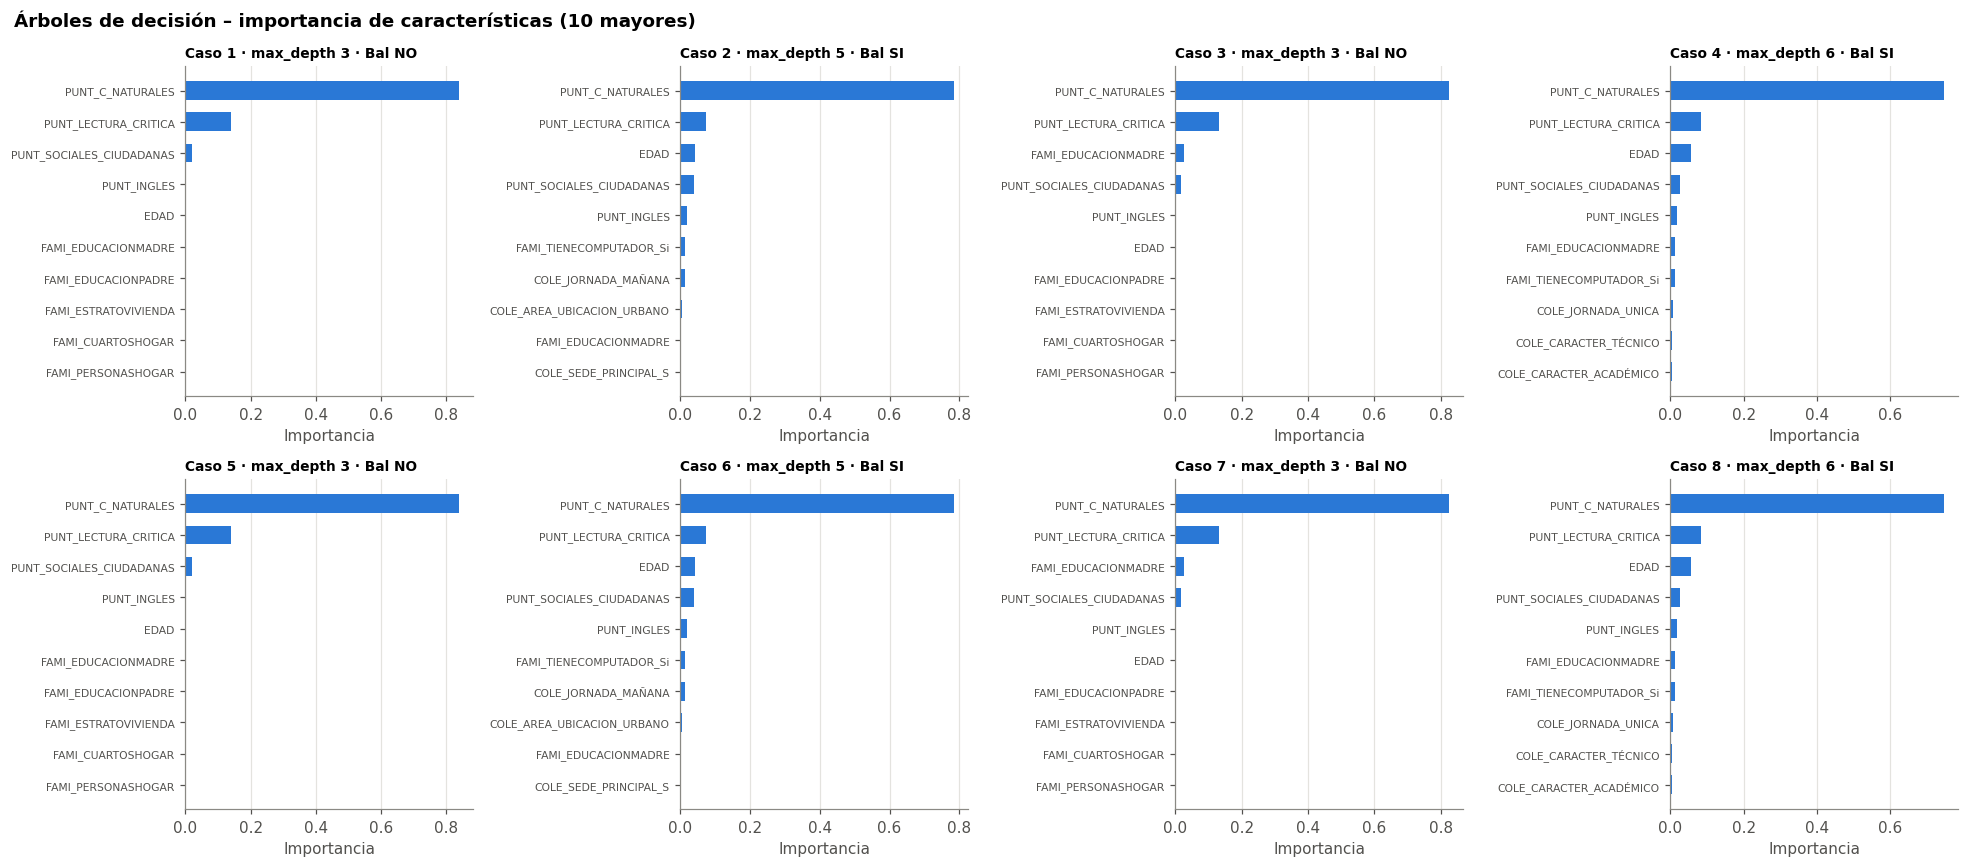

,EDAD,FAMI_EDUCACIONMADRE,PUNT_C_NATURALES,PUNT_LECTURA_CRITICA,PUNT_SOCIALES_CIUDADANAS
Caso,,,,,
1,0.000,0.000,0.840,0.139,0.021
2,0.043,0.003,0.786,0.074,0.039
3,0.000,0.025,0.826,0.132,0.017
4,0.057,0.013,0.747,0.085,0.027
5,0.000,0.000,0.840,0.139,0.021
6,0.043,0.003,0.786,0.074,0.039
7,0.000,0.025,0.826,0.132,0.017
8,0.057,0.013,0.747,0.085,0.027


In [34]:
def graficar_importancias(modelos=MODELOS_ARBOL, n=10):
    """Las n características con mayor importancia (feature_importances_, notebook 5_01) del
    árbol registrado en cada caso."""
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, k in zip(axes.ravel(), casos):
        importancia = pd.Series(modelos[k].feature_importances_, index=casos[k]["X_train"].columns)
        top = importancia.nlargest(n).iloc[::-1]
        ax.barh(top.index, top.values, color=COLOR_PRINCIPAL, height=0.6)
        ax.tick_params(axis="y", labelsize=7)
        ax.grid(axis="y", visible=False)
        c = casos[k]
        ax.set_title(f"Caso {k} · max_depth {modelos[k].max_depth} · Bal {c['balanceo']}", loc="left", fontsize=9)
        ax.set_xlabel("Importancia")
    fig.suptitle("Árboles de decisión – importancia de características (10 mayores)",
                 x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


graficar_importancias()

# Importancia por caso de las variables que aparecen en algún top 3
importancias = pd.DataFrame({k: MODELOS_ARBOL[k].feature_importances_ for k in casos},
                            index=casos[1]["X_train"].columns).T.rename_axis("Caso")
top3 = sorted({v for k in casos for v in importancias.loc[k].nlargest(3).index})
display(importancias[top3].round(3))

#### 5.1.5 Árbol solución con criterio Gini
`plot_tree` del árbol registrado de cada caso (3 primeros niveles). En los casos 5 a 8, los umbrales de las numéricas y las ordinales están estandarizados.

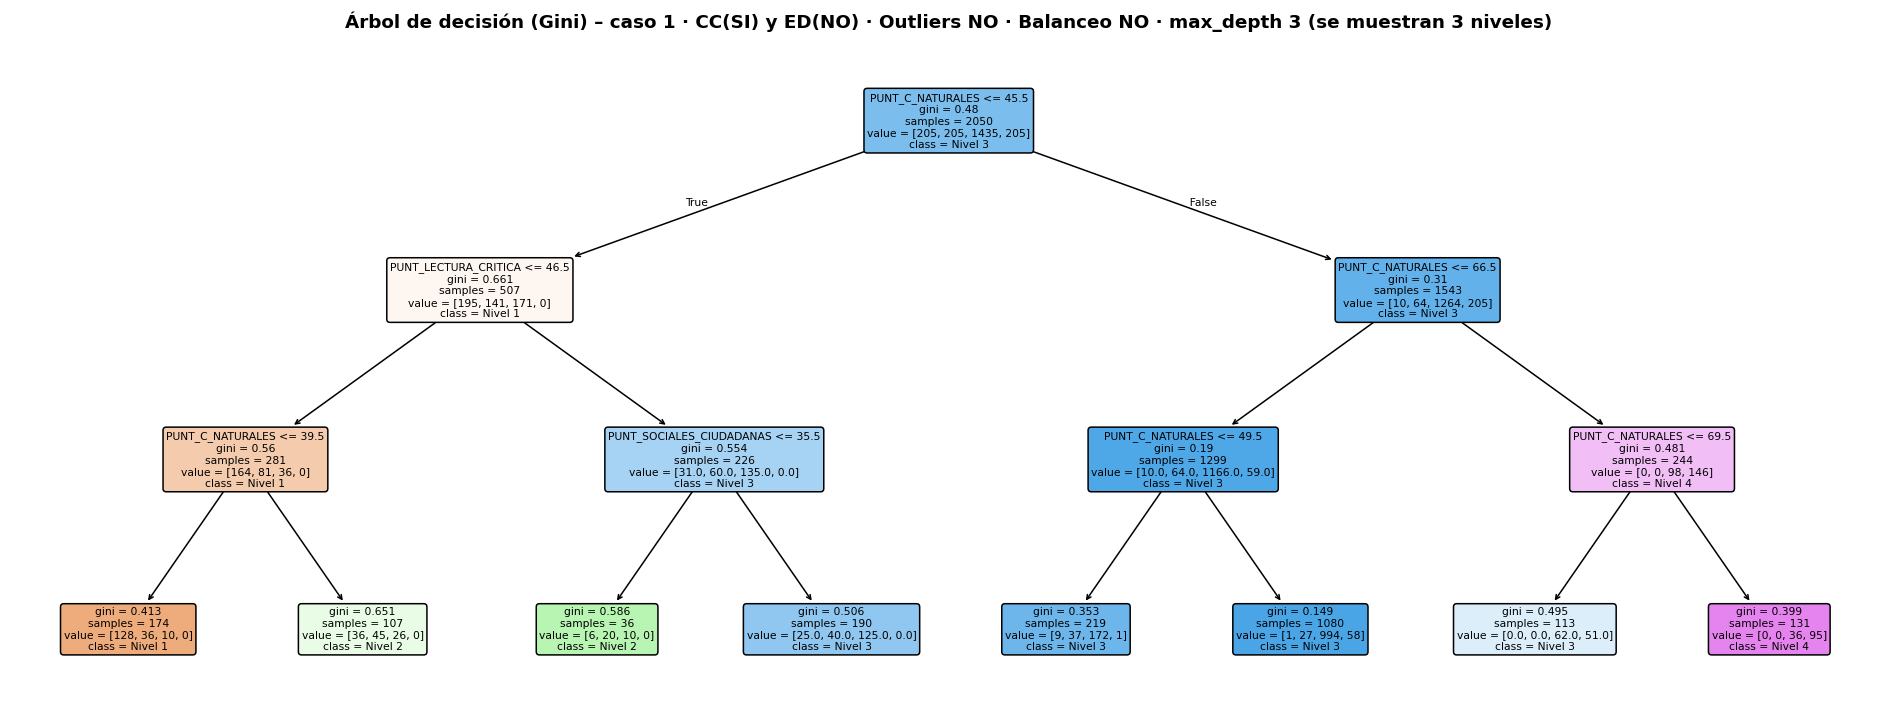

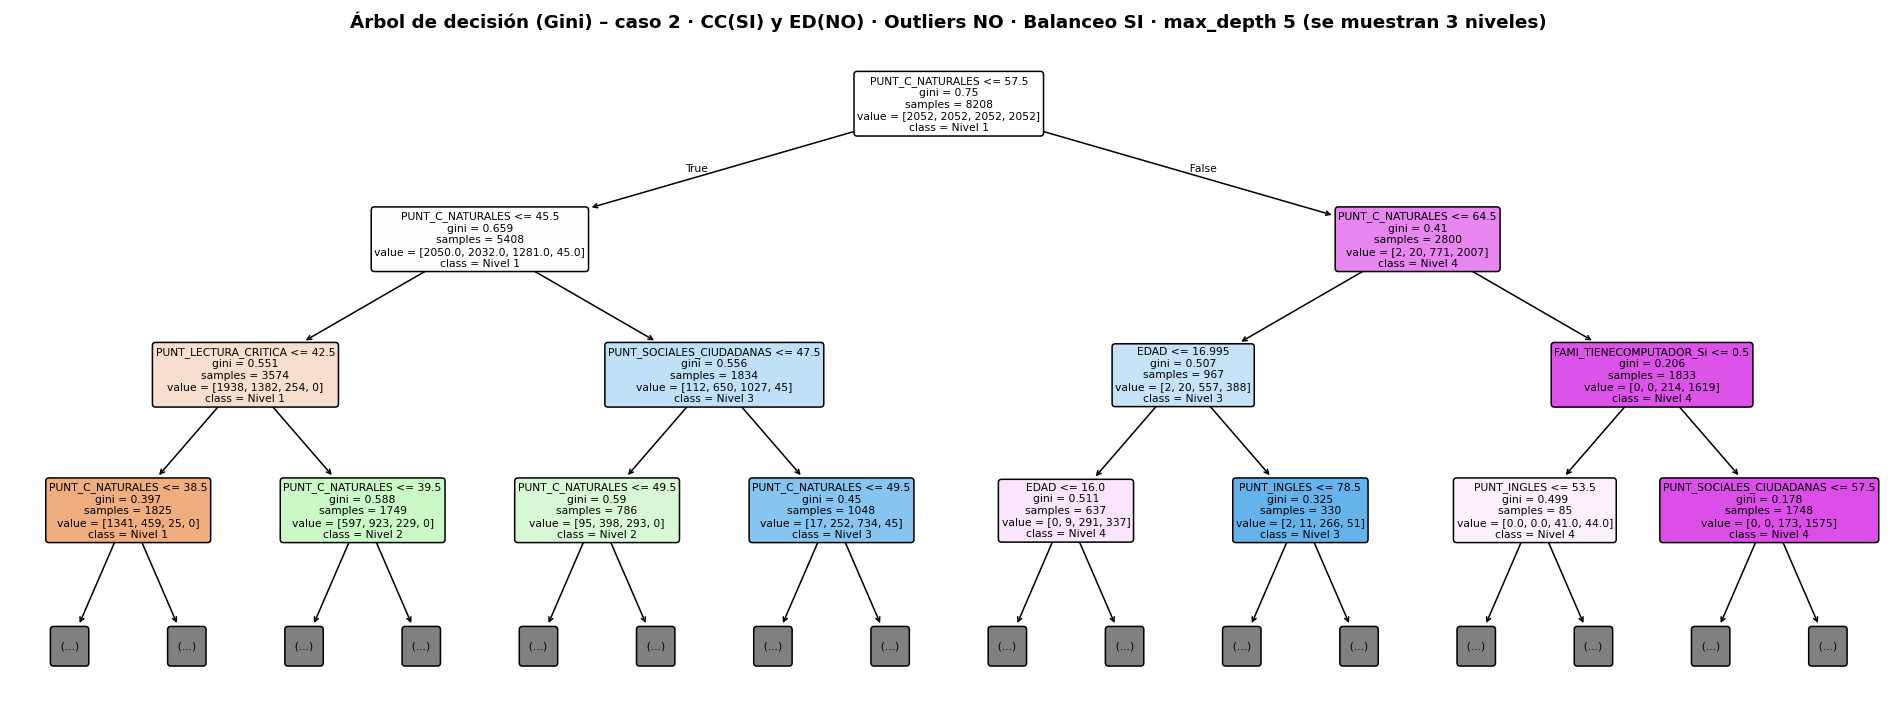

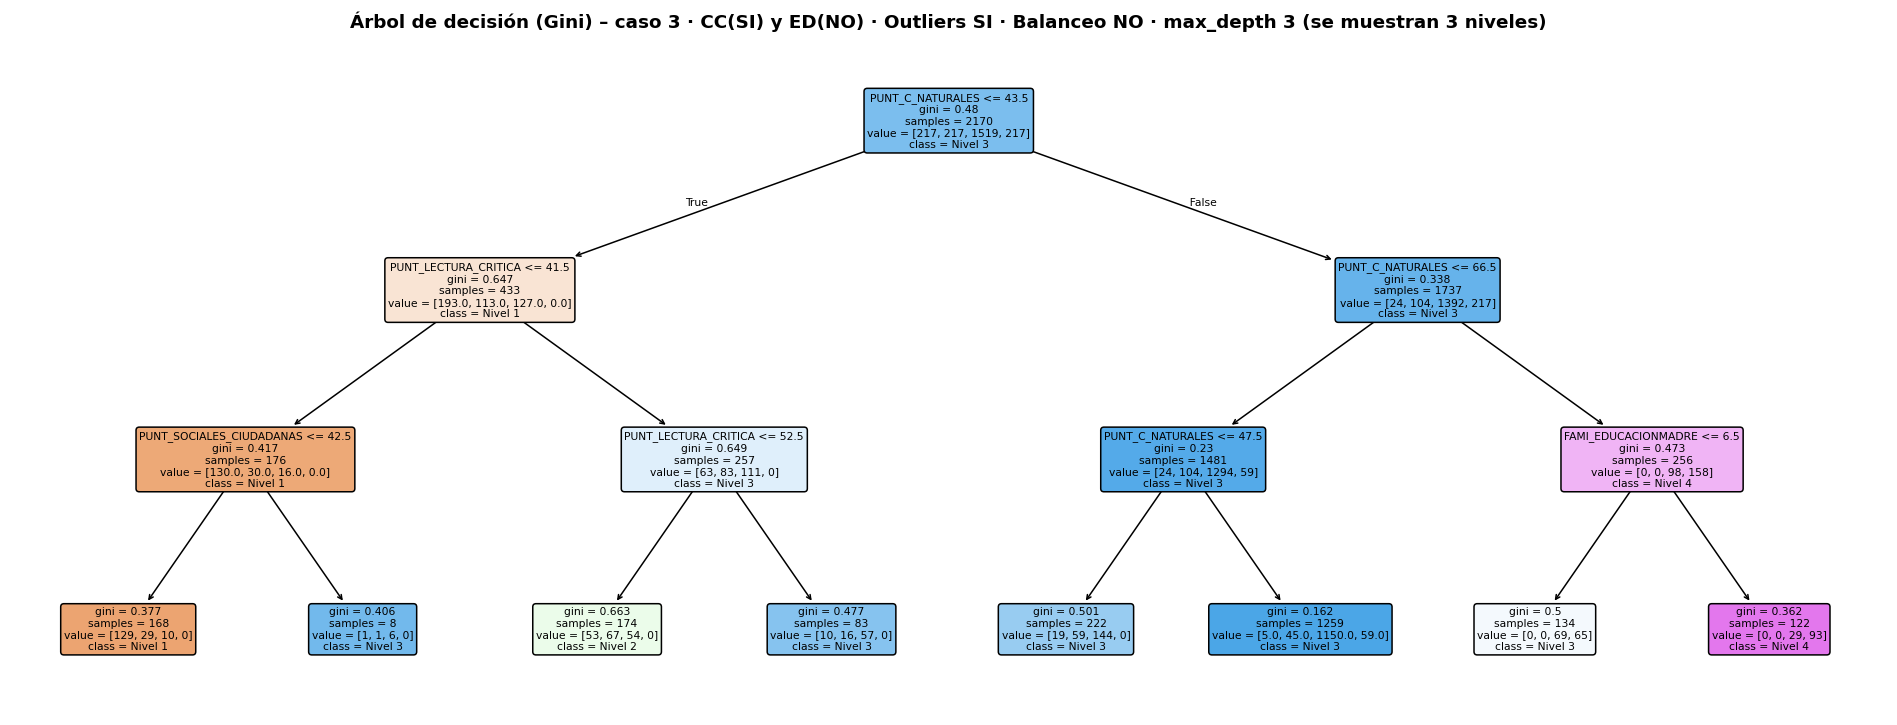

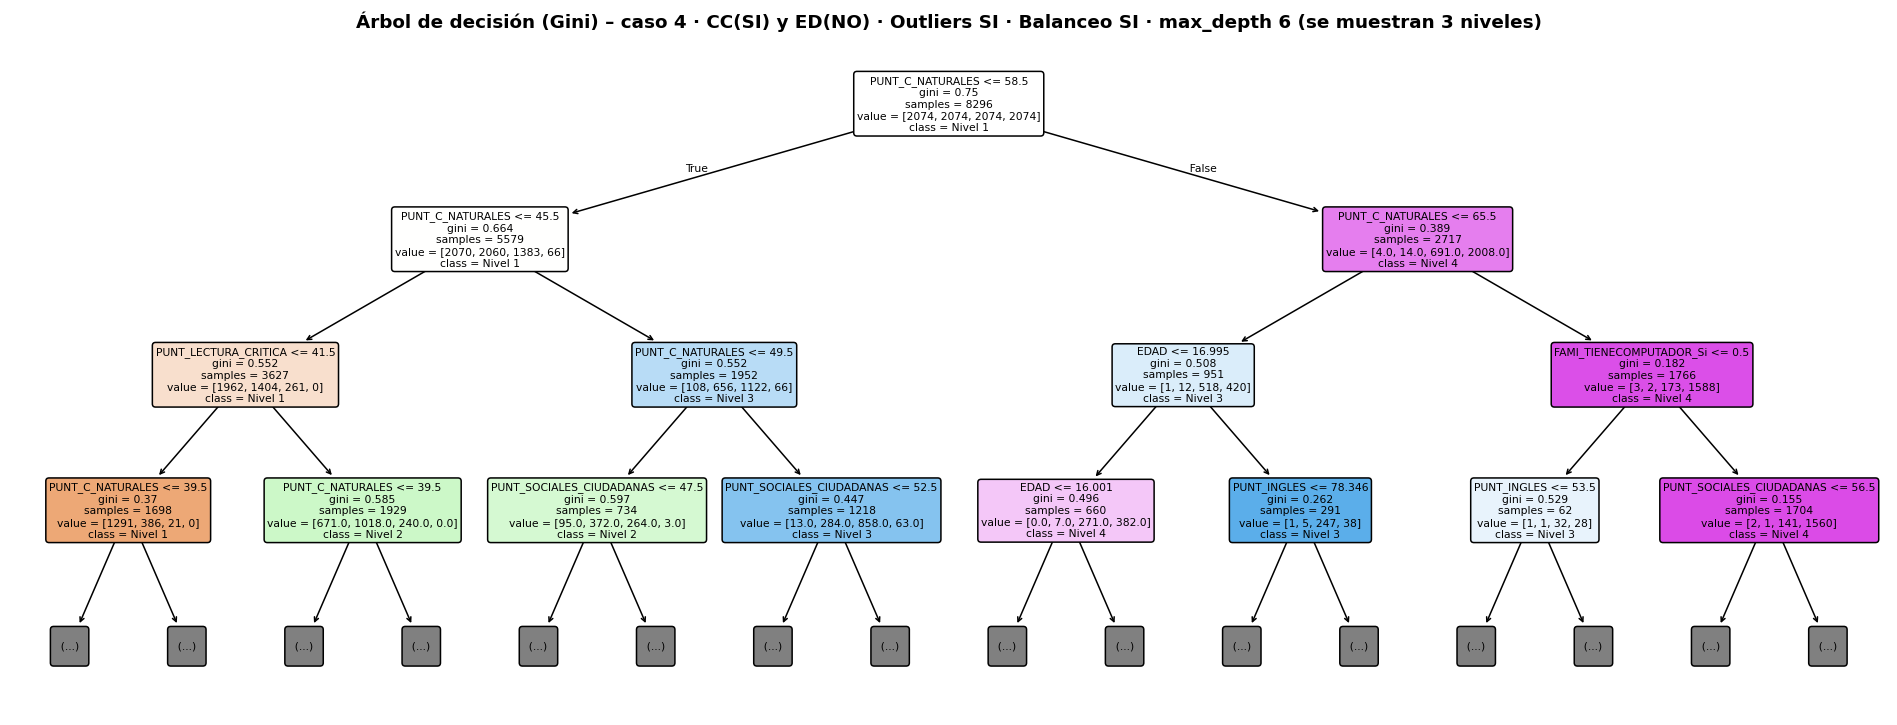

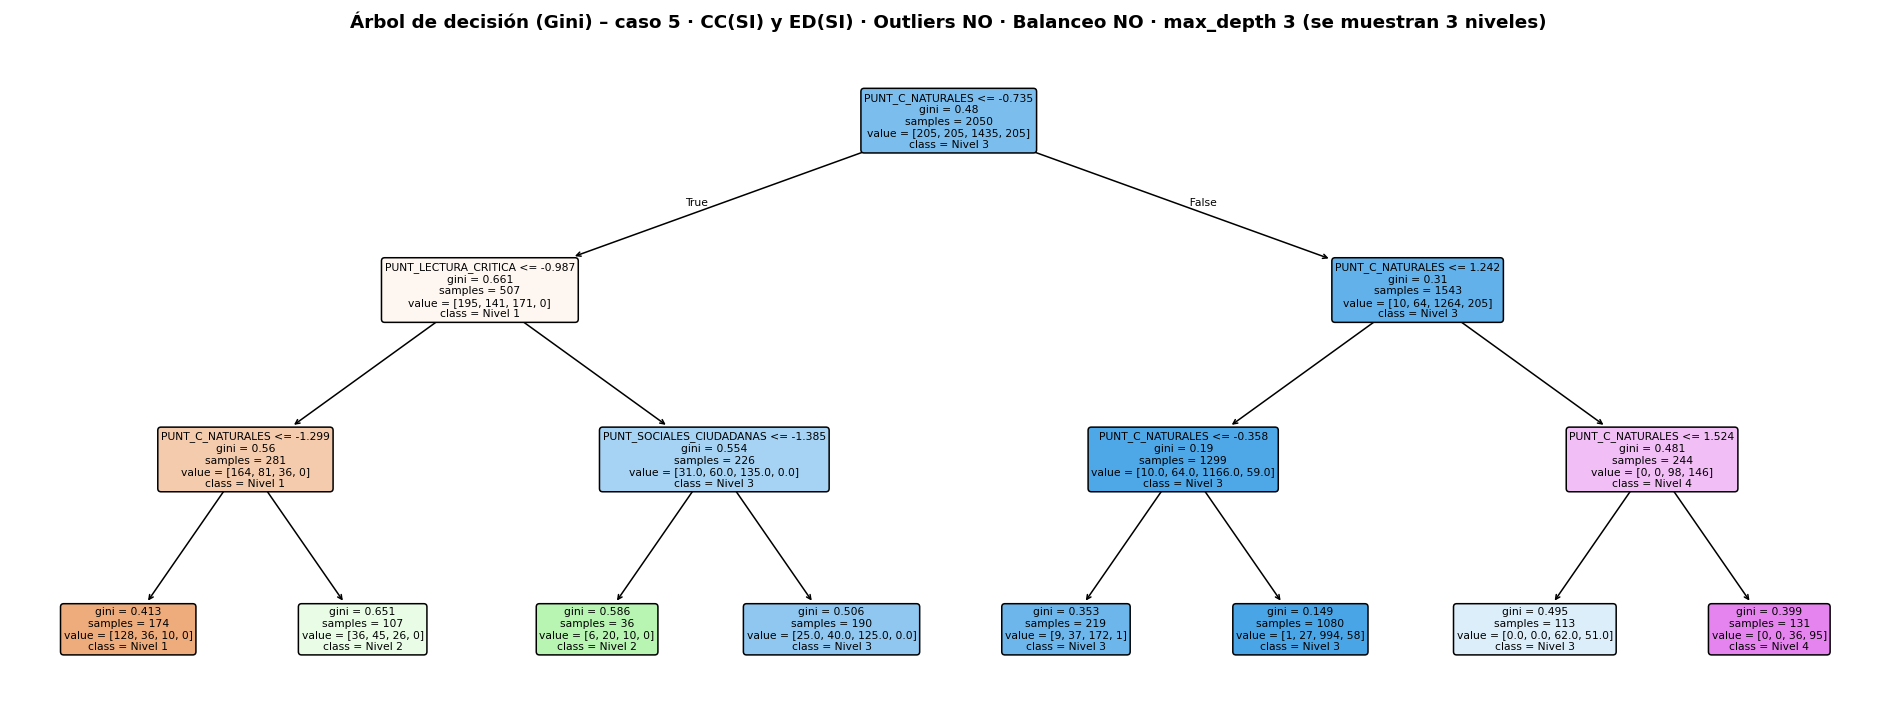

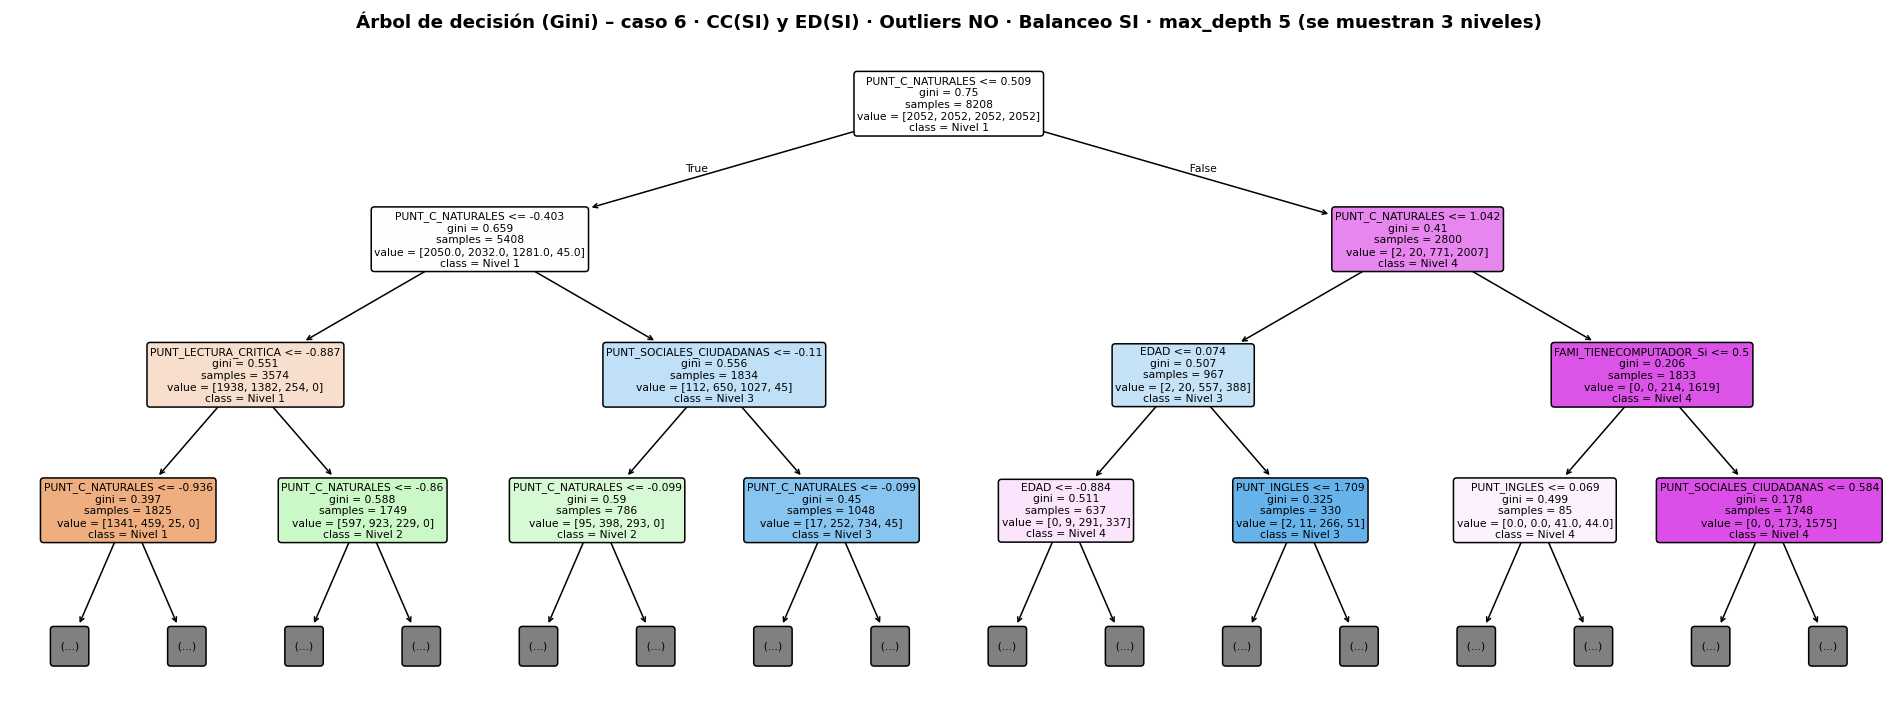

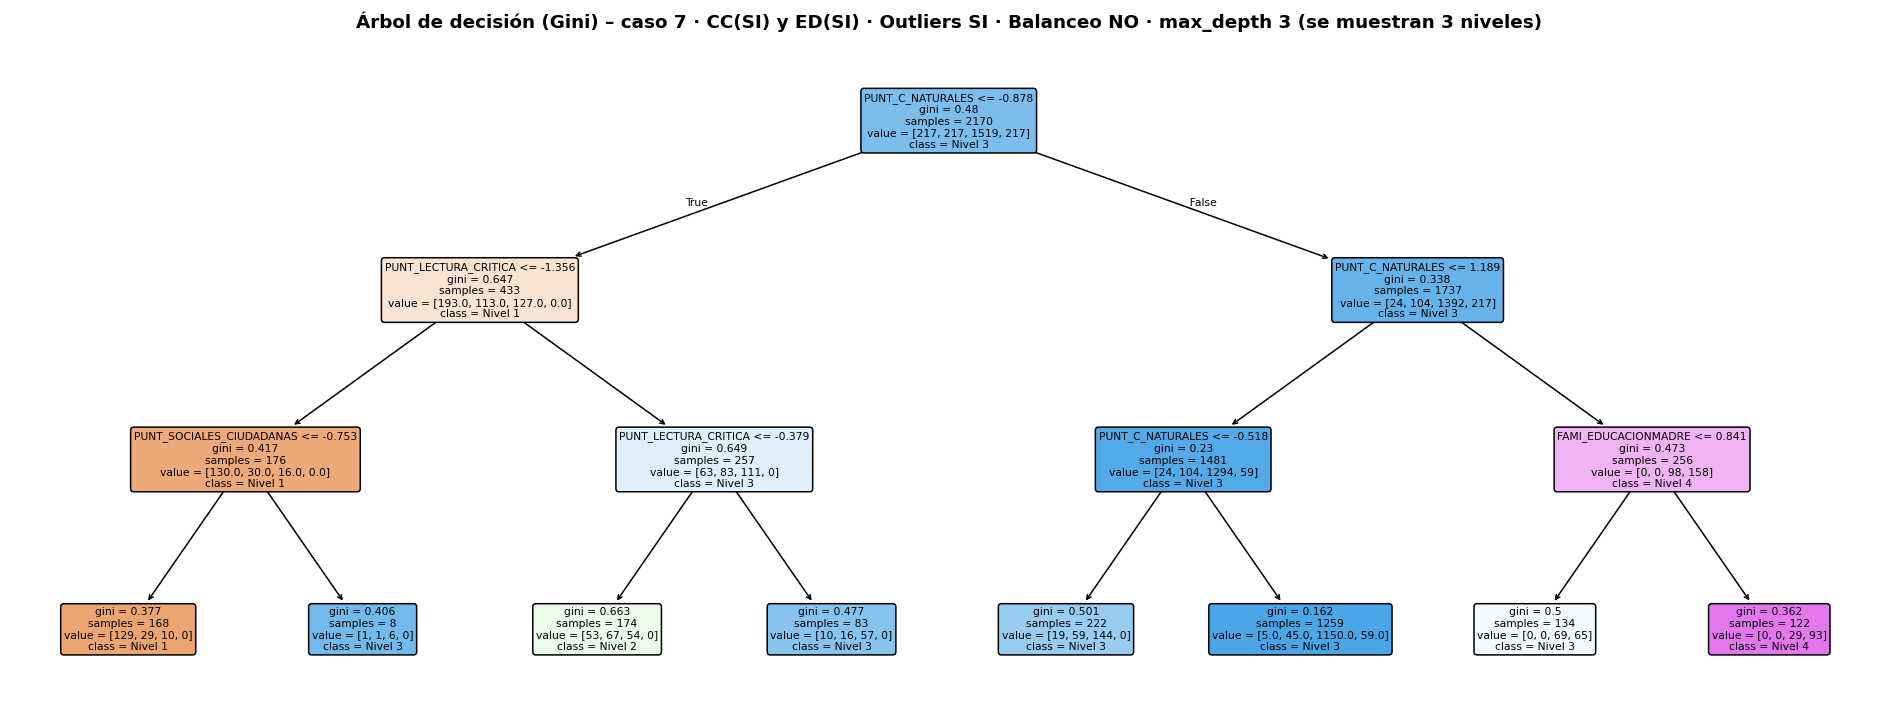

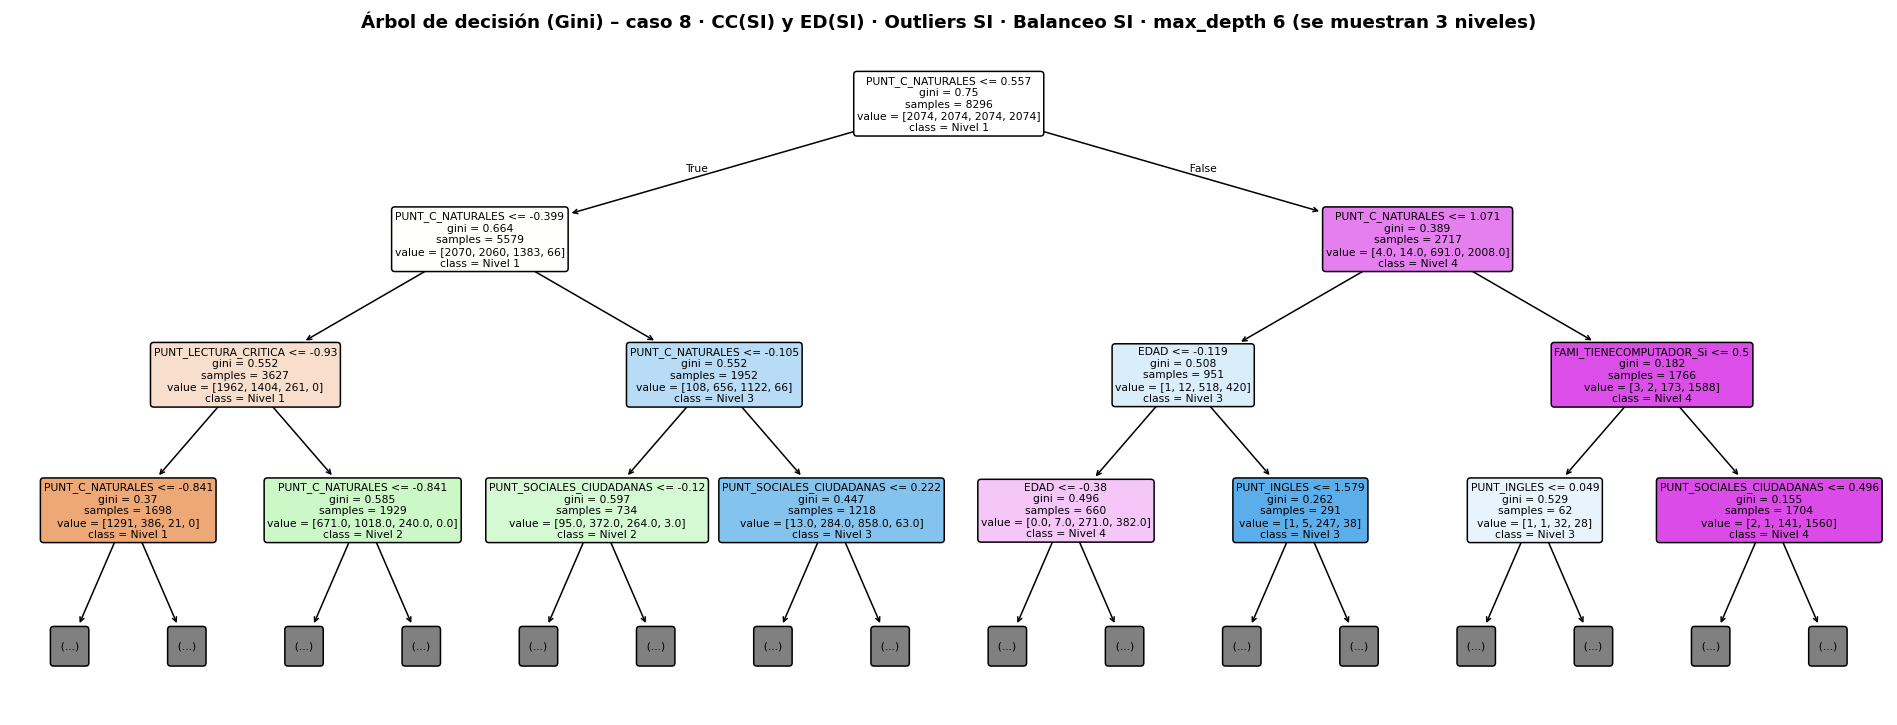

In [35]:
def graficar_arbol(caso, modelo, niveles=3):
    """Árbol registrado del caso con plot_tree (notebook 5_01). Se muestran los primeros
    `niveles` niveles para que los nodos sean legibles; el árbol completo tiene max_depth niveles."""
    plt.figure(figsize=(22, 8))
    plot_tree(modelo, feature_names=list(casos[caso]["X_train"].columns), class_names=CLASES,
              filled=True, rounded=True, max_depth=niveles, fontsize=7, impurity=True)
    c = casos[caso]
    plt.title(f"Árbol de decisión (Gini) – caso {caso} · {c['normalizacion']} · Outliers {c['outliers']} · "
              f"Balanceo {c['balanceo']} · max_depth {modelo.max_depth} (se muestran {niveles} niveles)")
    plt.show()


for k in casos:
    graficar_arbol(k, MODELOS_ARBOL[k])

#### 5.1.6 Interpretación de las reglas en el contexto educativo
*Documento, sección 4.1.*

#### 5.1.7 Caso 8: matriz de confusión y reporte por clase
*Análisis del reporte por clase y de las matrices: documento, sección 5.4.*

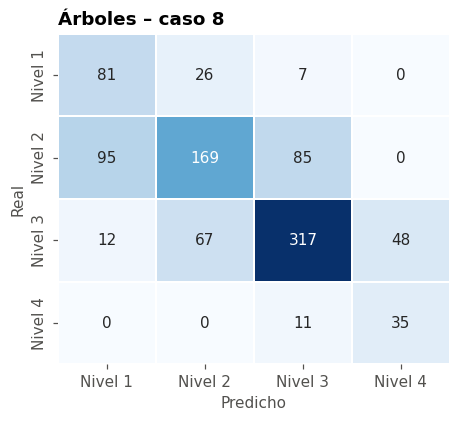

,precision,recall,f1-score,support
Nivel 1,0.4309,0.7105,0.5364,114.0000
Nivel 2,0.6450,0.4842,0.5532,349.0000
Nivel 3,0.7548,0.7140,0.7338,444.0000
Nivel 4,0.4217,0.7609,0.5426,46.0000
accuracy,0.6317,0.6317,0.6317,0.6317
macro avg,0.5631,0.6674,0.5915,953.0000
weighted avg,0.6598,0.6317,0.6348,953.0000


In [36]:
# Caso 8: matriz de confusión y reporte por clase
fig, ax = plt.subplots(figsize=(4.6, 3.9))
graficar_matriz_confusion("Árboles", 8, ax=ax)
plt.show()
display(reporte_por_clase("Árboles", 8))

### 5.2 K vecinos más cercanos (KNN)
#### 5.2.1 Elección de k con validación cruzada de 5 folds
k impares de 1 a 51, elegido con el accuracy promedio de la validación cruzada estratificada de 5 folds sobre el entrenamiento, con distancia euclidiana y voto uniforme. También se grafican el accuracy y el F1 de validación.

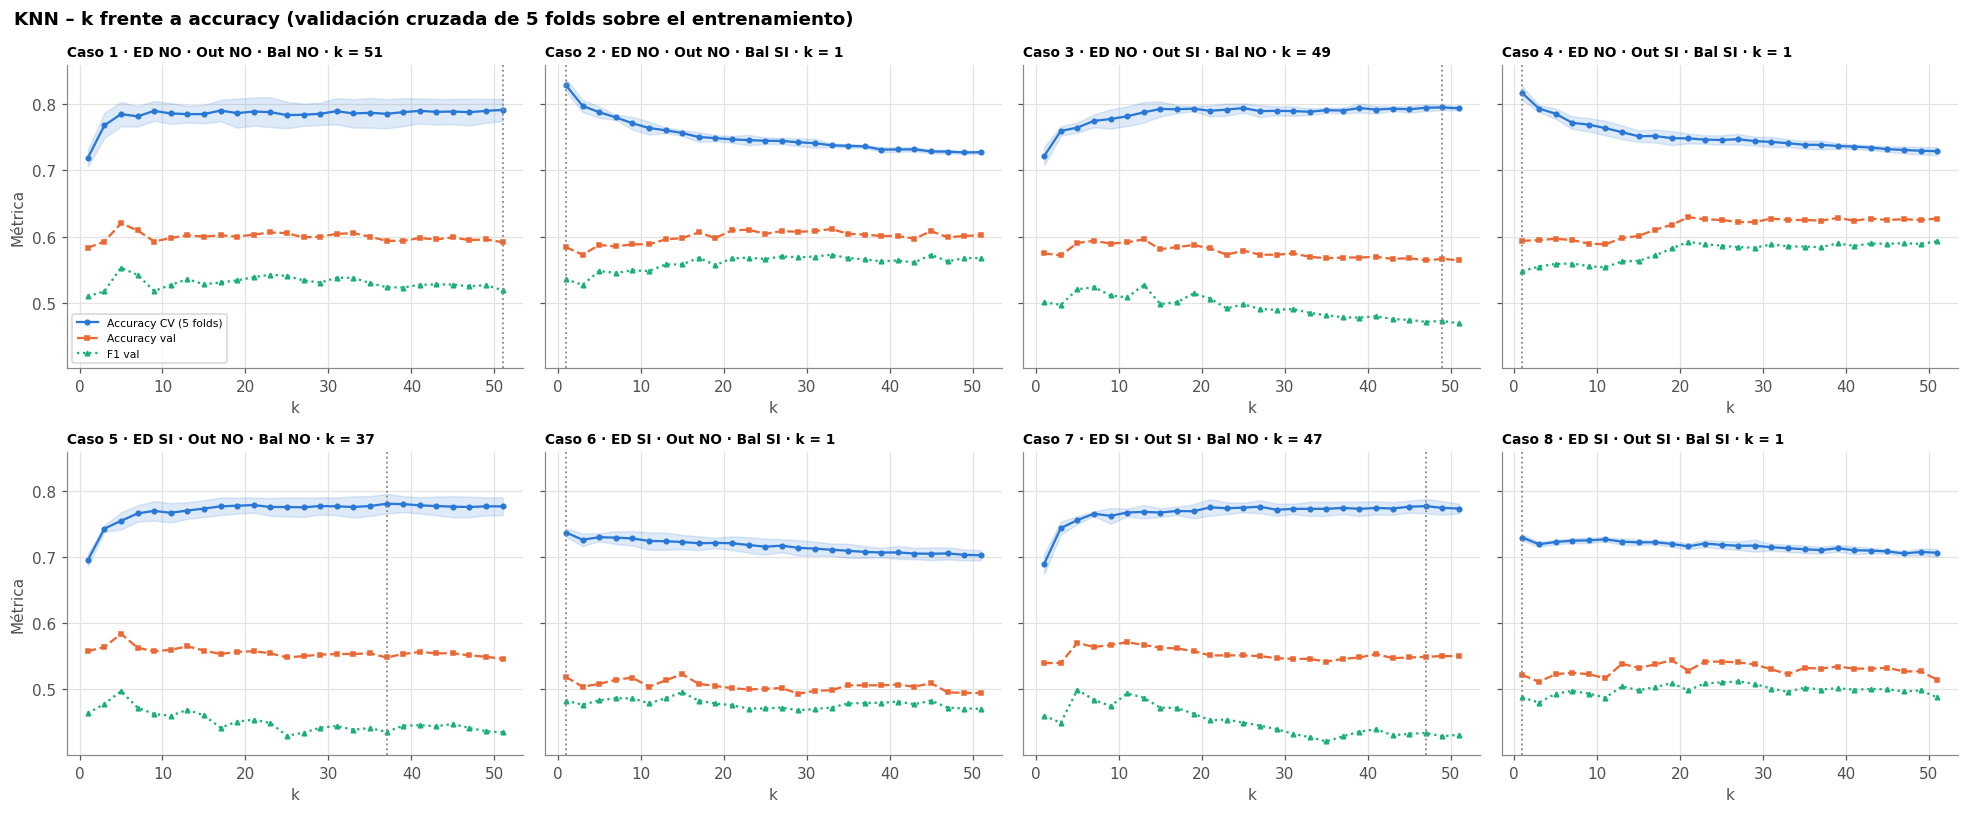

,ED,Balanceo,k elegido,Accuracy CV,Accuracy val,F1 val,k con mayor F1 val,Mayor F1 val
Caso,,,,,,,,
1,NO,NO,51,0.7912,0.5914,0.5187,5,0.5531
2,NO,SI,1,0.8285,0.5840,0.5354,45,0.5724
3,NO,NO,49,0.7949,0.5662,0.4724,13,0.5268
4,NO,SI,1,0.8164,0.5935,0.5478,51,0.5928
5,SI,NO,37,0.7805,0.5483,0.4360,5,0.4976
6,SI,SI,1,0.7371,0.5189,0.4830,15,0.4958
7,SI,NO,47,0.7770,0.5494,0.4343,5,0.4997
8,SI,SI,1,0.7294,0.5221,0.4879,27,0.5122


In [37]:
# ============================================================
# 5.2 KNN: k frente a accuracy con validación cruzada de 5 folds
# ============================================================
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

VALORES_K = list(range(1, 52, 2))   # k impares de 1 a 51 (evitan empates en la votación)
FOLDS_KNN = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)


def curva_k(caso, valores_k=VALORES_K):
    """Para cada k: accuracy promedio de la validación cruzada de 5 folds sobre el entrenamiento
    del caso (procedimiento de la diapositiva 5-03) y, como contraste, accuracy y F1 macro en
    el conjunto de validación con el modelo entrenado en todo el entrenamiento."""
    d = casos[caso]
    filas = []
    for k_vecinos in valores_k:
        knn = KNeighborsClassifier(n_neighbors=k_vecinos)
        cv = cross_val_score(knn, d["X_train"], d["y_train"], cv=FOLDS_KNN, scoring="accuracy")
        knn.fit(d["X_train"], d["y_train"])
        y_pred_val = knn.predict(d["X_val"])
        filas.append({"k": k_vecinos, "Accuracy CV": cv.mean(), "Desv. CV": cv.std(),
                      "Accuracy val": accuracy_score(d["y_val"], y_pred_val),
                      "F1 val": f1_score(d["y_val"], y_pred_val, average="macro")})
    return pd.DataFrame(filas)


def mejor_k(curva):
    """k con el mayor accuracy promedio de validación cruzada; en empate, el menor."""
    return int(curva.sort_values(["Accuracy CV", "k"], ascending=[False, True]).iloc[0]["k"])


CURVAS_KNN = {k: curva_k(k) for k in casos}


def graficar_curvas_k(curvas=CURVAS_KNN):
    """k frente a accuracy de la validación cruzada de 5 folds (con su desviación) y frente a
    accuracy y F1 de validación. La línea vertical marca el k elegido."""
    fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), sharey=True)
    for ax, k in zip(axes.ravel(), casos):
        curva = curvas[k]
        ax.plot(curva["k"], curva["Accuracy CV"], "o-", markersize=3, color=COLORES_SERIES[0],
                label="Accuracy CV (5 folds)")
        ax.fill_between(curva["k"], curva["Accuracy CV"] - curva["Desv. CV"],
                        curva["Accuracy CV"] + curva["Desv. CV"], color=COLORES_SERIES[0], alpha=0.15)
        ax.plot(curva["k"], curva["Accuracy val"], "s--", markersize=3, color=COLORES_SERIES[1],
                label="Accuracy val")
        ax.plot(curva["k"], curva["F1 val"], "^:", markersize=3, color=COLORES_SERIES[2], label="F1 val")
        ax.axvline(mejor_k(curva), color="#8a8984", linestyle=":", linewidth=1.2)
        c = casos[k]
        ax.set_title(f"Caso {k} · ED {c['normalizacion'][-3:-1]} · Out {c['outliers']} · Bal {c['balanceo']} · "
                     f"k = {mejor_k(curva)}", loc="left", fontsize=9)
        ax.set_xlabel("k")
    for ax in axes[:, 0]:
        ax.set_ylabel("Métrica")
    axes[0, 0].legend(fontsize=7)
    fig.suptitle("KNN – k frente a accuracy (validación cruzada de 5 folds sobre el entrenamiento)",
                 x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


def resumen_eleccion_k(curvas=CURVAS_KNN):
    """k elegido por caso con sus métricas, y el k que habría dado el mayor F1 de validación."""
    filas = []
    for k, curva in curvas.items():
        fila = curva.set_index("k").loc[mejor_k(curva)]
        k_f1 = int(curva.loc[curva["F1 val"].idxmax(), "k"])
        filas.append({"Caso": k, "ED": casos[k]["normalizacion"][-3:-1], "Balanceo": casos[k]["balanceo"],
                      "k elegido": mejor_k(curva), "Accuracy CV": round(fila["Accuracy CV"], 4),
                      "Accuracy val": round(fila["Accuracy val"], 4), "F1 val": round(fila["F1 val"], 4),
                      "k con mayor F1 val": k_f1, "Mayor F1 val": round(curva["F1 val"].max(), 4)})
    return pd.DataFrame(filas).set_index("Caso")


graficar_curvas_k()
display(resumen_eleccion_k())

In [38]:
# KNN final de cada caso con el k elegido (distancia euclidiana y voto uniforme, notebook 5_02)
MODELOS_KNN = {}   # caso -> KNN registrado
for k in casos:
    k_vecinos = mejor_k(CURVAS_KNN[k])
    MODELOS_KNN[k] = KNeighborsClassifier(n_neighbors=k_vecinos).fit(casos[k]["X_train"], casos[k]["y_train"])
    registrar_resultado("KNN", k, MODELOS_KNN[k], {"n_neighbors": k_vecinos, "metric": "euclidiana"})

KNN | caso 1 | Accuracy: 0.5950 | Precision: 0.6539 | Recall: 0.5727 | F1: 0.5268
KNN | caso 2 | Accuracy: 0.5771 | Precision: 0.5027 | Recall: 0.5632 | F1: 0.5240
KNN | caso 3 | Accuracy: 0.5719 | Precision: 0.6462 | Recall: 0.5609 | F1: 0.4864
KNN | caso 4 | Accuracy: 0.5792 | Precision: 0.5040 | Recall: 0.5540 | F1: 0.5227
KNN | caso 5 | Accuracy: 0.5635 | Precision: 0.6250 | Recall: 0.4754 | F1: 0.4381
KNN | caso 6 | Accuracy: 0.5016 | Precision: 0.4304 | Recall: 0.4993 | F1: 0.4444
KNN | caso 7 | Accuracy: 0.5498 | Precision: 0.6276 | Recall: 0.4664 | F1: 0.4291
KNN | caso 8 | Accuracy: 0.4911 | Precision: 0.4253 | Recall: 0.4953 | F1: 0.4425


#### 5.2.2 Evaluación de los 3 datos de prueba

In [39]:
# Evaluación de los 3 datos de prueba de demostración en los 8 casos
display(pd.concat([predecir_demo("KNN", k, MODELOS_KNN[k]) for k in casos]))

,Técnica,Real,Predicho,P(Nivel 1),P(Nivel 2),P(Nivel 3),P(Nivel 4)
3576,KNN (caso 1),Nivel 1,Nivel 1,0.804,0.196,0.000,0.000
397,KNN (caso 1),Nivel 3,Nivel 3,0.000,0.000,0.941,0.059
4354,KNN (caso 1),Nivel 4,Nivel 3,0.000,0.000,0.922,0.078
3576,KNN (caso 2),Nivel 1,Nivel 1,1.000,0.000,0.000,0.000
397,KNN (caso 2),Nivel 3,Nivel 3,0.000,0.000,1.000,0.000
4354,KNN (caso 2),Nivel 4,Nivel 3,0.000,0.000,1.000,0.000
3576,KNN (caso 3),Nivel 1,Nivel 1,0.857,0.122,0.020,0.000
397,KNN (caso 3),Nivel 3,Nivel 3,0.000,0.000,0.939,0.061
4354,KNN (caso 3),Nivel 4,Nivel 3,0.000,0.000,0.918,0.082
3576,KNN (caso 4),Nivel 1,Nivel 1,1.000,0.000,0.000,0.000


#### 5.2.3 Gráfico de vecinos (PCA a 2D)
Vecinos de los 3 registros de prueba, calculados por el modelo en las 65 columnas. PCA solo se usa para dibujar.

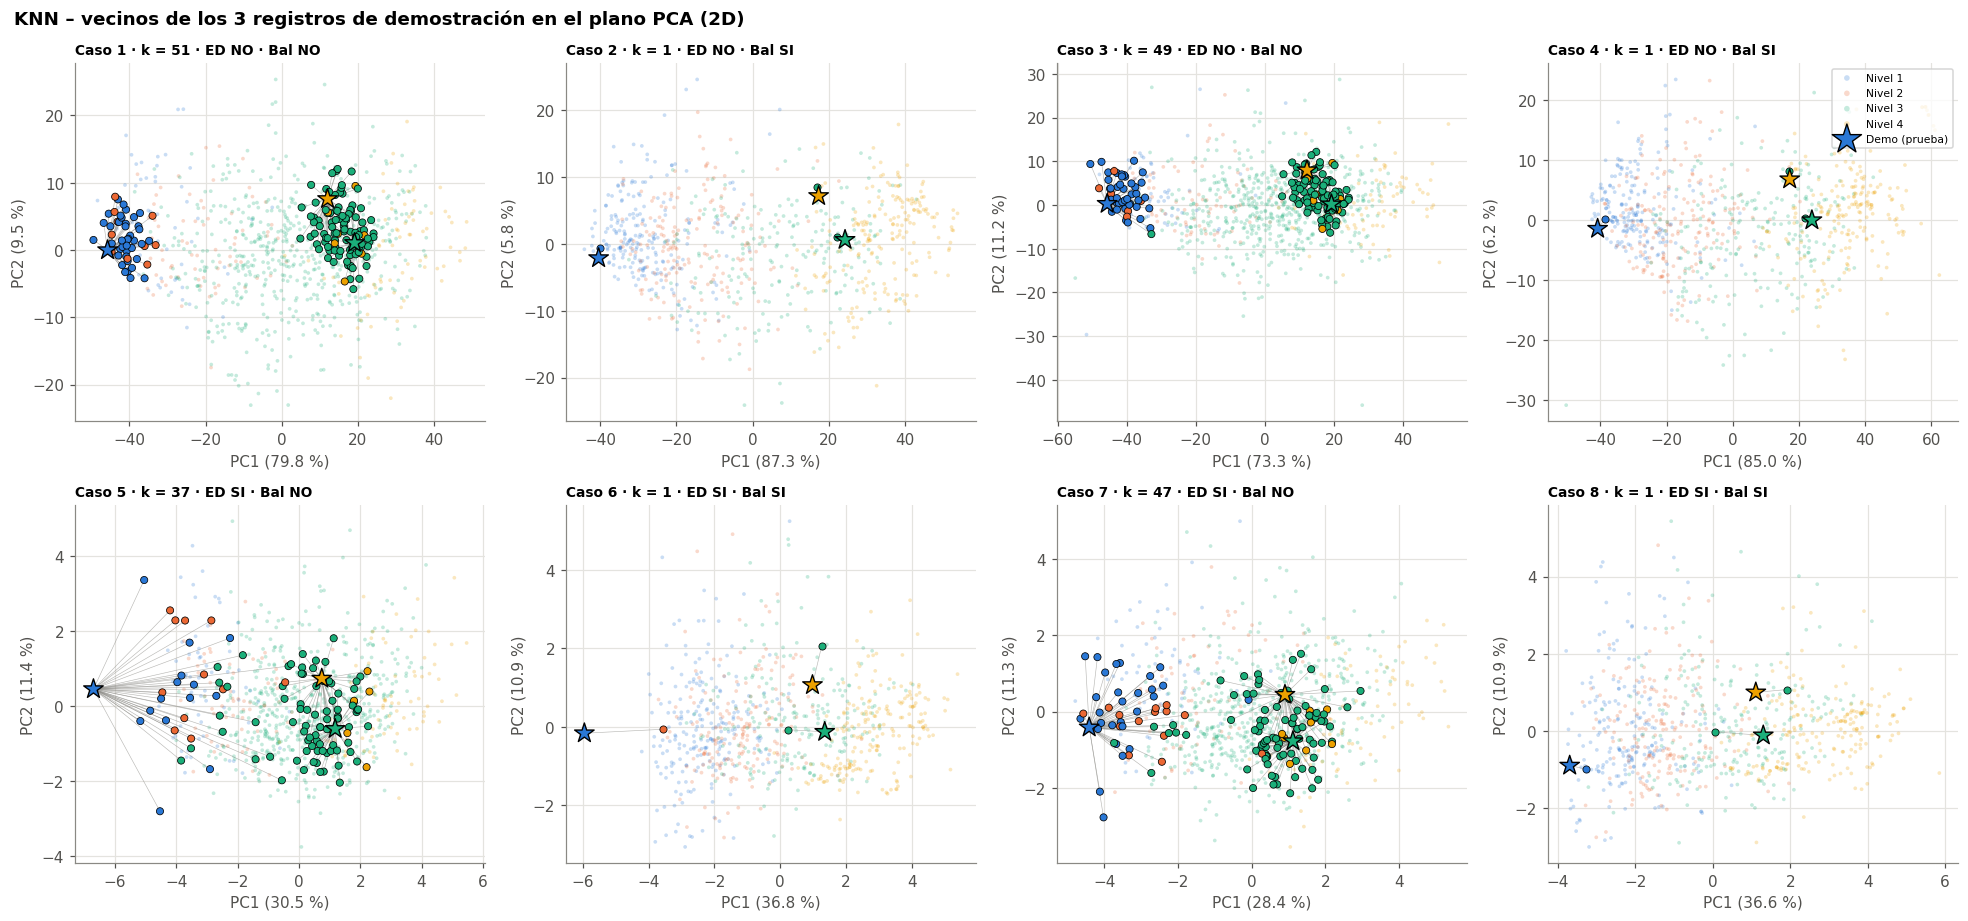

,Votos Nivel 1,Votos Nivel 2,Votos Nivel 3,Votos Nivel 4
Caso 1 – real Nivel 1,41,10,0,0
Caso 1 – real Nivel 3,0,0,48,3
Caso 1 – real Nivel 4,0,0,47,4
Caso 2 – real Nivel 1,1,0,0,0
Caso 2 – real Nivel 3,0,0,1,0
Caso 2 – real Nivel 4,0,0,1,0
Caso 3 – real Nivel 1,42,6,1,0
Caso 3 – real Nivel 3,0,0,46,3
Caso 3 – real Nivel 4,0,0,45,4
Caso 4 – real Nivel 1,1,0,0,0


In [40]:
from sklearn.decomposition import PCA


def graficar_vecinos(caso, modelo, ax, n_puntos=800):
    """Vecinos del KNN registrado para los 3 registros de demostración, en el plano de las 2
    primeras componentes principales. PCA se ajusta con el entrenamiento del caso y solo se usa
    para dibujar: los vecinos los calcula el modelo con kneighbors en las 65 columnas."""
    d = casos[caso]
    pca = PCA(n_components=2, random_state=SEMILLA).fit(d["X_train"])
    Z_train = pca.transform(d["X_train"])
    X_demo_k, y_demo_k = obtener_datos_demo(caso)
    Z_demo = pca.transform(X_demo_k)
    _, vecinos = modelo.kneighbors(X_demo_k)   # índices (posición en X_train) de los k vecinos

    # Fondo: muestra del entrenamiento con su clase real
    rng = np.random.default_rng(SEMILLA)
    idx = rng.choice(len(Z_train), size=min(n_puntos, len(Z_train)), replace=False)
    y_train = d["y_train"].to_numpy()
    for i, clase in enumerate(CLASES):
        sel = idx[y_train[idx] == i]
        ax.scatter(Z_train[sel, 0], Z_train[sel, 1], s=6, color=COLORES_CLASES[clase], alpha=0.25,
                   edgecolors="none", label=clase)

    # Vecinos de cada registro de demostración: líneas hasta la estrella y borde negro
    for j in range(len(Z_demo)):
        for v in vecinos[j]:
            ax.plot([Z_demo[j, 0], Z_train[v, 0]], [Z_demo[j, 1], Z_train[v, 1]],
                    color="#8a8984", linewidth=0.4, alpha=0.6, zorder=1)
        ax.scatter(Z_train[vecinos[j], 0], Z_train[vecinos[j], 1], s=22,
                   c=[COLORES_CLASES[CLASES[v]] for v in y_train[vecinos[j]]],
                   edgecolors="black", linewidths=0.5, zorder=2)
    ax.scatter(Z_demo[:, 0], Z_demo[:, 1], s=180, marker="*", edgecolors="black", linewidths=0.9,
               c=[COLORES_CLASES[CLASES[v]] for v in y_demo_k], zorder=3, label="Demo (prueba)")

    var = pca.explained_variance_ratio_ * 100
    ax.set(xlabel=f"PC1 ({var[0]:.1f} %)", ylabel=f"PC2 ({var[1]:.1f} %)")
    ax.set_title(f"Caso {caso} · k = {modelo.n_neighbors} · ED {d['normalizacion'][-3:-1]} · Bal {d['balanceo']}",
                 loc="left", fontsize=9)
    # Votos de los vecinos por registro de demostración
    return pd.DataFrame([np.bincount(y_train[vecinos[j]], minlength=len(CLASES)) for j in range(len(Z_demo))],
                        columns=[f"Votos {c}" for c in CLASES],
                        index=[f"Caso {caso} – real {CLASES[v]}" for v in y_demo_k])


fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
VOTOS_KNN = pd.concat([graficar_vecinos(k, MODELOS_KNN[k], ax) for k, ax in zip(casos, axes.ravel())])
axes[0, 3].legend(fontsize=7, loc="upper right", markerscale=1.5)
fig.suptitle("KNN – vecinos de los 3 registros de demostración en el plano PCA (2D)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()
display(VOTOS_KNN)

#### 5.2.4 Caso 8: matriz de confusión y reporte por clase
*Análisis del reporte por clase y de las matrices: documento, sección 5.4.*

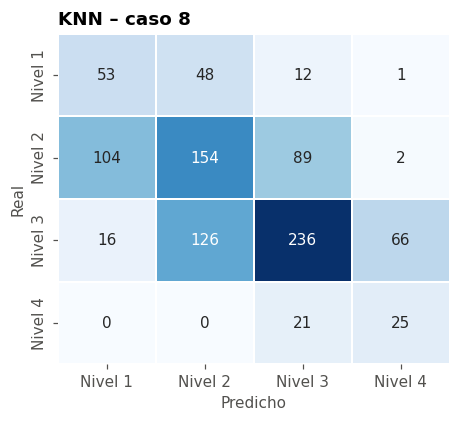

,precision,recall,f1-score,support
Nivel 1,0.3064,0.4649,0.3693,114.0000
Nivel 2,0.4695,0.4413,0.4549,349.0000
Nivel 3,0.6592,0.5315,0.5885,444.0000
Nivel 4,0.2660,0.5435,0.3571,46.0000
accuracy,0.4911,0.4911,0.4911,0.4911
macro avg,0.4253,0.4953,0.4425,953.0000
weighted avg,0.5286,0.4911,0.5022,953.0000


In [41]:
# Caso 8: matriz de confusión y reporte por clase
fig, ax = plt.subplots(figsize=(4.6, 3.9))
graficar_matriz_confusion("KNN", 8, ax=ax)
plt.show()
display(reporte_por_clase("KNN", 8))

### 5.3 Resumen de árboles y KNN

In [42]:
# ============================================================
# 5.3 Resumen de árboles y KNN
# ============================================================
def resumen_bloque2(algoritmos=("Árboles", "KNN")):
    """Métricas de prueba por caso de los algoritmos de la sección (tomadas de la Figura 1)
    y F1 macro medio por factor de preprocesamiento (escalado, outliers y balanceo)."""
    tabla = tabla_figura1()[[(a, m) for a in algoritmos for m in METRICAS]]
    config = pd.DataFrame({k: {"ED": c["normalizacion"][-3:-1], "Outliers": c["outliers"],
                               "Balanceo": c["balanceo"]} for k, c in casos.items()}).T
    f1 = pd.concat([config, tabla.xs("F1", axis=1, level=1).astype(float)], axis=1)
    promedios = pd.concat({factor: f1.groupby(factor)[list(algoritmos)].mean()
                           for factor in ("ED", "Outliers", "Balanceo")}).round(4)
    return tabla, promedios


TABLA_BLOQUE2, PROMEDIOS_BLOQUE2 = resumen_bloque2()
display(TABLA_BLOQUE2)
print("F1 macro medio por factor de preprocesamiento:")
display(PROMEDIOS_BLOQUE2)

Árboles                                KNN                          
     Accuracy Precision  Recall      F1 Accuracy Precision  Recall      F1
Caso                                                                      
1      0.6055    0.6056  0.5424  0.5371    0.595    0.6539  0.5727  0.5268
2      0.6159    0.5533  0.6293  0.5771   0.5771    0.5027  0.5632   0.524
3       0.617    0.6181  0.5247  0.5306   0.5719    0.6462  0.5609  0.4864
4      0.6317    0.5631  0.6674  0.5915   0.5792     0.504   0.554  0.5227
5      0.6055    0.6056  0.5424  0.5371   0.5635     0.625  0.4754  0.4381
6      0.6159    0.5533  0.6293  0.5771   0.5016    0.4304  0.4993  0.4444
7       0.617    0.6181  0.5247  0.5306   0.5498    0.6276  0.4664  0.4291
8      0.6317    0.5631  0.6674  0.5915   0.4911    0.4253  0.4953  0.4425

F1 macro medio por factor de preprocesamiento:


Árboles     KNN
         ED                 
ED       NO   0.5591  0.5150
         SI   0.5591  0.4385
Outliers NO   0.5571  0.4833
         SI   0.5611  0.4702
Balanceo NO   0.5338  0.4701
         SI   0.5843  0.4834

## 6. SVM y redes neuronales
SVM (`SVC` lineal y RBF) y redes `tf.keras.Sequential` en los 8 casos, con los hiperparámetros elegidos por el F1 macro de validación. *Análisis: documento, secciones 4.3, 4.4 y 4.5.*

### 6.1 Máquinas de vectores de soporte (SVM)
#### 6.1.1 Búsqueda de kernel, C y gamma
12 configuraciones por caso evaluadas en validación: lineal con C ∈ {0.01, 0.1, 1} y RBF con C ∈ {0.1, 1, 10} × gamma ∈ {scale, 0.01, 0.1}. El modelo final usa `probability=True` para las curvas ROC/PR.

In [43]:
# ============================================================
# 6.1 SVM: búsqueda de kernel, C y gamma con el conjunto de validación
# ============================================================
import time
from sklearn.svm import SVC

# Configuraciones candidatas (kernels vistos en clase: lineal y RBF)
REJILLA_SVM = (
    [{"kernel": "linear", "C": C} for C in (0.01, 0.1, 1)]
    + [{"kernel": "rbf", "C": C, "gamma": g} for C in (0.1, 1, 10) for g in ("scale", 0.01, 0.1)]
)


def tabla_busqueda_svm(caso, rejilla=REJILLA_SVM):
    """Entrena un SVC por configuración de `rejilla` con el entrenamiento del caso y
    retorna una tabla con accuracy de entrenamiento, accuracy y F1 macro de VALIDACIÓN y
    número de vectores de soporte, ordenada por F1 de validación (la primera fila es la
    elegida; en empate gana el C más pequeño, es decir, el modelo más regularizado).
    La búsqueda no calcula probabilidades para no multiplicar el tiempo de entrenamiento."""
    d = casos[caso]
    filas = []
    for config in rejilla:
        modelo = SVC(**config, random_state=SEMILLA).fit(d["X_train"], d["y_train"])
        y_pred_val = modelo.predict(d["X_val"])
        filas.append({"kernel": config["kernel"], "C": config["C"], "gamma": config.get("gamma", "-"),
                      "Accuracy train": accuracy_score(d["y_train"], modelo.predict(d["X_train"])),
                      "Accuracy val": accuracy_score(d["y_val"], y_pred_val),
                      "F1 val": f1_score(d["y_val"], y_pred_val, average="macro"),
                      "N vectores soporte": len(modelo.support_), "config": config})
    tabla = pd.DataFrame(filas)
    return tabla.sort_values(["F1 val", "C"], ascending=[False, True]).reset_index(drop=True)


def entrenar_svm_final(caso, config):
    """Entrena el SVC final del caso con la configuración elegida. probability=True es
    obligatorio: sin probabilidades no hay curvas ROC/PR en la sección 7."""
    d = casos[caso]
    return SVC(**config, probability=True, random_state=SEMILLA).fit(d["X_train"], d["y_train"])


# Búsqueda, entrenamiento final y registro en los 8 casos
inicio_svm = time.time()
BUSQUEDA_SVM = {}   # caso -> tabla de la búsqueda
MODELOS_SVM = {}    # caso -> SVC final registrado
for k in casos:
    BUSQUEDA_SVM[k] = tabla_busqueda_svm(k)
    config_k = BUSQUEDA_SVM[k].loc[0, "config"]
    MODELOS_SVM[k] = entrenar_svm_final(k, config_k)
    registrar_resultado("SVM", k, MODELOS_SVM[k], config_k)
print(f"\nTiempo SVM (búsqueda + modelo final de los 8 casos): {time.time() - inicio_svm:.0f} s")

SVM | caso 1 | Accuracy: 0.5897 | Precision: 0.5835 | Recall: 0.5792 | F1: 0.5186
SVM | caso 2 | Accuracy: 0.6390 | Precision: 0.5702 | Recall: 0.6981 | F1: 0.6012
SVM | caso 3 | Accuracy: 0.5887 | Precision: 0.6009 | Recall: 0.5636 | F1: 0.5160
SVM | caso 4 | Accuracy: 0.6432 | Precision: 0.5649 | Recall: 0.6631 | F1: 0.5932
SVM | caso 5 | Accuracy: 0.5876 | Precision: 0.5820 | Recall: 0.5718 | F1: 0.5148
SVM | caso 6 | Accuracy: 0.6432 | Precision: 0.5581 | Recall: 0.6236 | F1: 0.5800
SVM | caso 7 | Accuracy: 0.5866 | Precision: 0.6005 | Recall: 0.5622 | F1: 0.5135
SVM | caso 8 | Accuracy: 0.6348 | Precision: 0.5535 | Recall: 0.6401 | F1: 0.5790

Tiempo SVM (búsqueda + modelo final de los 8 casos): 544 s


In [44]:
def resumen_eleccion_svm(busqueda=BUSQUEDA_SVM):
    """Configuración elegida por caso con su F1 de validación y el mejor F1 de validación
    alcanzado por cada kernel (para justificar la elección del kernel)."""
    filas = []
    for k, tabla in busqueda.items():
        mejor = tabla.iloc[0]
        filas.append({"Caso": k, "ED": casos[k]["normalizacion"][-3:-1], "Outliers": casos[k]["outliers"],
                      "Balanceo": casos[k]["balanceo"], "Kernel": mejor["kernel"], "C": mejor["C"],
                      "gamma": mejor["gamma"], "F1 val": round(mejor["F1 val"], 4),
                      "Mejor F1 val lineal": round(tabla.loc[tabla["kernel"] == "linear", "F1 val"].max(), 4),
                      "Mejor F1 val RBF": round(tabla.loc[tabla["kernel"] == "rbf", "F1 val"].max(), 4),
                      "N vectores soporte": int(mejor["N vectores soporte"])})
    return pd.DataFrame(filas).set_index("Caso")


display(resumen_eleccion_svm())

,ED,Outliers,Balanceo,Kernel,C,gamma,F1 val,Mejor F1 val lineal,Mejor F1 val RBF,N vectores soporte
Caso,,,,,,,,,,
1,NO,NO,NO,linear,1.0,-,0.5189,0.5189,0.4846,873
2,NO,NO,SI,rbf,10.0,scale,0.6068,0.5966,0.6068,5509
3,NO,SI,NO,linear,1.0,-,0.5355,0.5355,0.4926,943
4,NO,SI,SI,linear,0.1,-,0.6154,0.6154,0.6095,5055
5,SI,NO,NO,linear,1.0,-,0.5201,0.5201,0.5173,876
6,SI,NO,SI,rbf,1.0,scale,0.5964,0.5943,0.5964,5003
7,SI,SI,NO,linear,1.0,-,0.5379,0.5379,0.5237,944
8,SI,SI,SI,linear,1.0,-,0.6096,0.6096,0.5968,4900


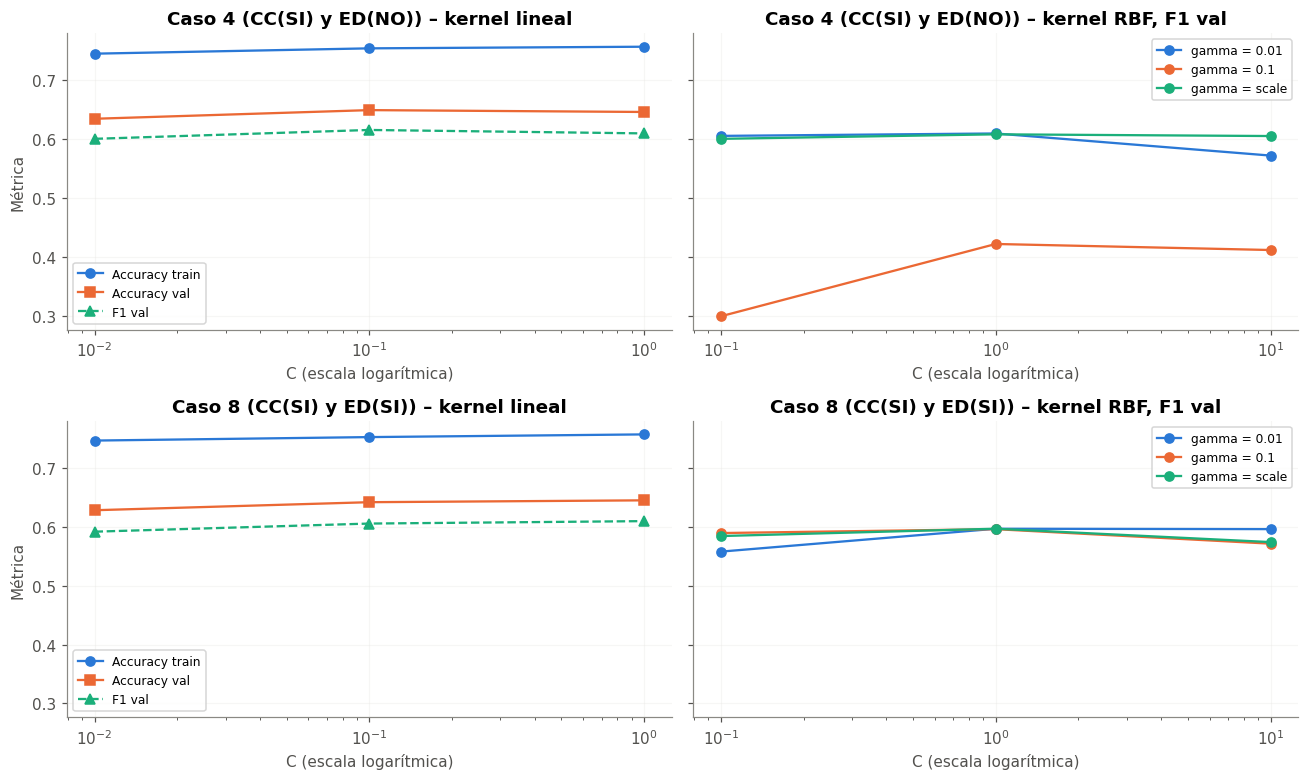

Caso 4:


,kernel,C,gamma,Accuracy train,Accuracy val,F1 val,N vectores soporte
0,linear,0.10,-,0.7541,0.6492,0.6154,5055
1,linear,1.00,-,0.7569,0.6460,0.6096,4894
2,rbf,1.00,0.01,0.8373,0.6597,0.6095,4997
3,rbf,1.00,scale,0.7185,0.6429,0.6080,5810
4,rbf,0.10,0.01,0.7455,0.6471,0.6054,5633
5,rbf,10.00,scale,0.7353,0.6408,0.6051,5516
6,linear,0.01,-,0.7451,0.6345,0.6004,5376
7,rbf,0.10,scale,0.6970,0.6261,0.6004,6572
8,rbf,10.00,0.01,0.9579,0.6355,0.5719,4497
9,rbf,1.00,0.1,0.9990,0.6092,0.4217,7272


Caso 8:


,kernel,C,gamma,Accuracy train,Accuracy val,F1 val,N vectores soporte
0,linear,1.00,-,0.7570,0.6450,0.6096,4900
1,linear,0.10,-,0.7524,0.6418,0.6055,5124
2,rbf,1.00,scale,0.8182,0.6460,0.5968,5084
3,rbf,1.00,0.01,0.7596,0.6334,0.5967,5554
4,rbf,10.00,0.01,0.7952,0.6439,0.5961,4894
5,rbf,1.00,0.1,0.8626,0.6502,0.5960,5131
6,linear,0.01,-,0.7465,0.6282,0.5917,5793
7,rbf,0.10,0.1,0.7655,0.6250,0.5894,6155
8,rbf,0.10,scale,0.7551,0.6208,0.5843,6121
9,rbf,10.00,scale,0.9209,0.6429,0.5740,4578


In [45]:
def graficar_sensibilidad_svm(casos_graf=(4, 8), busqueda=BUSQUEDA_SVM):
    """Sensibilidad del SVM a C y gamma (un hiperparámetro a la vez), a partir de la búsqueda.
    Por fila, un caso. Izquierda: kernel lineal, accuracy de entrenamiento y de validación y
    F1 de validación frente a C. Derecha: kernel RBF, F1 de validación frente a C para cada gamma."""
    fig, axes = plt.subplots(len(casos_graf), 2, figsize=(12, 3.6 * len(casos_graf)), sharey=True)
    for fila, k in zip(np.atleast_2d(axes), casos_graf):
        tabla = busqueda[k]
        lineal = tabla[tabla["kernel"] == "linear"].sort_values("C")
        fila[0].semilogx(lineal["C"], lineal["Accuracy train"], "o-", color=COLORES_SERIES[0], label="Accuracy train")
        fila[0].semilogx(lineal["C"], lineal["Accuracy val"], "s-", color=COLORES_SERIES[1], label="Accuracy val")
        fila[0].semilogx(lineal["C"], lineal["F1 val"], "^--", color=COLORES_SERIES[2], label="F1 val")
        fila[0].set(xlabel="C (escala logarítmica)", ylabel="Métrica",
                    title=f"Caso {k} ({casos[k]['normalizacion']}) – kernel lineal")
        rbf = tabla[tabla["kernel"] == "rbf"]
        for i, (gamma, grupo) in enumerate(rbf.groupby(rbf["gamma"].astype(str))):
            grupo = grupo.sort_values("C")
            fila[1].semilogx(grupo["C"], grupo["F1 val"], "o-", color=COLORES_SERIES[i], label=f"gamma = {gamma}")
        fila[1].set(xlabel="C (escala logarítmica)", title=f"Caso {k} ({casos[k]['normalizacion']}) – kernel RBF, F1 val")
        for ax in fila:
            ax.grid(True, alpha=0.3)
            ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


graficar_sensibilidad_svm()
for k in (4, 8):
    print(f"Caso {k}:")
    display(BUSQUEDA_SVM[k].drop(columns="config").round(4))

#### 6.1.2 Justificación de kernel, C y gamma
*Documento, sección 4.3.*

#### 6.1.3 Regiones de decisión (PCA a 2D)
Malla en el plano de las 2 primeras componentes, llevada a las 65 columnas con `inverse_transform` y clasificada con el modelo registrado (notebook de clase `7-04`). PCA solo se usa para visualizar.

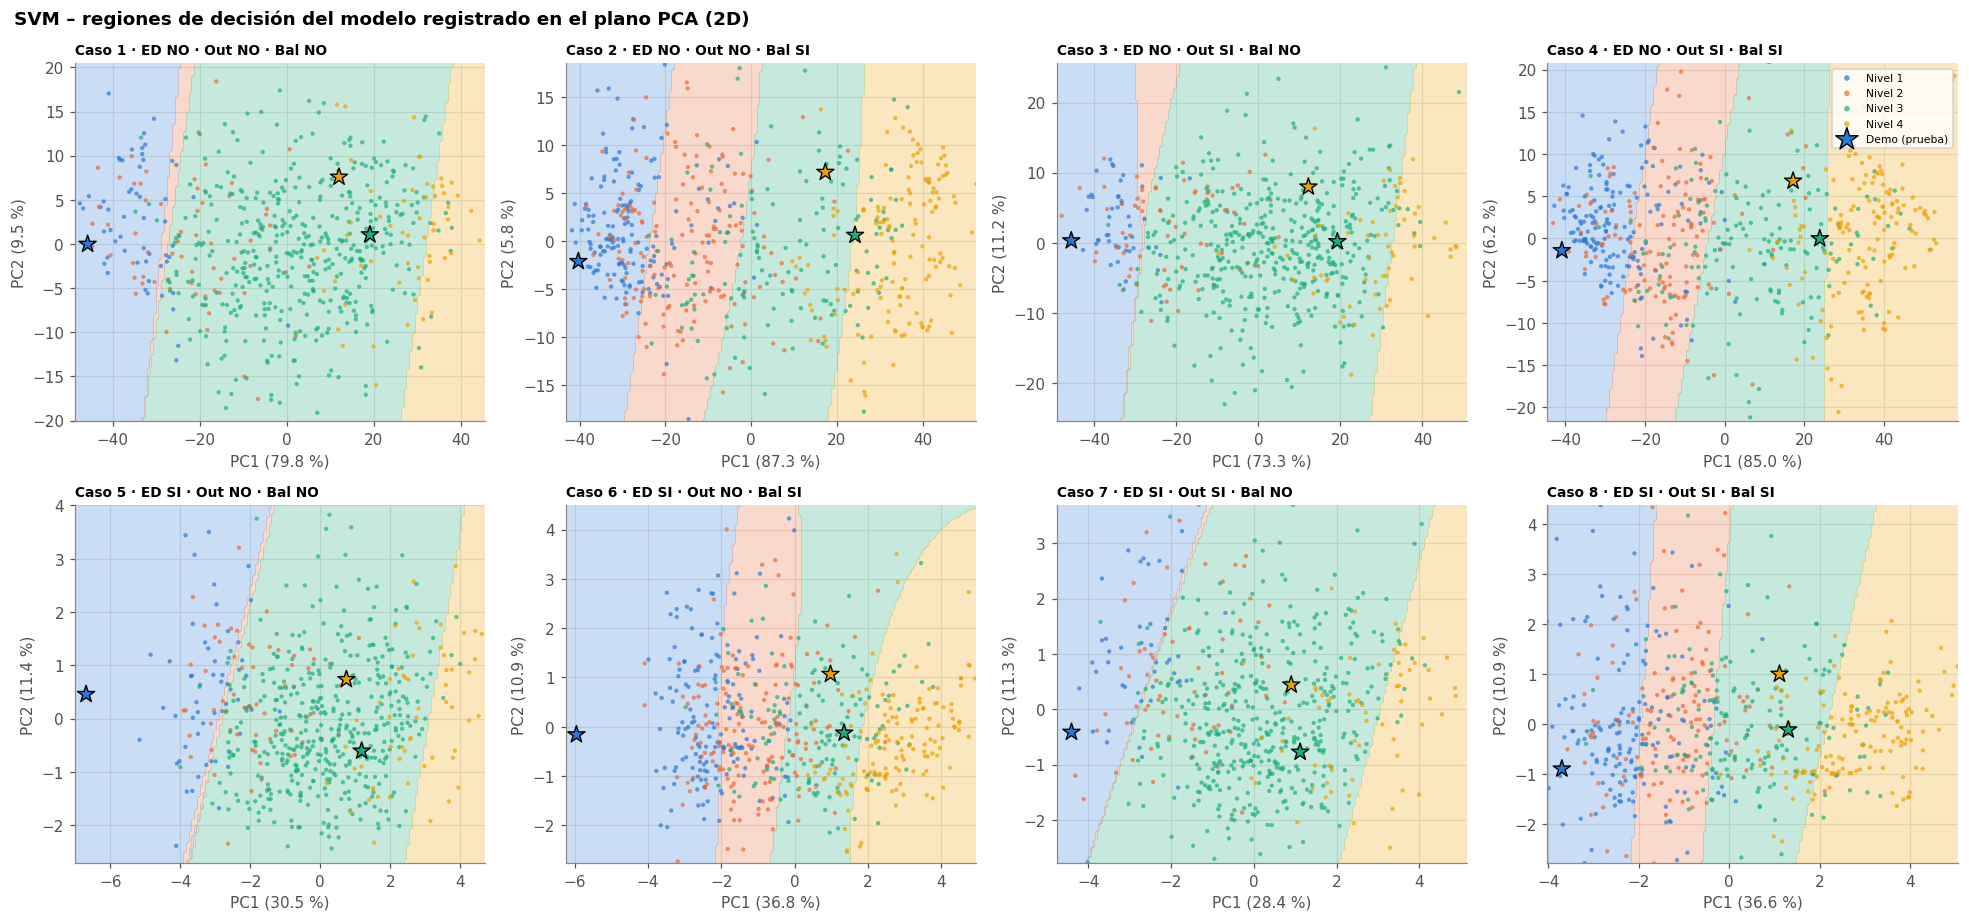

,Varianza PC1 (%),Varianza PC1+PC2 (%),Variables con más peso en PC1
Caso,,,
1,79.8,89.3,"PUNT_INGLES, PUNT_SOCIALES_CIUDADANAS, PUNT_C_..."
2,87.3,93.1,"PUNT_INGLES, PUNT_SOCIALES_CIUDADANAS, PUNT_C_..."
3,73.3,84.5,"PUNT_INGLES, PUNT_SOCIALES_CIUDADANAS, PUNT_LE..."
4,85.0,91.3,"PUNT_INGLES, PUNT_SOCIALES_CIUDADANAS, PUNT_C_..."
5,30.5,41.9,"PUNT_INGLES, PUNT_C_NATURALES, PUNT_LECTURA_CR..."
6,36.8,47.7,"PUNT_INGLES, PUNT_C_NATURALES, PUNT_SOCIALES_C..."
7,28.4,39.7,"PUNT_INGLES, PUNT_C_NATURALES, PUNT_LECTURA_CR..."
8,36.6,47.4,"PUNT_C_NATURALES, PUNT_INGLES, PUNT_SOCIALES_C..."


In [46]:
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap


def regiones_decision_svm(caso, modelo, ax, n_puntos=600, resolucion=150):
    """Regiones de decisión del SVM registrado del caso en el plano de las 2 primeras
    componentes principales, con el procedimiento del notebook de clase 7-04:
    PCA se ajusta con el entrenamiento del caso, la malla 2D se lleva al espacio de las
    65 columnas con pca.inverse_transform y se clasifica con el modelo registrado.
    PCA solo se usa para visualizar: ningún modelo se entrena con los datos reducidos.
    Se dibuja una muestra de registros de entrenamiento y los 3 registros de demostración."""
    d = casos[caso]
    pca = PCA(n_components=2, random_state=SEMILLA).fit(d["X_train"])
    Z_train = pca.transform(d["X_train"])

    X_demo_k, y_demo_k = obtener_datos_demo(caso)
    Z_demo = pca.transform(X_demo_k)

    # Malla en el plano PCA -> espacio original -> predicción del modelo registrado.
    # El rango cubre el 99 % central de los datos y los 3 registros de demostración.
    margen = 0.03 * np.ptp(Z_train, axis=0)
    x_min, x_max = np.percentile(Z_train[:, 0], [0.5, 99.5])
    y_min, y_max = np.percentile(Z_train[:, 1], [0.5, 99.5])
    x_min, x_max = min(x_min, Z_demo[:, 0].min() - margen[0]), max(x_max, Z_demo[:, 0].max() + margen[0])
    y_min, y_max = min(y_min, Z_demo[:, 1].min() - margen[1]), max(y_max, Z_demo[:, 1].max() + margen[1])
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, resolucion), np.linspace(y_min, y_max, resolucion))
    malla = pd.DataFrame(pca.inverse_transform(np.c_[xx.ravel(), yy.ravel()]), columns=d["X_train"].columns)
    regiones = modelo.predict(malla).reshape(xx.shape)
    cmap = ListedColormap([COLORES_CLASES[c] for c in CLASES])
    ax.contourf(xx, yy, regiones, levels=np.arange(-0.5, len(CLASES)), cmap=cmap, alpha=0.25)

    # Muestra de registros de entrenamiento con su clase real
    rng = np.random.default_rng(SEMILLA)
    idx = rng.choice(len(Z_train), size=min(n_puntos, len(Z_train)), replace=False)
    y_muestra = d["y_train"].to_numpy()[idx]
    for i, clase in enumerate(CLASES):
        sel = idx[y_muestra == i]
        ax.scatter(Z_train[sel, 0], Z_train[sel, 1], s=8, color=COLORES_CLASES[clase],
                   alpha=0.7, edgecolors="none", label=clase)

    # Los 3 registros de demostración (estrellas con su clase real)
    ax.scatter(Z_demo[:, 0], Z_demo[:, 1], s=140, marker="*", edgecolors="black", linewidths=0.9,
               c=[COLORES_CLASES[CLASES[v]] for v in y_demo_k], label="Demo (prueba)")

    var = pca.explained_variance_ratio_ * 100
    ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max),
           xlabel=f"PC1 ({var[0]:.1f} %)", ylabel=f"PC2 ({var[1]:.1f} %)")
    c = casos[caso]
    ax.set_title(f"Caso {caso} · ED {c['normalizacion'][-3:-1]} · Out {c['outliers']} · Bal {c['balanceo']}",
                 loc="left", fontsize=9)
    return pca


fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
PCA_SVM = {k: regiones_decision_svm(k, MODELOS_SVM[k], ax) for k, ax in zip(casos, axes.ravel())}
axes[0, 3].legend(fontsize=7, loc="upper right", markerscale=1.3)
fig.suptitle("SVM – regiones de decisión del modelo registrado en el plano PCA (2D)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

# Varianza explicada y variables con más peso en PC1 (escalado frente a sin escalar)
display(pd.DataFrame({k: {"Varianza PC1 (%)": round(p.explained_variance_ratio_[0] * 100, 1),
                          "Varianza PC1+PC2 (%)": round(p.explained_variance_ratio_.sum() * 100, 1),
                          "Variables con más peso en PC1": ", ".join(
                              pd.Series(np.abs(p.components_[0]), index=casos[k]["X_train"].columns)
                              .nlargest(3).index)}
                      for k, p in PCA_SVM.items()}).T.rename_axis("Caso"))

#### 6.1.4 Evaluación de los 3 datos de prueba

In [47]:
# Evaluación de los 3 datos de prueba de demostración en los 8 casos
display(pd.concat([predecir_demo("SVM", k, MODELOS_SVM[k]) for k in casos]))

,Técnica,Real,Predicho,P(Nivel 1),P(Nivel 2),P(Nivel 3),P(Nivel 4)
3576,SVM (caso 1),Nivel 1,Nivel 1,0.720,0.266,0.013,0.000
397,SVM (caso 1),Nivel 3,Nivel 3,0.002,0.018,0.948,0.032
4354,SVM (caso 1),Nivel 4,Nivel 3,0.000,0.006,0.932,0.061
3576,SVM (caso 2),Nivel 1,Nivel 1,0.971,0.028,0.001,0.000
397,SVM (caso 2),Nivel 3,Nivel 3,0.001,0.017,0.906,0.075
4354,SVM (caso 2),Nivel 4,Nivel 3,0.001,0.012,0.751,0.236
3576,SVM (caso 3),Nivel 1,Nivel 1,0.566,0.412,0.022,0.000
397,SVM (caso 3),Nivel 3,Nivel 3,0.001,0.042,0.875,0.082
4354,SVM (caso 3),Nivel 4,Nivel 3,0.002,0.011,0.911,0.076
3576,SVM (caso 4),Nivel 1,Nivel 1,0.803,0.195,0.002,0.000


#### 6.1.5 Caso 8: matriz de confusión y reporte por clase
*Análisis del reporte por clase y de las matrices: documento, sección 5.4.*

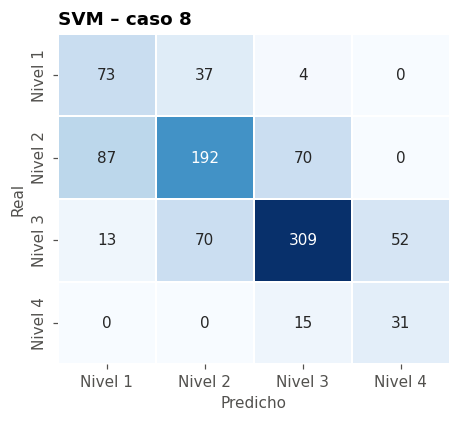

,precision,recall,f1-score,support
Nivel 1,0.4220,0.6404,0.5087,114.0000
Nivel 2,0.6421,0.5501,0.5926,349.0000
Nivel 3,0.7764,0.6959,0.7340,444.0000
Nivel 4,0.3735,0.6739,0.4806,46.0000
accuracy,0.6348,0.6348,0.6348,0.6348
macro avg,0.5535,0.6401,0.5790,953.0000
weighted avg,0.6654,0.6348,0.6430,953.0000


In [48]:
# Caso 8: matriz de confusión y reporte por clase
fig, ax = plt.subplots(figsize=(4.6, 3.9))
graficar_matriz_confusion("SVM", 8, ax=ax)
plt.show()
display(reporte_por_clase("SVM", 8))

### 6.2 Redes neuronales
#### 6.2.1 Arquitectura y proceso de configuración
Red `Sequential` con capas `Dense` y salida `Dense(4, softmax)`, pérdida `sparse_categorical_crossentropy`, lotes de 32, hasta 150 épocas y EarlyStopping (paciencia 10, restaura los mejores pesos). La configuración se elige en el caso 8 cambiando un aspecto a la vez (activación → optimizador → regularización → arquitectura); un cambio se acepta si mejora el F1 de validación en 0.01 o más. La misma red se usa en los 8 casos.

In [49]:
# ============================================================
# 6.2 Redes neuronales: construcción y entrenamiento (tf.keras, como en los notebooks 7-0x)
# ============================================================
import tensorflow as tf


def construir_red(n_entradas, capas=(64, 32), activacion="relu", optimizador="adam", lr=0.001,
                  l2=0.0, dropout=0.0):
    """Red densa (Sequential) para clasificar los 4 niveles.

    capas       : neuronas de cada capa oculta.
    activacion  : activación de las capas ocultas ("relu", "tanh" o "sigmoid").
    optimizador : "adam" o "sgd", con tasa de aprendizaje `lr`.
    l2          : penalización L2 de los pesos de las capas ocultas (0 = sin L2).
    dropout     : tasa de Dropout después de cada capa oculta (0 = sin Dropout).
    Salida Dense(4, softmax) en el orden de CLASES y pérdida sparse_categorical_crossentropy
    porque las etiquetas son enteros 0–3."""
    fijar_semillas()   # misma inicialización de pesos y mismo orden de lotes en cada red
    modelo = tf.keras.Sequential([tf.keras.layers.Input(shape=(n_entradas,))])
    for neuronas in capas:
        modelo.add(tf.keras.layers.Dense(
            neuronas, activation=activacion,
            kernel_regularizer=tf.keras.regularizers.l2(l2) if l2 else None))
        if dropout:
            modelo.add(tf.keras.layers.Dropout(dropout))
    modelo.add(tf.keras.layers.Dense(len(CLASES), activation="softmax"))
    opt = (tf.keras.optimizers.Adam(learning_rate=lr) if optimizador == "adam"
           else tf.keras.optimizers.SGD(learning_rate=lr))
    modelo.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo


def entrenar_red(caso, config, epocas=150, tamano_lote=32, paciencia=10):
    """Construye y entrena la red del caso con `config` (argumentos de construir_red).
    El conjunto de validación es el validation_data: lo usa el callback EarlyStopping,
    que detiene el entrenamiento cuando la pérdida de validación deja de mejorar durante
    `paciencia` épocas y restaura los pesos de la mejor época.
    Retorna (modelo, historia, F1 macro de validación)."""
    d = casos[caso]
    X_tr, X_va = d["X_train"].to_numpy("float32"), d["X_val"].to_numpy("float32")
    modelo = construir_red(X_tr.shape[1], **config)
    parada = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia,
                                              restore_best_weights=True)
    historia = modelo.fit(X_tr, d["y_train"].to_numpy(), validation_data=(X_va, d["y_val"].to_numpy()),
                          epochs=epocas, batch_size=tamano_lote, verbose=0, callbacks=[parada])
    y_pred_val = modelo.predict(X_va, verbose=0).argmax(axis=1)
    return modelo, historia, f1_score(d["y_val"], y_pred_val, average="macro")

In [50]:
CASO_CONFIGURACION = 8   # caso con todo el preprocesamiento aplicado


def comparar_configs_red(variantes, caso=CASO_CONFIGURACION):
    """Entrena cada configuración de `variantes` ({nombre: config}) en el caso indicado.
    Retorna (tabla, historias). La tabla tiene el F1 macro y el accuracy de validación,
    la mejor época (la que restaura EarlyStopping), las épocas entrenadas y la brecha
    entre la pérdida de validación y la de entrenamiento en la mejor época."""
    filas, historias = [], {}
    for nombre, config in variantes.items():
        _, historia, f1_val = entrenar_red(caso, config)
        h = historia.history
        mejor = int(np.argmin(h["val_loss"]))
        filas.append({"Configuración": nombre, "F1 val": round(f1_val, 4),
                      "Accuracy val": round(h["val_accuracy"][mejor], 4),
                      "Mejor época": mejor + 1, "Épocas entrenadas": len(h["loss"]),
                      "Brecha pérdida val - train": round(h["val_loss"][mejor] - h["loss"][mejor], 4)})
        historias[nombre] = h
    return pd.DataFrame(filas).set_index("Configuración"), historias


def graficar_curvas_variantes(historias, titulo, metrica="loss", etiqueta="Pérdida"):
    """Curvas de entrenamiento (línea continua) y validación (línea discontinua) de cada
    variante, como en los notebooks de clase 7-05 y 7-06."""
    fig, ax = plt.subplots(figsize=(8, 4))
    for i, (nombre, h) in enumerate(historias.items()):
        ax.plot(h[metrica], color=COLORES_SERIES[i], label=f"{nombre} – train")
        ax.plot(h[f"val_{metrica}"], "--", color=COLORES_SERIES[i], label=f"{nombre} – val")
    ax.set(title=titulo, xlabel="Época", ylabel=etiqueta)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7, ncol=2)
    plt.tight_layout()
    plt.show()


def elegir_variante(tabla, vigente, tolerancia=0.01):
    """Retorna el nombre de la variante con mayor F1 de validación. Si su mejora frente a
    la variante `vigente` es menor que `tolerancia`, conserva la vigente: con una sola
    semilla y 952 registros de validación, diferencias menores no son concluyentes."""
    mejor = tabla["F1 val"].idxmax()
    return mejor if tabla.loc[mejor, "F1 val"] - tabla.loc[vigente, "F1 val"] >= tolerancia else vigente


# Configuración base: 2 capas ocultas [64, 32], ReLU, Adam (lr = 0.001), sin regularización
CONFIG_BASE_RED = {"capas": (64, 32), "activacion": "relu", "optimizador": "adam", "lr": 0.001}
CONFIG_RED = dict(CONFIG_BASE_RED)   # se actualiza al final de cada etapa
COMPARACION_RED = {}                 # etapa -> (tabla, historias)
inicio_cfg = time.time()

In [51]:
# Etapa 1: función de activación de las capas ocultas (como en el notebook 7-04)
VARIANTES_ACTIVACION = {act: {**CONFIG_RED, "activacion": act} for act in ("relu", "tanh", "sigmoid")}
COMPARACION_RED["activacion"] = comparar_configs_red(VARIANTES_ACTIVACION)
eleccion = elegir_variante(COMPARACION_RED["activacion"][0], vigente="relu")
CONFIG_RED = VARIANTES_ACTIVACION[eleccion]
display(COMPARACION_RED["activacion"][0])
print("Elegida:", eleccion)

,F1 val,Accuracy val,Mejor época,Épocas entrenadas,Brecha pérdida val - train
Configuración,,,,,
relu,0.5981,0.6397,7,17,0.2756
tanh,0.6012,0.6366,11,21,0.2882
sigmoid,0.6047,0.6502,40,50,0.2583


Elegida: relu


,F1 val,Accuracy val,Mejor época,Épocas entrenadas,Brecha pérdida val - train
Configuración,,,,,
Adam (lr=0.001),0.5981,0.6397,7,17,0.2756
Adam (lr=0.01),0.5624,0.6282,1,11,0.1196
SGD (lr=0.1),0.4884,0.6492,2,12,0.2163


Elegido: Adam (lr=0.001)


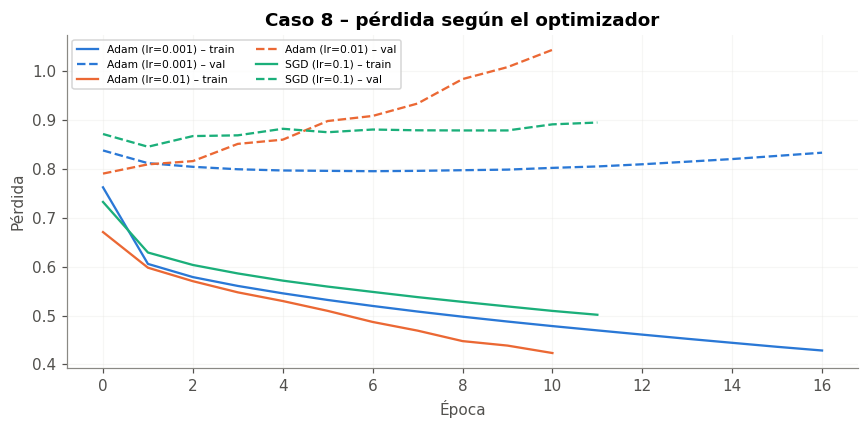

In [52]:
# Etapa 2: optimizador y tasa de aprendizaje (como en el notebook 7-05)
VARIANTES_OPTIMIZADOR = {
    "Adam (lr=0.001)": {**CONFIG_RED, "optimizador": "adam", "lr": 0.001},
    "Adam (lr=0.01)":  {**CONFIG_RED, "optimizador": "adam", "lr": 0.01},
    "SGD (lr=0.1)":    {**CONFIG_RED, "optimizador": "sgd", "lr": 0.1}}
COMPARACION_RED["optimizador"] = comparar_configs_red(VARIANTES_OPTIMIZADOR)
eleccion = elegir_variante(COMPARACION_RED["optimizador"][0], vigente="Adam (lr=0.001)")
CONFIG_RED = VARIANTES_OPTIMIZADOR[eleccion]
display(COMPARACION_RED["optimizador"][0])
print("Elegido:", eleccion)
graficar_curvas_variantes(COMPARACION_RED["optimizador"][1], "Caso 8 – pérdida según el optimizador")

,F1 val,Accuracy val,Mejor época,Épocas entrenadas,Brecha pérdida val - train
Configuración,,,,,
Sin regularización,0.5981,0.6397,7,17,0.2756
L2 (0.01),0.6068,0.6408,36,46,0.2207
Dropout (0.3),0.6231,0.6649,11,21,0.1742
L2 + Dropout,0.6026,0.6376,30,40,0.1411


Elegida: Dropout (0.3)


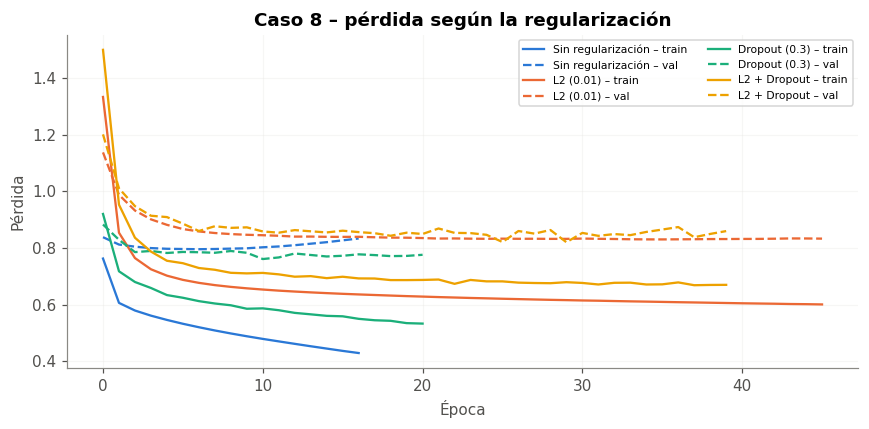

In [53]:
# Etapa 3: regularización vista en clase (notebook 7-06), siempre con EarlyStopping
VARIANTES_REGULARIZACION = {
    "Sin regularización": {**CONFIG_RED},
    "L2 (0.01)":          {**CONFIG_RED, "l2": 0.01},
    "Dropout (0.3)":      {**CONFIG_RED, "dropout": 0.3},
    "L2 + Dropout":       {**CONFIG_RED, "l2": 0.01, "dropout": 0.3}}
COMPARACION_RED["regularizacion"] = comparar_configs_red(VARIANTES_REGULARIZACION)
# La red final debe llevar regularización: se elige entre las variantes regularizadas
tabla_reg = COMPARACION_RED["regularizacion"][0].drop(index="Sin regularización")
eleccion = tabla_reg["F1 val"].idxmax()
CONFIG_RED = VARIANTES_REGULARIZACION[eleccion]
display(COMPARACION_RED["regularizacion"][0])
print("Elegida:", eleccion)
graficar_curvas_variantes(COMPARACION_RED["regularizacion"][1], "Caso 8 – pérdida según la regularización")

In [54]:
# Etapa 4: número de capas ocultas y neuronas, con la regularización elegida
VARIANTES_ARQUITECTURA = {
    "[32]":      {**CONFIG_RED, "capas": (32,)},
    "[64, 32]":  {**CONFIG_RED, "capas": (64, 32)},
    "[128, 64]": {**CONFIG_RED, "capas": (128, 64)}}
COMPARACION_RED["arquitectura"] = comparar_configs_red(VARIANTES_ARQUITECTURA)
eleccion = elegir_variante(COMPARACION_RED["arquitectura"][0], vigente="[64, 32]")
CONFIG_RED_FINAL = VARIANTES_ARQUITECTURA[eleccion]
display(COMPARACION_RED["arquitectura"][0])
print("Elegida:", eleccion)
print("Configuración final:", CONFIG_RED_FINAL)
print(f"Tiempo del proceso de configuración: {time.time() - inicio_cfg:.0f} s")

,F1 val,Accuracy val,Mejor época,Épocas entrenadas,Brecha pérdida val - train
Configuración,,,,,
[32],0.6114,0.6513,17,27,0.1964
"[64, 32]",0.6231,0.6649,11,21,0.1742
"[128, 64]",0.6085,0.6502,9,19,0.2223


Elegida: [64, 32]
Configuración final: {'capas': (64, 32), 'activacion': 'relu', 'optimizador': 'adam', 'lr': 0.001, 'dropout': 0.3}
Tiempo del proceso de configuración: 265 s


#### 6.2.2 Entrenamiento en los 8 casos

In [55]:
# Red final en los 8 casos: misma arquitectura y regularización en todos
inicio_red = time.time()
MODELOS_RED, HISTORIAS_RED = {}, {}
for k in casos:
    MODELOS_RED[k], historia_k, _ = entrenar_red(k, CONFIG_RED_FINAL)
    HISTORIAS_RED[k] = historia_k.history
    registrar_resultado("Redes Neuronales", k, MODELOS_RED[k],
                        {**CONFIG_RED_FINAL, "early_stopping_paciencia": 10,
                         "épocas": len(historia_k.history["loss"])})
print(f"\nTiempo redes (8 casos): {time.time() - inicio_red:.0f} s")

Redes Neuronales | caso 1 | Accuracy: 0.5373 | Precision: 0.2405 | Recall: 0.4431 | F1: 0.3085
Redes Neuronales | caso 2 | Accuracy: 0.6170 | Precision: 0.5455 | Recall: 0.6633 | F1: 0.5729
Redes Neuronales | caso 3 | Accuracy: 0.5278 | Precision: 0.2653 | Recall: 0.3843 | F1: 0.3069
Redes Neuronales | caso 4 | Accuracy: 0.6432 | Precision: 0.5669 | Recall: 0.6677 | F1: 0.5953
Redes Neuronales | caso 5 | Accuracy: 0.5624 | Precision: 0.5653 | Recall: 0.5562 | F1: 0.4668
Redes Neuronales | caso 6 | Accuracy: 0.6359 | Precision: 0.5558 | Recall: 0.6369 | F1: 0.5794
Redes Neuronales | caso 7 | Accuracy: 0.6065 | Precision: 0.6129 | Recall: 0.5820 | F1: 0.5402
Redes Neuronales | caso 8 | Accuracy: 0.6411 | Precision: 0.5613 | Recall: 0.6535 | F1: 0.5871

Tiempo redes (8 casos): 125 s


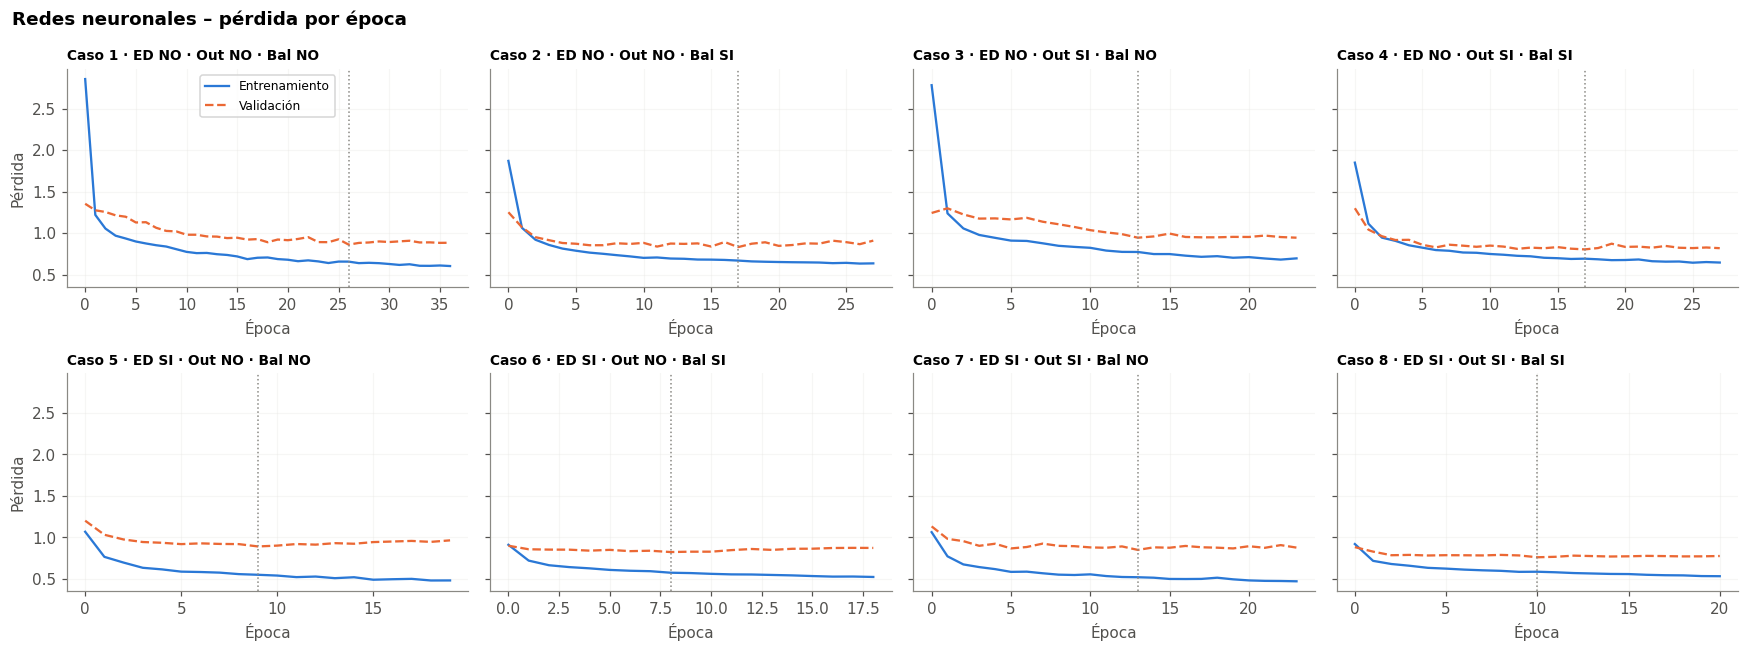

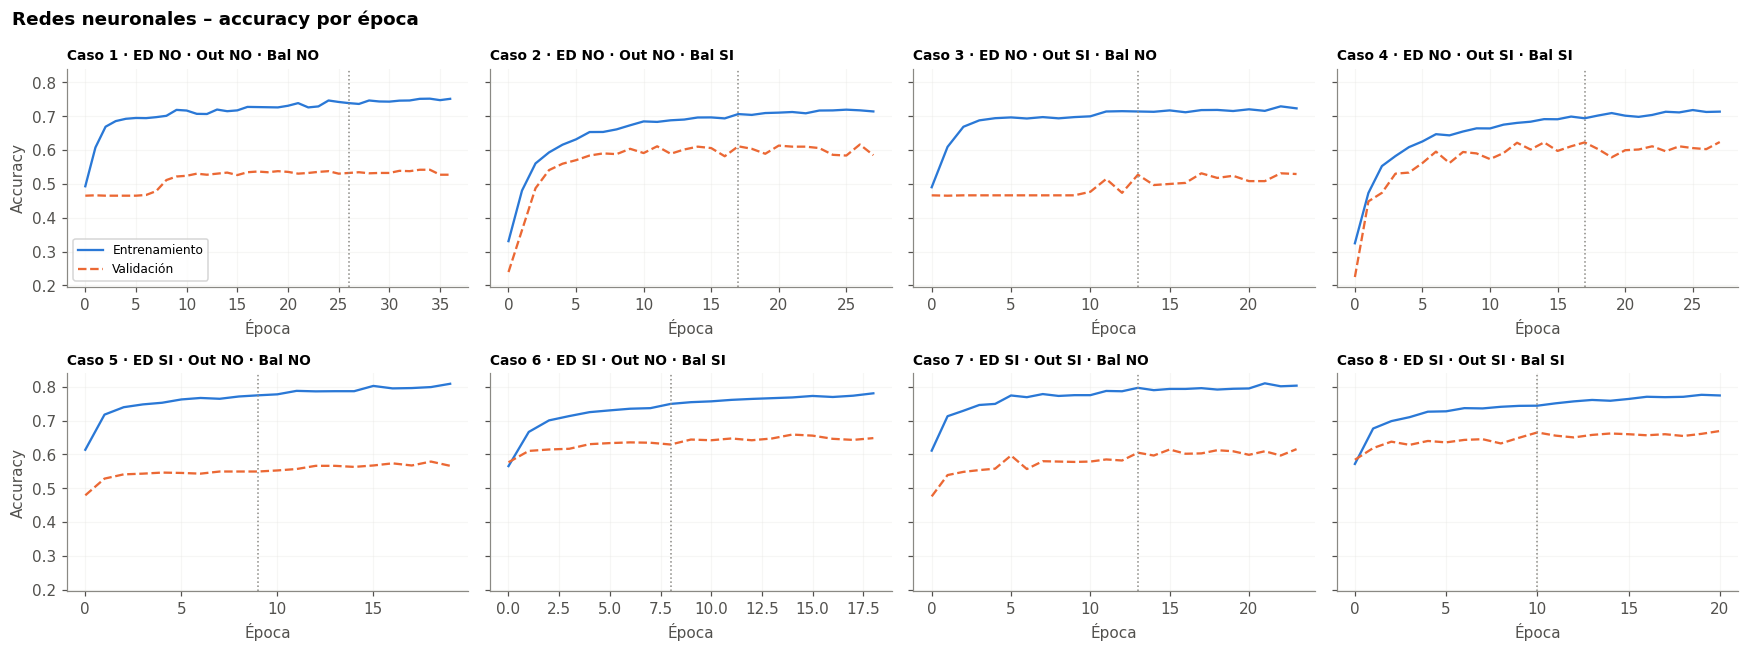

,ED,Épocas entrenadas,Mejor época,Pérdida train,Pérdida val,Pérdida val época 1,Desv. est. accuracy val (épocas ≥ 5)
Caso,,,,,,,
1,NO,37,27,0.6569,0.8613,1.3535,0.0214
2,NO,28,18,0.6695,0.8315,1.2515,0.0145
3,NO,24,14,0.7731,0.9449,1.2426,0.0252
4,NO,28,18,0.6925,0.8041,1.2997,0.0214
5,SI,20,10,0.5497,0.8908,1.201,0.0107
6,SI,19,9,0.5745,0.8234,0.8995,0.0083
7,SI,24,14,0.5201,0.8489,1.1321,0.0171
8,SI,21,11,0.5864,0.7606,0.8825,0.0102


In [56]:
def graficar_curvas_red(historias=HISTORIAS_RED, metrica="loss", etiqueta="Pérdida"):
    """Curvas de entrenamiento y validación de la red final en los 8 casos para `metrica`
    ("loss" o "accuracy"). La línea vertical marca la época restaurada por EarlyStopping."""
    fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharey=True)
    for ax, (k, h) in zip(axes.ravel(), historias.items()):
        ax.plot(h[metrica], color=COLORES_SERIES[0], label="Entrenamiento")
        ax.plot(h[f"val_{metrica}"], "--", color=COLORES_SERIES[1], label="Validación")
        ax.axvline(int(np.argmin(h["val_loss"])), color="#8a8984", linestyle=":", linewidth=1)
        c = casos[k]
        ax.set_title(f"Caso {k} · ED {c['normalizacion'][-3:-1]} · Out {c['outliers']} · Bal {c['balanceo']}",
                     loc="left", fontsize=9)
        ax.set_xlabel("Época")
        ax.grid(True, alpha=0.3)
    for ax in axes[:, 0]:
        ax.set_ylabel(etiqueta)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"Redes neuronales – {etiqueta.lower()} por época", x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


def resumen_entrenamiento_red(historias=HISTORIAS_RED):
    """Por caso: épocas entrenadas, mejor época, pérdidas en la mejor época, pérdida de
    validación en la primera época y desviación estándar del accuracy de validación desde
    la época 5 (mide qué tan inestable es el entrenamiento)."""
    filas = {}
    for k, h in historias.items():
        mejor = int(np.argmin(h["val_loss"]))
        filas[k] = {"ED": casos[k]["normalizacion"][-3:-1], "Épocas entrenadas": len(h["loss"]),
                    "Mejor época": mejor + 1, "Pérdida train": round(h["loss"][mejor], 4),
                    "Pérdida val": round(h["val_loss"][mejor], 4),
                    "Pérdida val época 1": round(h["val_loss"][0], 4),
                    "Desv. est. accuracy val (épocas ≥ 5)": round(float(np.std(h["val_accuracy"][4:])), 4)}
    return pd.DataFrame(filas).T.rename_axis("Caso")


graficar_curvas_red(metrica="loss", etiqueta="Pérdida")
graficar_curvas_red(metrica="accuracy", etiqueta="Accuracy")
display(resumen_entrenamiento_red())

In [57]:
def verificar_paciencia(casos_ver=(1, 3), paciencias=(10, 30), config=CONFIG_RED_FINAL):
    """Reentrena la red final con distintas paciencias de EarlyStopping y reporta el F1 de
    validación y cuántos registros de validación se asignan a cada clase. Sirve para
    comprobar si una red que no predice alguna clase solo necesitaba más épocas."""
    filas = []
    for k in casos_ver:
        for paciencia in paciencias:
            modelo, historia, f1_val = entrenar_red(k, config, epocas=300, paciencia=paciencia)
            y_pred_val = predecir_con_probabilidades(modelo, casos[k]["X_val"])[0]
            filas.append({"Caso": k, "Paciencia": paciencia, "F1 val": round(f1_val, 4),
                          "Épocas entrenadas": len(historia.history["loss"]),
                          **{f"Predichos {c}": int(n) for c, n in zip(CLASES, np.bincount(y_pred_val, minlength=len(CLASES)))}})
    return pd.DataFrame(filas).set_index(["Caso", "Paciencia"])


display(verificar_paciencia())

F1 val  Épocas entrenadas  Predichos Nivel 1  Predichos Nivel 2  Predichos Nivel 3  Predichos Nivel 4
Caso Paciencia                                                                                                       
1    10         0.3116                 37                293                  0                658                  1
     30         0.3116                 57                293                  0                658                  1
3    10         0.3038                 24                124                  0                828                  0
     30         0.3263                 70                177                  0                773                  2

#### 6.2.3 Evaluación de los 3 datos de prueba

In [58]:
# Evaluación de los 3 datos de prueba de demostración en los 8 casos
display(pd.concat([predecir_demo("Redes Neuronales", k, MODELOS_RED[k]) for k in casos]))

,Técnica,Real,Predicho,P(Nivel 1),P(Nivel 2),P(Nivel 3),P(Nivel 4)
3576,Redes Neuronales (caso 1),Nivel 1,Nivel 1,0.743,0.221,0.036,0.000
397,Redes Neuronales (caso 1),Nivel 3,Nivel 3,0.001,0.022,0.937,0.040
4354,Redes Neuronales (caso 1),Nivel 4,Nivel 3,0.002,0.035,0.917,0.047
3576,Redes Neuronales (caso 2),Nivel 1,Nivel 1,0.979,0.021,0.000,0.000
397,Redes Neuronales (caso 2),Nivel 3,Nivel 3,0.000,0.034,0.928,0.038
4354,Redes Neuronales (caso 2),Nivel 4,Nivel 3,0.000,0.079,0.867,0.054
3576,Redes Neuronales (caso 3),Nivel 1,Nivel 1,0.417,0.306,0.276,0.002
397,Redes Neuronales (caso 3),Nivel 3,Nivel 3,0.004,0.019,0.818,0.160
4354,Redes Neuronales (caso 3),Nivel 4,Nivel 3,0.024,0.065,0.750,0.161
3576,Redes Neuronales (caso 4),Nivel 1,Nivel 1,0.593,0.361,0.045,0.000


#### 6.2.4 Caso 8: matriz de confusión y reporte por clase
*Análisis del reporte por clase y de las matrices: documento, sección 5.4.*

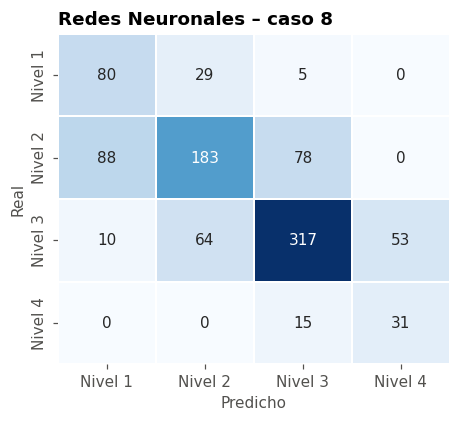

,precision,recall,f1-score,support
Nivel 1,0.4494,0.7018,0.5479,114.0000
Nivel 2,0.6630,0.5244,0.5856,349.0000
Nivel 3,0.7639,0.7140,0.7381,444.0000
Nivel 4,0.3690,0.6739,0.4769,46.0000
accuracy,0.6411,0.6411,0.6411,0.6411
macro avg,0.5613,0.6535,0.5871,953.0000
weighted avg,0.6703,0.6411,0.6469,953.0000


In [59]:
# Caso 8: matriz de confusión y reporte por clase
fig, ax = plt.subplots(figsize=(4.6, 3.9))
graficar_matriz_confusion("Redes Neuronales", 8, ax=ax)
plt.show()
display(reporte_por_clase("Redes Neuronales", 8))

### 6.3 Resumen de SVM y redes neuronales

In [60]:
# ============================================================
# 6.3 Resumen de SVM y redes neuronales
# ============================================================
def resumen_bloque3(algoritmos=("SVM", "Redes Neuronales")):
    """Métricas de prueba por caso de los algoritmos de la sección (tomadas de la Figura 1)
    y F1 macro medio por factor de preprocesamiento (escalado, outliers y balanceo)."""
    tabla = tabla_figura1()[[(a, m) for a in algoritmos for m in METRICAS]]
    config = pd.DataFrame({k: {"ED": c["normalizacion"][-3:-1], "Outliers": c["outliers"],
                               "Balanceo": c["balanceo"]} for k, c in casos.items()}).T
    f1 = pd.concat([config, tabla.xs("F1", axis=1, level=1).astype(float)], axis=1)
    promedios = pd.concat({factor: f1.groupby(factor)[list(algoritmos)].mean()
                           for factor in ("ED", "Outliers", "Balanceo")}).round(4)
    return tabla, promedios


TABLA_BLOQUE3, PROMEDIOS_BLOQUE3 = resumen_bloque3()
display(TABLA_BLOQUE3)
print("F1 macro medio por factor de preprocesamiento:")
display(PROMEDIOS_BLOQUE3)

SVM                           Redes Neuronales                          
     Accuracy Precision  Recall      F1         Accuracy Precision  Recall      F1
Caso                                                                              
1      0.5897    0.5835  0.5792  0.5186           0.5373    0.2405  0.4431  0.3085
2       0.639    0.5702  0.6981  0.6012            0.617    0.5455  0.6633  0.5729
3      0.5887    0.6009  0.5636   0.516           0.5278    0.2653  0.3843  0.3069
4      0.6432    0.5649  0.6631  0.5932           0.6432    0.5669  0.6677  0.5953
5      0.5876     0.582  0.5718  0.5148           0.5624    0.5653  0.5562  0.4668
6      0.6432    0.5581  0.6236    0.58           0.6359    0.5558  0.6369  0.5794
7      0.5866    0.6005  0.5622  0.5135           0.6065    0.6129   0.582  0.5402
8      0.6348    0.5535  0.6401   0.579           0.6411    0.5613  0.6535  0.5871

F1 macro medio por factor de preprocesamiento:


SVM  Redes Neuronales
         ED                          
ED       NO  0.5572            0.4459
         SI  0.5468            0.5434
Outliers NO  0.5536            0.4819
         SI  0.5504            0.5074
Balanceo NO  0.5157            0.4056
         SI  0.5883            0.5837

## 7. Evaluación comparativa
Figura 1, gráficas de F1, curvas ROC/PR del caso 8, costo de los errores y predicción de los 3 estudiantes hipotéticos. Todas las cifras salen de lo registrado con `registrar_resultado`. *Análisis: documento, sección 5.*

### 7.1 Tabla de la Figura 1
Métricas de prueba (promedio `macro`) de los 4 algoritmos en los 8 casos, y el mejor algoritmo de cada caso.

In [61]:
# ============================================================
# 7.1 Tabla de la Figura 1
# ============================================================
FIGURA1 = tabla_figura1()
display(FIGURA1)


def f1_por_caso(resultados=RESULTADOS):
    """F1 macro de prueba por caso (filas) y algoritmo (columnas), con la configuración del
    caso (ED, Outliers, Balanceo). Es la base de las gráficas de la sección 7.2."""
    filas = {}
    for k, c in casos.items():
        fila = {"ED": c["normalizacion"][-3:-1], "Outliers": c["outliers"], "Balanceo": c["balanceo"]}
        fila.update({alg: resultados[(alg, k)]["F1"] for alg in ALGORITMOS})
        filas[k] = fila
    tabla = pd.DataFrame(filas).T
    tabla[ALGORITMOS] = tabla[ALGORITMOS].astype(float)
    tabla.index.name = "Caso"
    return tabla


def mejor_por_caso(f1):
    """Algoritmo con el mayor F1 en cada caso, el segundo mejor y la diferencia entre ambos."""
    filas = []
    for k, fila in f1[ALGORITMOS].iterrows():
        orden = fila.sort_values(ascending=False)
        filas.append({"Caso": k, "Mejor": orden.index[0], "F1 mejor": orden.iloc[0],
                      "Segundo": orden.index[1], "F1 segundo": orden.iloc[1],
                      "Diferencia": orden.iloc[0] - orden.iloc[1]})
    return pd.DataFrame(filas).set_index("Caso").round(4)


F1_CASOS = f1_por_caso()
display(mejor_por_caso(F1_CASOS))

Configuración                    Árboles                                KNN                                SVM                            \
        Normalización Outliers Balanceo Accuracy Precision  Recall      F1 Accuracy Precision  Recall      F1 Accuracy Precision  Recall      F1   
Caso                                                                                                                                               
1     CC(SI) y ED(NO)       NO       NO   0.6055    0.6056  0.5424  0.5371    0.595    0.6539  0.5727  0.5268   0.5897    0.5835  0.5792  0.5186   
2     CC(SI) y ED(NO)       NO       SI   0.6159    0.5533  0.6293  0.5771   0.5771    0.5027  0.5632   0.524    0.639    0.5702  0.6981  0.6012   
3     CC(SI) y ED(NO)       SI       NO    0.617    0.6181  0.5247  0.5306   0.5719    0.6462  0.5609  0.4864   0.5887    0.6009  0.5636   0.516   
4     CC(SI) y ED(NO)       SI       SI   0.6317    0.5631  0.6674  0.5915   0.5792     0.504   0.554  0.5227   0.6432    0.5649  0.6631  0.5932   
5     CC(SI) y ED(SI)       NO       NO   0.6055    0.6056  0.5424  0.5371   0.5635     0.625  0.4754  0.4381   0.5876     0.582  0.5718  0.5148   
6     CC(SI) y ED(SI)       NO       SI   0.6159    0.5533  0.6293  0.5771   0.5016    0.4304  0.4993  0.4444   0.6432    0.5581  0.6236    0.58   
7     CC(SI) y ED(SI)       SI       NO    0.617    0.6181  0.5247  0.5306   0.5498    0.6276  0.4664  0.4291   0.5866    0.6005  0.5622  0.5135   
8     CC(SI) y ED(SI)       SI       SI   0.6317    0.5631  0.6674  0.5915   0.4911    0.4253  0.4953  0.4425   0.6348    0.5535  0.6401   0.579   

     Redes Neuronales                            
             Accuracy Precision  Recall      F1  
Caso                                             
1              0.5373    0.2405  0.4431  0.3085  
2               0.617    0.5455  0.6633  0.5729  
3              0.5278    0.2653  0.3843  0.3069  
4              0.6432    0.5669  0.6677  0.5953  
5              0.5624    0.5653  0.5562  0.4668  
6              0.6359    0.5558  0.6369  0.5794  
7              0.6065    0.6129   0.582  0.5402  
8              0.6411    0.5613  0.6535  0.5871

,Mejor,F1 mejor,Segundo,F1 segundo,Diferencia
Caso,,,,,
1,Árboles,0.5371,KNN,0.5268,0.0103
2,SVM,0.6012,Árboles,0.5771,0.0241
3,Árboles,0.5306,SVM,0.5160,0.0146
4,Redes Neuronales,0.5953,SVM,0.5932,0.0021
5,Árboles,0.5371,SVM,0.5148,0.0223
6,SVM,0.5800,Redes Neuronales,0.5794,0.0006
7,Redes Neuronales,0.5402,Árboles,0.5306,0.0096
8,Árboles,0.5915,Redes Neuronales,0.5871,0.0044


### 7.2 Gráficas de F1 de la Figura 1

In [62]:
# ============================================================
# 7.2 Gráficas de F1 de la Figura 1
# ============================================================
# Nombre de cada factor y de sus dos niveles en las leyendas
ETIQUETAS_FACTOR = {
    "ED": ("normalización", {"NO": "Sin ED (NO)", "SI": "Con ED (SI)"}),
    "Outliers": ("manejo de datos atípicos", {"NO": "Sin outliers (NO)", "SI": "Con outliers 5 % (SI)"}),
    "Balanceo": ("balanceo", {"NO": "Desbalanceado (NO)", "SI": "Balanceado (SI)"}),
}


def graficar_f1_maximo(f1=F1_CASOS):
    """Diagrama de barras con el F1 máximo de cada algoritmo en los 8 casos. Cada barra indica
    el caso (o los casos, si hay empate) en que se alcanza. Retorna la tabla graficada."""
    maximos = f1[ALGORITMOS].max()
    casos_max = {alg: f1.index[f1[alg] == maximos[alg]].tolist() for alg in ALGORITMOS}
    fig, ax = plt.subplots(figsize=(8, 4.2))
    barras = ax.bar(ALGORITMOS, maximos, color=COLOR_PRINCIPAL, width=0.6)
    ax.bar_label(barras, fontsize=9, labels=[
        f"{maximos[alg]:.4f}\ncaso{'s' if len(casos_max[alg]) > 1 else ''} "
        f"{', '.join(map(str, casos_max[alg]))}" for alg in ALGORITMOS])
    ax.set_ylim(0, 0.8)
    ax.set_ylabel("F1 macro (prueba)")
    ax.grid(axis="x", visible=False)
    ax.set_title("F1-Score máximo por algoritmo (general)", loc="left")
    plt.tight_layout()
    plt.show()
    return pd.DataFrame({"F1 máximo": maximos.round(4),
                         "Caso(s)": [", ".join(map(str, casos_max[a])) for a in ALGORITMOS]})


def f1_medio_por_factor(factor, f1=F1_CASOS):
    """F1 medio de cada algoritmo en los 4 casos con el factor en NO y en los 4 casos con el
    factor en SI, y la diferencia SI − NO."""
    medias = f1.groupby(factor)[ALGORITMOS].mean().reindex(["NO", "SI"]).T
    medias["Diferencia (SI − NO)"] = medias["SI"] - medias["NO"]
    return medias.round(4)


def graficar_f1_por_factor(factor, f1=F1_CASOS):
    """Barras agrupadas por algoritmo con el F1 medio del factor en NO y en SI
    (factor: "ED", "Outliers" o "Balanceo"). Retorna la tabla graficada."""
    nombre, etiquetas = ETIQUETAS_FACTOR[factor]
    medias = f1_medio_por_factor(factor, f1)
    x, ancho = np.arange(len(ALGORITMOS)), 0.38
    fig, ax = plt.subplots(figsize=(9, 4.4))
    for i, nivel in enumerate(["NO", "SI"]):
        barras = ax.bar(x + (i - 0.5) * ancho, medias[nivel], ancho, color=COLORES_SERIES[i],
                        label=etiquetas[nivel])
        ax.bar_label(barras, fmt="%.4f", fontsize=8)
    ax.set_xticks(x, ALGORITMOS)
    ax.set_ylim(0, 0.8)
    ax.set_ylabel("F1 macro medio (prueba)")
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left", ncol=2, frameon=False)
    ax.set_title(f"F1-Score medio por {nombre} y algoritmo (4 casos por barra)", loc="left")
    plt.tight_layout()
    plt.show()
    return medias

#### 7.2.1 F1-Score máximo por algoritmo (general)

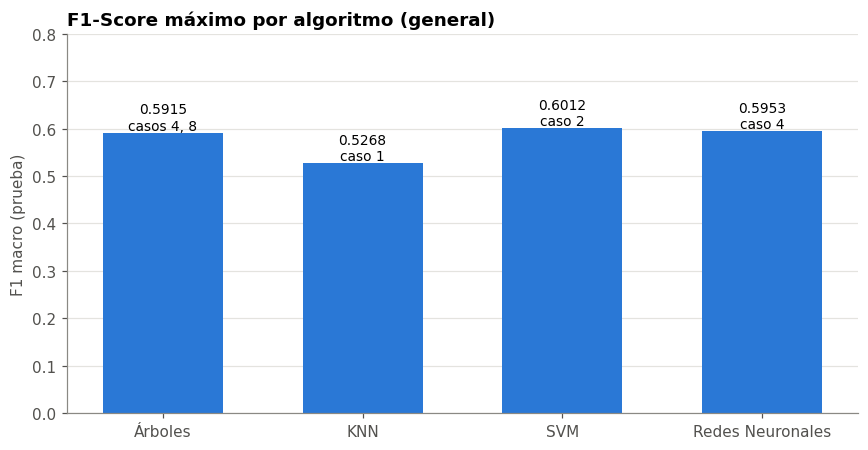

,F1 máximo,Caso(s)
Árboles,0.5915,"4, 8"
KNN,0.5268,1
SVM,0.6012,2
Redes Neuronales,0.5953,4


In [63]:
display(graficar_f1_maximo())

#### 7.2.2 F1-Score medio por normalización: sensibilidad a la escala

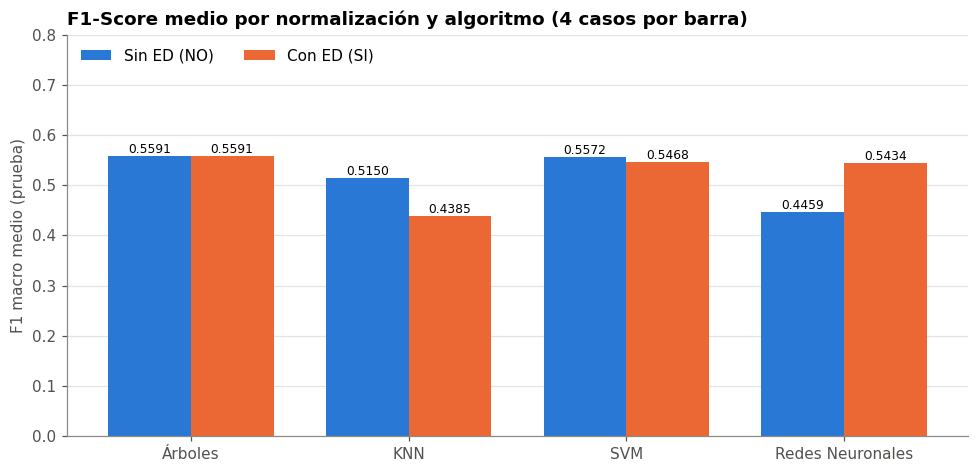

ED,NO,SI,Diferencia (SI − NO)
Árboles,0.5591,0.5591,0.0000
KNN,0.5150,0.4385,-0.0765
SVM,0.5572,0.5468,-0.0104
Redes Neuronales,0.4459,0.5434,0.0975


In [64]:
display(graficar_f1_por_factor("ED"))

#### 7.2.3 F1-Score medio por manejo de datos atípicos

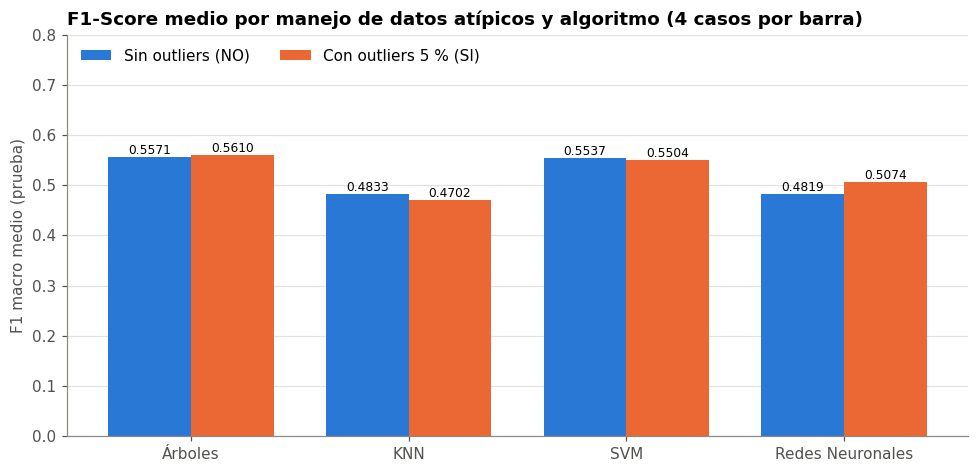

Outliers,NO,SI,Diferencia (SI − NO)
Árboles,0.5571,0.5610,0.0039
KNN,0.4833,0.4702,-0.0131
SVM,0.5537,0.5504,-0.0032
Redes Neuronales,0.4819,0.5074,0.0255


In [65]:
display(graficar_f1_por_factor("Outliers"))

#### 7.2.4 F1-Score medio por balanceo: por qué el accuracy engaña

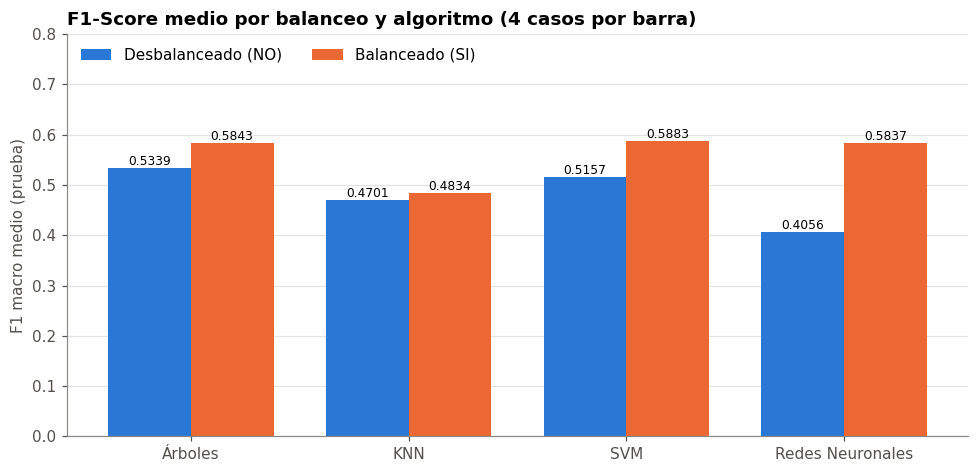

Balanceo,NO,SI,Diferencia (SI − NO)
Árboles,0.5339,0.5843,0.0505
KNN,0.4701,0.4834,0.0133
SVM,0.5157,0.5883,0.0726
Redes Neuronales,0.4056,0.5837,0.1780


Accuracy      F1  Accuracy − F1  Recall Nivel 1  Recall Nivel 2  Recall Nivel 3  Recall Nivel 4
Algoritmo        Balanceo                                                                                                 
Árboles          NO          0.6112  0.5339         0.0774          0.5614          0.2536          0.9279          0.3913
                 SI          0.6238  0.5843         0.0395          0.7061          0.4957          0.6959          0.6957
KNN              NO          0.5700  0.4701         0.0999          0.6623          0.0645          0.9628          0.3859
                 SI          0.5373  0.4834         0.0538          0.4715          0.4971          0.5833          0.5598
SVM              NO          0.5881  0.5157         0.0724          0.7039          0.1325          0.9240          0.5163
                 SI          0.6401  0.5883         0.0517          0.6382          0.5788          0.6796          0.7283
Redes Neuronales NO          0.5585  0.4056         0.1529          0.7215          0.0530          0.9465          0.2446
                 SI          0.6343  0.5837         0.0507          0.6754          0.5365          0.6920          0.7174

,Algoritmo,Caso,Clases nunca predichas,Accuracy,F1
0,Redes Neuronales,1,"Nivel 2, Nivel 4",0.5373,0.3085
1,Redes Neuronales,3,"Nivel 2, Nivel 4",0.5278,0.3069


,Accuracy,F1
Siempre Nivel 3,0.4659,0.1589


In [66]:
display(graficar_f1_por_factor("Balanceo"))


def recall_por_clase(algoritmo, caso):
    """Recall de prueba de cada clase (en el orden de CLASES) de un resultado registrado."""
    return recall_score(casos[caso]["y_test"], RESULTADOS[(algoritmo, caso)]["y_pred"],
                        labels=range(len(CLASES)), average=None, zero_division=0)


def accuracy_frente_a_f1():
    """Por algoritmo y balanceo: accuracy y F1 medios, la brecha entre ambos y el recall medio
    de cada clase. Muestra lo que el accuracy no refleja en los casos desbalanceados."""
    filas = []
    for alg in ALGORITMOS:
        for nivel in ["NO", "SI"]:
            ks = [k for k in casos if casos[k]["balanceo"] == nivel]
            fila = {"Algoritmo": alg, "Balanceo": nivel,
                    "Accuracy": np.mean([RESULTADOS[(alg, k)]["Accuracy"] for k in ks]),
                    "F1": np.mean([RESULTADOS[(alg, k)]["F1"] for k in ks])}
            fila["Accuracy − F1"] = fila["Accuracy"] - fila["F1"]
            recall = np.mean([recall_por_clase(alg, k) for k in ks], axis=0)
            fila.update({f"Recall {c}": v for c, v in zip(CLASES, recall)})
            filas.append(fila)
    return pd.DataFrame(filas).set_index(["Algoritmo", "Balanceo"]).round(4)


def clases_no_predichas():
    """Resultados registrados en los que alguna clase no se asigna a ningún registro de prueba."""
    filas = []
    for (alg, k), r in sorted(RESULTADOS.items(), key=lambda item: (ALGORITMOS.index(item[0][0]), item[0][1])):
        faltantes = [c for i, c in enumerate(CLASES) if not (r["y_pred"] == i).any()]
        if faltantes:
            filas.append({"Algoritmo": alg, "Caso": k, "Clases nunca predichas": ", ".join(faltantes),
                          "Accuracy": round(r["Accuracy"], 4), "F1": round(r["F1"], 4)})
    return pd.DataFrame(filas)


def referencia_clase_mayoritaria(clase="Nivel 3"):
    """Accuracy y F1 macro de la regla trivial que asigna `clase` a todos los registros de prueba.
    No es un modelo (no usa X_test): es la referencia de cuánto accuracy se obtiene sin distinguir niveles."""
    y = casos[1]["y_test"]
    y_trivial = np.full(len(y), CLASES.index(clase))
    return pd.DataFrame({"Accuracy": [accuracy_score(y, y_trivial)],
                         "F1": [f1_score(y, y_trivial, average="macro", zero_division=0)]},
                        index=[f"Siempre {clase}"]).round(4)


display(accuracy_frente_a_f1())
display(clases_no_predichas())
display(referencia_clase_mayoritaria())

### 7.3 Curvas ROC y Precision-Recall del caso 8
One-vs-Rest micro-promediado, con las funciones del notebook de clase `6-02`, y AUC y AP por clase.

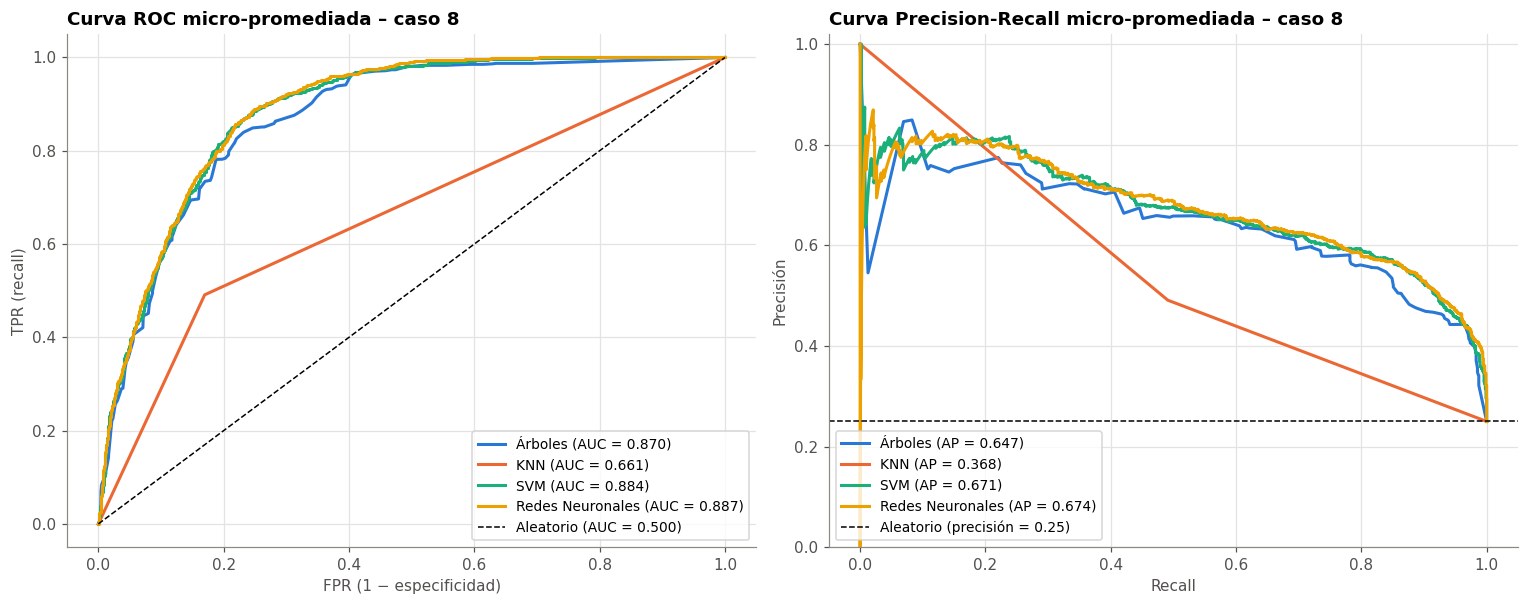

,AUC micro,AP micro,F1 macro,Probabilidades distintas
Árboles,0.870,0.647,0.5915,101
KNN,0.661,0.368,0.4425,2
SVM,0.884,0.671,0.5790,3590
Redes Neuronales,0.887,0.674,0.5871,3200


AUC ROC                                     AP                               
                     Nivel 1 Nivel 2 Nivel 3 Nivel 4  Macro Nivel 1 Nivel 2 Nivel 3 Nivel 4  Macro
Árboles                0.879   0.787   0.830   0.909  0.851   0.501   0.618   0.780   0.429  0.582
KNN                    0.661   0.577   0.646   0.734  0.654   0.206   0.412   0.569   0.167  0.338
SVM                    0.882   0.797   0.847   0.936  0.866   0.547   0.606   0.798   0.577  0.632
Redes Neuronales       0.898   0.810   0.845   0.946  0.875   0.551   0.636   0.798   0.558  0.636
Referencia aleatoria   0.500   0.500   0.500   0.500  0.500   0.120   0.366   0.466   0.048  0.250

In [67]:
# ============================================================
# 7.3 Curvas ROC y Precision-Recall del caso 8
# ============================================================
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score

CASO_CURVAS = 8


def binarizar(y, n_clases=len(CLASES)):
    """One-vs-Rest: matriz (registros x clases) con 1 en la columna de la clase real."""
    return np.eye(n_clases, dtype=int)[np.asarray(y)]


def curvas_roc_pr(caso=CASO_CURVAS):
    """Curvas ROC y Precision-Recall micro-promediadas de los 4 algoritmos en el caso.

    Micro-promedio: se aplanan las 4 columnas One-vs-Rest (etiquetas y probabilidades) y se
    tratan como un solo problema binario, con las mismas funciones del notebook 6-02
    (roc_curve, precision_recall_curve, auc y average_precision_score)."""
    Y = binarizar(casos[caso]["y_test"]).ravel()
    curvas = {}
    for alg in ALGORITMOS:
        P = RESULTADOS[(alg, caso)]["y_proba"]
        fpr, tpr, _ = roc_curve(Y, P.ravel())
        precision, recall, _ = precision_recall_curve(Y, P.ravel())
        curvas[alg] = {"fpr": fpr, "tpr": tpr, "precision": precision, "recall": recall,
                       "AUC": auc(fpr, tpr), "AP": average_precision_score(Y, P.ravel()),
                       "Probabilidades distintas": len(np.unique(P.round(6)))}
    return curvas


def graficar_roc_pr(curvas, caso=CASO_CURVAS):
    """Curva ROC (izquierda) y Precision-Recall (derecha) de los 4 algoritmos. Las líneas
    discontinuas son el clasificador aleatorio: la diagonal en ROC y 1/4 de precisión en PR
    (cada registro es positivo en 1 de las 4 columnas One-vs-Rest)."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.6))
    for i, alg in enumerate(ALGORITMOS):
        c = curvas[alg]
        ax1.plot(c["fpr"], c["tpr"], color=COLORES_SERIES[i], lw=2, label=f"{alg} (AUC = {c['AUC']:.3f})")
        ax2.plot(c["recall"], c["precision"], color=COLORES_SERIES[i], lw=2, label=f"{alg} (AP = {c['AP']:.3f})")
    ax1.plot([0, 1], [0, 1], "k--", lw=1, label="Aleatorio (AUC = 0.500)")
    ax2.axhline(1 / len(CLASES), color="k", ls="--", lw=1, label=f"Aleatorio (precisión = {1 / len(CLASES):.2f})")
    ax1.set_xlabel("FPR (1 − especificidad)")
    ax1.set_ylabel("TPR (recall)")
    ax1.set_title(f"Curva ROC micro-promediada – caso {caso}", loc="left")
    ax2.set_xlabel("Recall")
    ax2.set_ylabel("Precisión")
    ax2.set_ylim(0, 1.02)
    ax2.set_title(f"Curva Precision-Recall micro-promediada – caso {caso}", loc="left")
    for ax in (ax1, ax2):
        ax.legend(loc="lower left" if ax is ax2 else "lower right", fontsize=9)
    plt.tight_layout()
    plt.show()


def areas_por_clase(caso=CASO_CURVAS):
    """AUC ROC y AP de cada clase (One-vs-Rest) y su promedio macro. La fila de referencia es el
    clasificador aleatorio: AUC 0.5 y AP igual a la proporción de la clase en la prueba."""
    Y = binarizar(casos[caso]["y_test"])
    filas = {}
    for alg in ALGORITMOS:
        P = RESULTADOS[(alg, caso)]["y_proba"]
        fila = {}
        for i, clase in enumerate(CLASES):
            fpr, tpr, _ = roc_curve(Y[:, i], P[:, i])
            fila[("AUC ROC", clase)] = auc(fpr, tpr)
            fila[("AP", clase)] = average_precision_score(Y[:, i], P[:, i])
        for area in ("AUC ROC", "AP"):
            fila[(area, "Macro")] = np.mean([fila[(area, c)] for c in CLASES])
        filas[alg] = fila
    filas["Referencia aleatoria"] = {**{("AUC ROC", c): 0.5 for c in CLASES + ["Macro"]},
                                     **{("AP", c): Y[:, i].mean() for i, c in enumerate(CLASES)},
                                     ("AP", "Macro"): Y.mean(axis=0).mean()}
    tabla = pd.DataFrame(filas).T
    tabla.columns = pd.MultiIndex.from_tuples(tabla.columns)
    return tabla[[(a, c) for a in ("AUC ROC", "AP") for c in CLASES + ["Macro"]]].astype(float).round(3)


CURVAS_CASO8 = curvas_roc_pr()
graficar_roc_pr(CURVAS_CASO8)
display(pd.DataFrame.from_dict({alg: {"AUC micro": round(c["AUC"], 3), "AP micro": round(c["AP"], 3),
                                      "F1 macro": round(RESULTADOS[(alg, CASO_CURVAS)]["F1"], 4),
                                      "Probabilidades distintas": c["Probabilidades distintas"]}
                                for alg, c in CURVAS_CASO8.items()}, orient="index"))
AREAS_CASO8 = areas_por_clase()
display(AREAS_CASO8)

### 7.4 Costo de los errores y métrica priorizada
Matrices de confusión del caso 8, recall y precisión por clase, falsos negativos y falsos positivos de Nivel 1, y recall de Nivel 1 en los 8 casos. *Uso supuesto del modelo y métrica priorizada: documento, sección 5.4.*

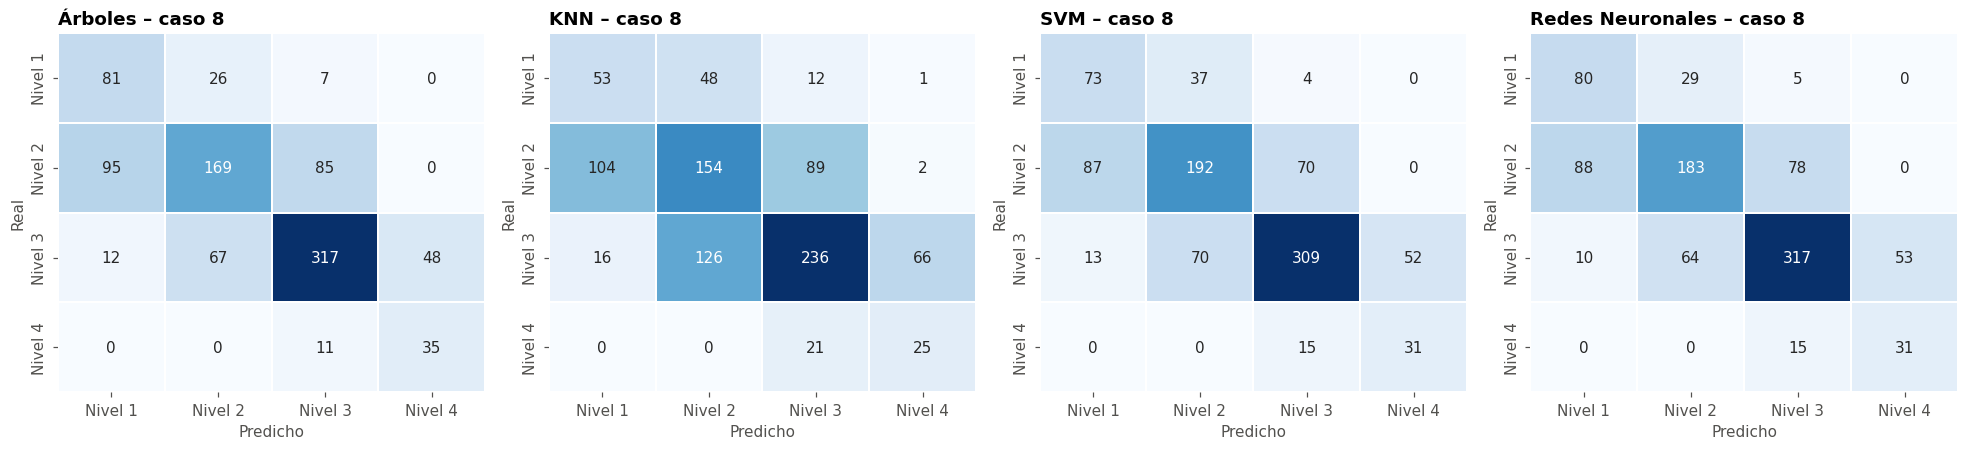

Recall                         Precisión                                    Nivel 1                     Errores                 
                 Nivel 1 Nivel 2 Nivel 3 Nivel 4   Nivel 1 Nivel 2 Nivel 3 Nivel 4 FN (no detectados) FP (falsas alarmas)   Total Saltan > 1 nivel
Árboles            0.711   0.484   0.714   0.761     0.431   0.645   0.755   0.422                 33                 107     351               19
KNN                0.465   0.441   0.532   0.543     0.306   0.470   0.659   0.266                 61                 120     485               31
SVM                0.640   0.550   0.696   0.674     0.422   0.642   0.776   0.373                 41                 100     348               17
Redes Neuronales   0.702   0.524   0.714   0.674     0.449   0.663   0.764   0.369                 34                  98     342               15

Recall de Nivel 1 en los 8 casos:


,Árboles,KNN,SVM,Redes Neuronales
1,0.526,0.728,0.719,0.833
2,0.702,0.482,0.693,0.693
3,0.596,0.754,0.693,0.544
4,0.711,0.474,0.658,0.649
5,0.526,0.623,0.711,0.781
6,0.702,0.465,0.561,0.658
7,0.596,0.544,0.693,0.728
8,0.711,0.465,0.640,0.702


In [68]:
# ============================================================
# 7.4 Costo de los errores en el dominio
# ============================================================
def errores_por_clase(caso=CASO_CURVAS):
    """Por algoritmo: recall y precisión de cada clase, estudiantes de Nivel 1 no detectados (FN)
    y falsas alarmas de Nivel 1 (FP), y errores que saltan más de un nivel."""
    y = casos[caso]["y_test"].to_numpy()
    filas = {}
    for alg in ALGORITMOS:
        y_pred = RESULTADOS[(alg, caso)]["y_pred"]
        recall = recall_score(y, y_pred, labels=range(len(CLASES)), average=None, zero_division=0)
        precision = precision_score(y, y_pred, labels=range(len(CLASES)), average=None, zero_division=0)
        fila = {**{("Recall", c): r for c, r in zip(CLASES, recall)},
                **{("Precisión", c): p for c, p in zip(CLASES, precision)}}
        fila[("Nivel 1", "FN (no detectados)")] = int(((y == 0) & (y_pred != 0)).sum())
        fila[("Nivel 1", "FP (falsas alarmas)")] = int(((y != 0) & (y_pred == 0)).sum())
        fila[("Errores", "Total")] = int((y_pred != y).sum())
        fila[("Errores", "Saltan > 1 nivel")] = int((np.abs(y_pred - y) > 1).sum())
        filas[alg] = fila
    tabla = pd.DataFrame.from_dict(filas, orient="index")   # conserva los conteos como enteros
    tabla.columns = pd.MultiIndex.from_tuples(tabla.columns)
    return tabla.round(3)


def recall_clase_por_caso(clase="Nivel 1"):
    """Recall de prueba de una clase en los 8 casos (filas) y los 4 algoritmos (columnas)."""
    i = CLASES.index(clase)
    return pd.DataFrame({alg: {k: recall_por_clase(alg, k)[i] for k in casos} for alg in ALGORITMOS}).round(3)


fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for alg, ax in zip(ALGORITMOS, axes):
    graficar_matriz_confusion(alg, CASO_CURVAS, ax=ax)
plt.tight_layout()
plt.show()

display(errores_por_clase())
print("Recall de Nivel 1 en los 8 casos:")
display(recall_clase_por_caso("Nivel 1"))

### 7.5 Tres datos de prueba nuevos: estudiantes hipotéticos
Nivel predicho por las 4 técnicas en los 8 casos para los 3 estudiantes de la sección 4.9. *Análisis: documento, sección 4.5.*

In [69]:
# ============================================================
# 7.5 Tres datos de prueba nuevos: estudiantes hipotéticos
# ============================================================
MODELOS_SUPERVISADOS = {"Árboles": MODELOS_ARBOL, "KNN": MODELOS_KNN, "SVM": MODELOS_SVM,
                        "Redes Neuronales": MODELOS_RED}


def predecir_hipoteticos(algoritmo, caso, modelo):
    """Predicción de los 3 estudiantes hipotéticos (sección 4.9) en la versión del caso: clase
    predicha y probabilidad de cada clase. No tienen clase real: son datos nuevos, como los
    "nuevos_datos" del notebook 5_02."""
    X_h = obtener_datos_hipoteticos(caso)
    y_pred, y_proba = predecir_con_probabilidades(modelo, X_h)
    tabla = pd.DataFrame(y_proba.round(3), columns=[f"P({c})" for c in CLASES], index=X_h.index)
    tabla.insert(0, "Predicho", [CLASES[p] for p in y_pred])
    tabla.insert(0, "Caso", caso)
    tabla.insert(0, "Técnica", algoritmo)
    return tabla


def resumen_hipoteticos(predicciones):
    """Nivel predicho por cada técnica (columnas) para cada perfil y caso (filas)."""
    tabla = predicciones.reset_index()
    tabla["Perfil"] = pd.Categorical(tabla["Perfil"], categories=list(ESTUDIANTES_HIPOTETICOS.index), ordered=True)
    return tabla.pivot(index=["Perfil", "Caso"], columns="Técnica", values="Predicho")[ALGORITMOS].sort_index()


PREDICCIONES_HIPOTETICOS = pd.concat([predecir_hipoteticos(alg, k, MODELOS_SUPERVISADOS[alg][k])
                                      for alg in ALGORITMOS for k in casos])
display(resumen_hipoteticos(PREDICCIONES_HIPOTETICOS))
print("Probabilidades en el caso 8:")
display(PREDICCIONES_HIPOTETICOS[PREDICCIONES_HIPOTETICOS["Caso"] == CASO_CURVAS])

Técnica            Árboles      KNN      SVM Redes Neuronales
Perfil       Caso                                            
Perfil bajo  1     Nivel 1  Nivel 1  Nivel 1          Nivel 1
             2     Nivel 1  Nivel 1  Nivel 1          Nivel 1
             3     Nivel 1  Nivel 1  Nivel 1          Nivel 1
             4     Nivel 1  Nivel 1  Nivel 1          Nivel 1
             5     Nivel 1  Nivel 1  Nivel 1          Nivel 1
             6     Nivel 1  Nivel 1  Nivel 1          Nivel 1
             7     Nivel 1  Nivel 1  Nivel 1          Nivel 1
             8     Nivel 1  Nivel 1  Nivel 1          Nivel 1
Perfil medio 1     Nivel 3  Nivel 3  Nivel 3          Nivel 3
             2     Nivel 3  Nivel 2  Nivel 3          Nivel 3
             3     Nivel 3  Nivel 3  Nivel 3          Nivel 3
             4     Nivel 3  Nivel 2  Nivel 3          Nivel 3
             5     Nivel 3  Nivel 3  Nivel 3          Nivel 3
             6     Nivel 3  Nivel 2  Nivel 3          Nivel 3
             7     Nivel 3  Nivel 3  Nivel 3          Nivel 3
             8     Nivel 3  Nivel 2  Nivel 3          Nivel 3
Perfil alto  1     Nivel 4  Nivel 4  Nivel 4          Nivel 3
             2     Nivel 4  Nivel 4  Nivel 4          Nivel 4
             3     Nivel 4  Nivel 4  Nivel 4          Nivel 3
             4     Nivel 4  Nivel 4  Nivel 4          Nivel 4
             5     Nivel 4  Nivel 4  Nivel 4          Nivel 4
             6     Nivel 4  Nivel 4  Nivel 4          Nivel 4
             7     Nivel 4  Nivel 4  Nivel 4          Nivel 4
             8     Nivel 4  Nivel 4  Nivel 4          Nivel 4

Probabilidades en el caso 8:


,Técnica,Caso,Predicho,P(Nivel 1),P(Nivel 2),P(Nivel 3),P(Nivel 4)
Perfil,,,,,,,
Perfil bajo,Árboles,8,Nivel 1,0.881,0.113,0.005,0.000
Perfil medio,Árboles,8,Nivel 3,0.020,0.458,0.522,0.000
Perfil alto,Árboles,8,Nivel 4,0.001,0.000,0.064,0.936
Perfil bajo,KNN,8,Nivel 1,1.000,0.000,0.000,0.000
Perfil medio,KNN,8,Nivel 2,0.000,1.000,0.000,0.000
Perfil alto,KNN,8,Nivel 4,0.000,0.000,0.000,1.000
Perfil bajo,SVM,8,Nivel 1,0.682,0.309,0.010,0.000
Perfil medio,SVM,8,Nivel 3,0.039,0.395,0.557,0.009
Perfil alto,SVM,8,Nivel 4,0.000,0.000,0.068,0.932


### 7.6 Conclusiones del módulo supervisado
*Documento, Conclusiones.*

# Módulo 2 – Aprendizaje no supervisado

## 8. K-Means y DBSCAN
K-Means y DBSCAN sobre las 8 versiones de la Figura 2, como en los notebooks de clase `6-03` y `6-04`. La etiqueta solo se usa en la validación externa (8.7). *Análisis: documento, secciones 6 a 10.*

### 8.0 Datos de la Figura 2 y correspondencia con la Figura 1
Cada versión son los registros de entrenamiento del caso correspondiente de la Figura 1, sin la etiqueta y con el mismo CC, escalado y outliers. *Documento, sección 6.*

In [70]:
# ============================================================
# 8.0 Datos de la Figura 2 (sin la variable objetivo)
# ============================================================
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

# X: registros de entrenamiento del caso (mismo CC, escalado y outliers); y_ext: SOLO validación externa
DATOS_NS = {k: obtener_datos_no_supervisado(k) for k in casos}
COLUMNAS_NUMERICAS_NS = list(VARIABLES_NUMERICAS)   # 5 numéricas (sin escalar en los casos 1–4)


def tabla_figura2(datos=DATOS_NS):
    """Figura 2 con la correspondencia de cada versión con su caso supervisado: registros,
    columnas, distribución de la etiqueta (que se descartó) y % de outliers (IQR).
    Los casos k y k+4 comparten registros, así que el % de outliers del caso k+4 se mide
    sobre su par sin escalar (los límites IQR están en la escala original)."""
    filas = {}
    for k, (X, y_ext) in datos.items():
        c = casos[k]
        X_original = datos[k - 4][0] if k > 4 else X
        distribucion = y_ext.value_counts(normalize=True).reindex(CLASES).mul(100).round(1)
        filas[k] = {"Normalización": c["normalizacion"], "Outliers": c["outliers"],
                    "Balanceo": c["balanceo"], "Caso supervisado": k,
                    "Mismos registros que": k + 4 if k <= 4 else k - 4,
                    "Registros": len(X), "Columnas": X.shape[1],
                    "% outliers (IQR)": round(detectar_outliers(X_original, LIMITES_IQR).mean() * 100, 1),
                    **{f"% {clase}": distribucion[clase] for clase in CLASES}}
    tabla = pd.DataFrame(filas).T
    tabla.index.name = "Caso"
    return tabla


def participacion_varianza(X, columnas=COLUMNAS_NUMERICAS_NS):
    """% de la varianza total de X (suma de varianzas por columna) que aportan las columnas
    indicadas. Con distancia euclidiana, esa proporción es el peso de esas columnas en la inercia."""
    varianzas = X.var()
    return varianzas[columnas].sum() / varianzas.sum() * 100


display(tabla_figura2())
for k in (1, 5):
    print(f"Caso {k}: las 5 numéricas aportan el {participacion_varianza(DATOS_NS[k][0]):.1f} % "
          f"de la varianza total de las 65 columnas")

,Normalización,Outliers,Balanceo,Caso supervisado,Mismos registros que,Registros,Columnas,% outliers (IQR),% Nivel 1,% Nivel 2,% Nivel 3,% Nivel 4
Caso,,,,,,,,,,,,
1,CC(SI) y ED(NO),NO,NO,1,5,2050,65,0.0,10.0,10.0,70.0,10.0
2,CC(SI) y ED(NO),NO,SI,2,6,8208,65,0.0,25.0,25.0,25.0,25.0
3,CC(SI) y ED(NO),SI,NO,3,7,2170,65,5.0,10.0,10.0,70.0,10.0
4,CC(SI) y ED(NO),SI,SI,4,8,8296,65,5.0,25.0,25.0,25.0,25.0
5,CC(SI) y ED(SI),NO,NO,5,1,2050,65,0.0,10.0,10.0,70.0,10.0
6,CC(SI) y ED(SI),NO,SI,6,2,8208,65,0.0,25.0,25.0,25.0,25.0
7,CC(SI) y ED(SI),SI,NO,7,3,2170,65,5.0,10.0,10.0,70.0,10.0
8,CC(SI) y ED(SI),SI,SI,8,4,8296,65,5.0,25.0,25.0,25.0,25.0


Caso 1: las 5 numéricas aportan el 97.1 % de la varianza total de las 65 columnas
Caso 5: las 5 numéricas aportan el 36.5 % de la varianza total de las 65 columnas


### 8.1 K-Means
#### 8.1.1 Número de clusters: método del codo y silhouette
K de 2 a 10 con `init="k-means++"`, `n_init=10` y `random_state=79`. El codo se lee con el punto de la curva más alejado de la recta entre sus extremos, y K se elige con el silhouette máximo. *Documento, sección 7.*

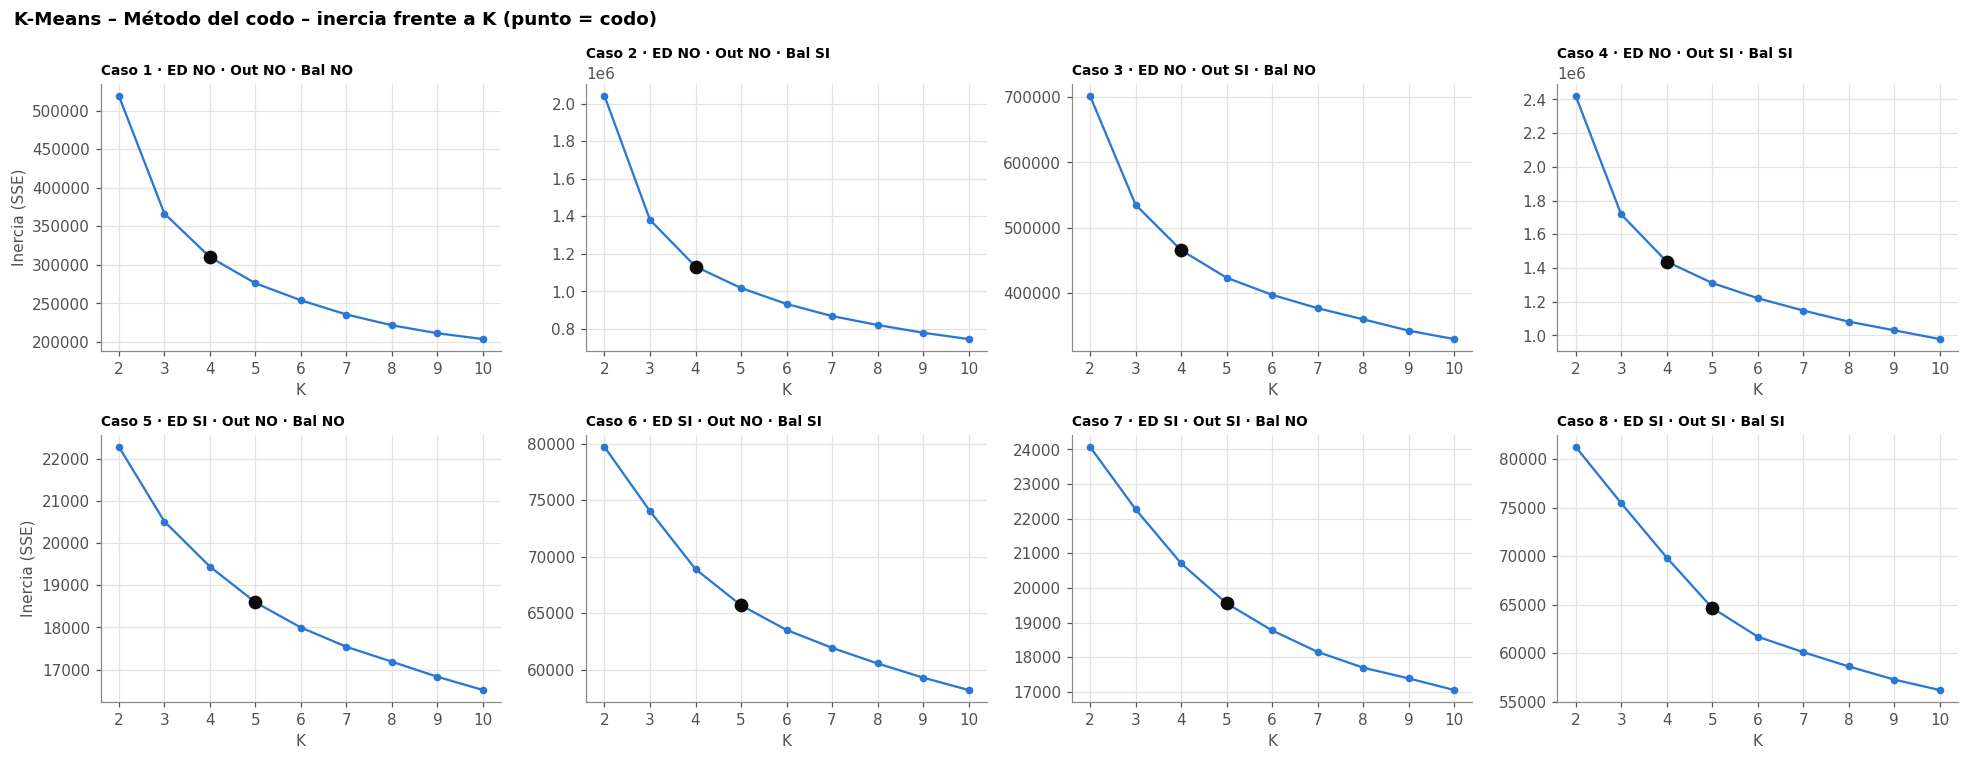

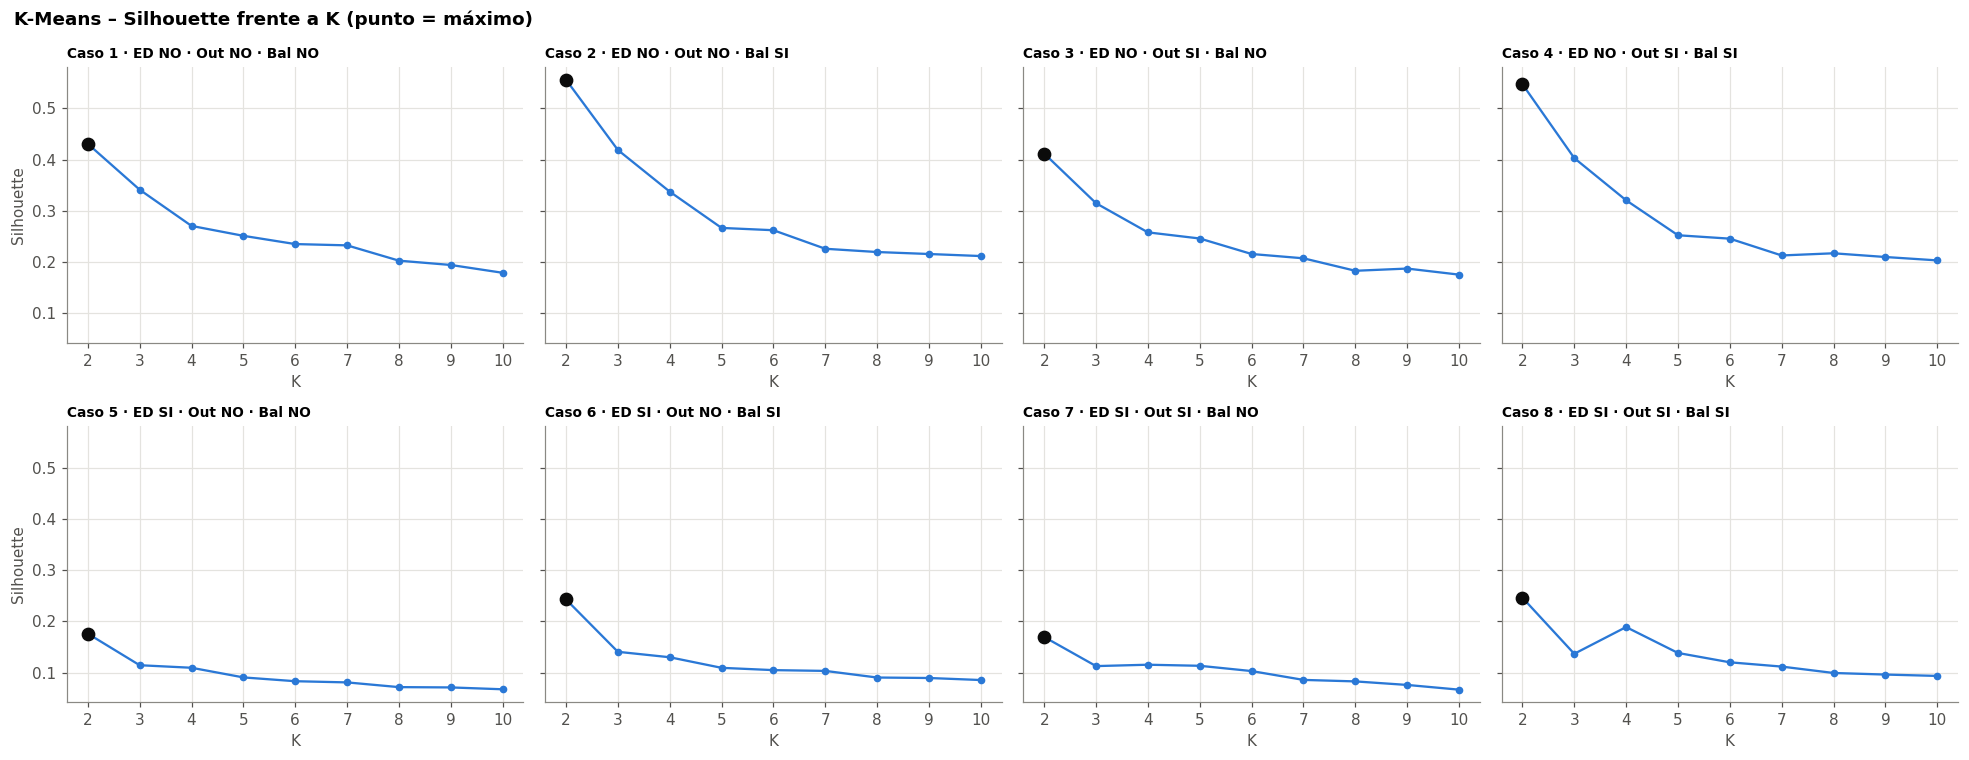

,K codo,K silhouette,K elegido,Silhouette K=2,Silhouette K=3,Silhouette K=4,Silhouette en K codo
Caso,,,,,,,
1,4.0,2.0,2.0,0.4308,0.3412,0.2705,0.2705
2,4.0,2.0,2.0,0.5559,0.4188,0.3374,0.3374
3,4.0,2.0,2.0,0.4118,0.3148,0.2579,0.2579
4,4.0,2.0,2.0,0.5473,0.4029,0.3206,0.3206
5,5.0,2.0,2.0,0.1760,0.1143,0.1093,0.0905
6,5.0,2.0,2.0,0.2427,0.1405,0.1298,0.1092
7,5.0,2.0,2.0,0.1694,0.1126,0.1153,0.1132
8,5.0,2.0,2.0,0.2462,0.1366,0.1888,0.1382


In [71]:
# ============================================================
# 8.1 K-Means: K de 2 a 10 con el método del codo y el silhouette
# ============================================================
RANGO_K = list(range(2, 11))
N_INIT_KMEANS = 10


def curva_kmeans(X, rango=RANGO_K):
    """Entrena K-Means (k-means++, n_init=N_INIT_KMEANS, SEMILLA) para cada K del rango y
    retorna la inercia (SSE) y el silhouette de cada uno. Es el procedimiento del notebook 6-03."""
    filas = []
    for K in rango:
        km = KMeans(n_clusters=K, init="k-means++", n_init=N_INIT_KMEANS, random_state=SEMILLA).fit(X)
        filas.append({"K": K, "Inercia": km.inertia_,
                      "Silhouette": silhouette_score(X, km.labels_, random_state=SEMILLA)})
    return pd.DataFrame(filas)


def indice_codo(valores):
    """Posición del codo de una curva: el punto más alejado de la recta que une sus extremos
    (las dos escalas se normalizan a [0, 1]). Lo usamos para leer el codo de la inercia y de
    la k-distancia con un criterio fijo, en lugar de a ojo."""
    y = np.asarray(valores, dtype=float)
    x = np.linspace(0, 1, len(y))
    y = (y - y.min()) / (y.max() - y.min())
    recta = y[0] + (y[-1] - y[0]) * x
    return int(np.argmax(np.abs(y - recta)))


CURVAS_KMEANS = {k: curva_kmeans(DATOS_NS[k][0]) for k in casos}
K_CODO = {k: int(curva["K"].iloc[indice_codo(curva["Inercia"])]) for k, curva in CURVAS_KMEANS.items()}
K_SILHOUETTE = {k: int(curva.loc[curva["Silhouette"].idxmax(), "K"]) for k, curva in CURVAS_KMEANS.items()}
K_OPTIMO = dict(K_SILHOUETTE)   # criterio de decisión: máximo silhouette (ver la justificación)


def graficar_curvas_kmeans(metrica, curvas=CURVAS_KMEANS):
    """Inercia (codo) o silhouette frente a K en los 8 casos. Marca el K del codo (inercia)
    o el K de máximo silhouette, según la métrica."""
    fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey=(metrica == "Silhouette"))
    for ax, k in zip(axes.ravel(), casos):
        curva = curvas[k]
        ax.plot(curva["K"], curva[metrica], "o-", color=COLOR_PRINCIPAL, markersize=4)
        K_marcado = K_CODO[k] if metrica == "Inercia" else K_SILHOUETTE[k]
        ax.plot(K_marcado, curva.set_index("K").loc[K_marcado, metrica], "o", color="#0b0b0b", markersize=8)
        c = casos[k]
        ax.set_title(f"Caso {k} · ED {c['normalizacion'][-3:-1]} · Out {c['outliers']} · Bal {c['balanceo']}",
                     loc="left", fontsize=9)
        ax.set_xlabel("K")
        ax.set_xticks(RANGO_K)
    for ax in axes[:, 0]:
        ax.set_ylabel("Inercia (SSE)" if metrica == "Inercia" else "Silhouette")
    titulo = ("Método del codo – inercia frente a K (punto = codo)" if metrica == "Inercia"
              else "Silhouette frente a K (punto = máximo)")
    fig.suptitle(f"K-Means – {titulo}", x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


graficar_curvas_kmeans("Inercia")
graficar_curvas_kmeans("Silhouette")

ELECCION_K = pd.DataFrame({
    k: {"K codo": K_CODO[k], "K silhouette": K_SILHOUETTE[k], "K elegido": K_OPTIMO[k],
        "Silhouette K=2": round(CURVAS_KMEANS[k].set_index("K").loc[2, "Silhouette"], 4),
        "Silhouette K=3": round(CURVAS_KMEANS[k].set_index("K").loc[3, "Silhouette"], 4),
        "Silhouette K=4": round(CURVAS_KMEANS[k].set_index("K").loc[4, "Silhouette"], 4),
        "Silhouette en K codo": round(CURVAS_KMEANS[k].set_index("K").loc[K_CODO[k], "Silhouette"], 4)}
    for k in casos}).T
ELECCION_K.index.name = "Caso"
display(ELECCION_K)

#### 8.1.2 Modelo final y tamaño de los clusters
K-Means con el K elegido. Los clusters se renumeran: C0 es el de menor puntaje medio y C1 el de mayor.

In [72]:
# ============================================================
# 8.1.2 Modelo final de K-Means por caso y tamaño de los clusters
# ============================================================
PUNTAJES_NS = [c for c in COLUMNAS_NUMERICAS_NS if c.startswith("PUNT_")]   # las 4 áreas distintas de matemáticas


def orden_clusters_kmeans(k, etiquetas):
    """Renumera los clusters para que sean comparables entre casos: C0 es el de menor puntaje
    medio en las otras 4 áreas (escala original) y C1 el de mayor. K-Means numera sus
    clusters de forma arbitraria; la renumeración no cambia la inercia ni el silhouette."""
    X_original = DATOS_NS[k - 4][0] if k > 4 else DATOS_NS[k][0]
    medias = X_original[PUNTAJES_NS].mean(axis=1).groupby(etiquetas).mean().sort_values()
    return {original: nuevo for nuevo, original in enumerate(medias.index)}


def predecir_kmeans(k, X):
    """Cluster de K-Means (ya renumerado) para registros nuevos del caso k."""
    return np.array([MAPA_KMEANS[k][c] for c in MODELOS_KMEANS[k].predict(X)])


MODELOS_KMEANS, MAPA_KMEANS, ETIQUETAS_KMEANS = {}, {}, {}
for k in casos:
    X_ns, _ = DATOS_NS[k]
    km_k = KMeans(n_clusters=K_OPTIMO[k], init="k-means++", n_init=N_INIT_KMEANS,
                  random_state=SEMILLA).fit(X_ns)
    MODELOS_KMEANS[k] = km_k
    MAPA_KMEANS[k] = orden_clusters_kmeans(k, km_k.labels_)
    ETIQUETAS_KMEANS[k] = np.array([MAPA_KMEANS[k][c] for c in km_k.labels_])
    registrar_clustering("K-Means", k, X_ns, ETIQUETAS_KMEANS[k], km_k,
                         {"n_clusters": K_OPTIMO[k], "init": "k-means++", "n_init": N_INIT_KMEANS})


def nombre_cluster(etiqueta):
    """Nombre de un cluster para tablas y gráficas: C0, C1… o Ruido (-1)."""
    return "Ruido" if etiqueta == -1 else f"C{etiqueta}"


def tamanos_clusters(etiquetas):
    """Texto con el tamaño y el % de cada cluster (y del ruido, si lo hay)."""
    conteo = pd.Series(etiquetas).value_counts().sort_index()
    total = len(etiquetas)
    return " · ".join(f"{'Ruido' if c == -1 else f'C{c}'}: {n} ({n / total:.0%})" for c, n in conteo.items())


TAMANOS_KMEANS = pd.DataFrame({k: {"K": K_OPTIMO[k], "Registros": len(ETIQUETAS_KMEANS[k]),
                                   "Tamaño de cada cluster": tamanos_clusters(ETIQUETAS_KMEANS[k])}
                               for k in casos}).T
TAMANOS_KMEANS.index.name = "Caso"
display(TAMANOS_KMEANS)

K-Means | caso 1 | clusters: 2 | ruido: 0 | inercia: 519267.70 | silhouette: 0.4308
K-Means | caso 2 | clusters: 2 | ruido: 0 | inercia: 2041823.27 | silhouette: 0.5559
K-Means | caso 3 | clusters: 2 | ruido: 0 | inercia: 701971.72 | silhouette: 0.4118
K-Means | caso 4 | clusters: 2 | ruido: 0 | inercia: 2421023.24 | silhouette: 0.5473
K-Means | caso 5 | clusters: 2 | ruido: 0 | inercia: 22278.69 | silhouette: 0.1760
K-Means | caso 6 | clusters: 2 | ruido: 0 | inercia: 79717.65 | silhouette: 0.2427
K-Means | caso 7 | clusters: 2 | ruido: 0 | inercia: 24075.87 | silhouette: 0.1694
K-Means | caso 8 | clusters: 2 | ruido: 0 | inercia: 81264.06 | silhouette: 0.2462


,K,Registros,Tamaño de cada cluster
Caso,,,
1,2,2050,C0: 989 (48%) · C1: 1061 (52%)
2,2,8208,C0: 4816 (59%) · C1: 3392 (41%)
3,2,2170,C0: 1053 (49%) · C1: 1117 (51%)
4,2,8296,C0: 4898 (59%) · C1: 3398 (41%)
5,2,2050,C0: 990 (48%) · C1: 1060 (52%)
6,2,8208,C0: 4832 (59%) · C1: 3376 (41%)
7,2,2170,C0: 1111 (51%) · C1: 1059 (49%)
8,2,8296,C0: 4930 (59%) · C1: 3366 (41%)


#### 8.1.3 Efecto del escalado y de los outliers
Compara pares de casos que solo difieren en un factor.

In [73]:
# ============================================================
# 8.1.3 Efecto del escalado y de los outliers en K-Means
# ============================================================
def mascara_outliers_ns(k, datos=DATOS_NS):
    """Filas atípicas (IQR) del caso k. En los casos 5–8 se toma la máscara de su par sin
    escalar (mismos registros), porque los límites IQR están en la escala original."""
    X_original = datos[k - 4][0] if k > 4 else datos[k][0]
    return detectar_outliers(X_original, LIMITES_IQR).to_numpy()


def efecto_factor_kmeans(pares, nombre_sin, nombre_con):
    """Compara el silhouette de K-Means entre pares de casos que solo difieren en un factor."""
    filas = []
    for sin, con in pares:
        s_sin = RESULTADOS_CLUSTERING[("K-Means", sin)]["Silhouette"]
        s_con = RESULTADOS_CLUSTERING[("K-Means", con)]["Silhouette"]
        filas.append({"Par": f"{sin} → {con}", f"Silhouette {nombre_sin}": round(s_sin, 4),
                      f"Silhouette {nombre_con}": round(s_con, 4), "Diferencia": round(s_con - s_sin, 4)})
    return pd.DataFrame(filas).set_index("Par")


def outliers_por_cluster(casos_con_outliers=(3, 4, 7, 8)):
    """Cómo se reparten los outliers entre los clusters de K-Means: % de outliers dentro de
    cada cluster. Si los outliers formaran un grupo propio, un cluster tendría casi el 100 %."""
    filas = {}
    for k in casos_con_outliers:
        etiquetas = ETIQUETAS_KMEANS[k]
        mascara = mascara_outliers_ns(k)
        filas[k] = {f"C{c}: % outliers": round(mascara[etiquetas == c].mean() * 100, 1)
                    for c in range(K_OPTIMO[k])}
        filas[k]["Outliers en el caso"] = int(mascara.sum())
    return pd.DataFrame(filas).T


print("Efecto del escalado (sin ED → con ED):")
display(efecto_factor_kmeans([(1, 5), (2, 6), (3, 7), (4, 8)], "sin ED", "con ED"))
print("Efecto de los outliers (sin outliers → con outliers):")
display(efecto_factor_kmeans([(1, 3), (2, 4), (5, 7), (6, 8)], "sin outliers", "con outliers"))
print("Reparto de los outliers entre los clusters de K-Means:")
display(outliers_por_cluster())


def coincidencia_escalado():
    """% de registros que quedan en el mismo cluster en los casos k y k+4, que tienen los
    mismos registros y solo difieren en el escalado."""
    return pd.Series({f"{k} y {k + 4}": round((ETIQUETAS_KMEANS[k] == ETIQUETAS_KMEANS[k + 4]).mean() * 100, 1)
                      for k in (1, 2, 3, 4)}, name="% en el mismo cluster").to_frame()


print("Coincidencia de los clusters con y sin escalado (mismos registros):")
display(coincidencia_escalado())

Efecto del escalado (sin ED → con ED):


,Silhouette sin ED,Silhouette con ED,Diferencia
Par,,,
1 → 5,0.4308,0.1760,-0.2548
2 → 6,0.5559,0.2427,-0.3132
3 → 7,0.4118,0.1694,-0.2424
4 → 8,0.5473,0.2462,-0.3011


Efecto de los outliers (sin outliers → con outliers):


,Silhouette sin outliers,Silhouette con outliers,Diferencia
Par,,,
1 → 3,0.4308,0.4118,-0.0190
2 → 4,0.5559,0.5473,-0.0086
5 → 7,0.1760,0.1694,-0.0065
6 → 8,0.2427,0.2462,0.0035


Reparto de los outliers entre los clusters de K-Means:


,C0: % outliers,C1: % outliers,Outliers en el caso
3,5.9,4.2,109.0
4,5.6,4.2,415.0
7,6.0,4.0,109.0
8,5.7,4.0,415.0


Coincidencia de los clusters con y sin escalado (mismos registros):


,% en el mismo cluster
1 y 5,91.9
2 y 6,94.7
3 y 7,89.5
4 y 8,94.5


### 8.2 DBSCAN
#### 8.2.1 MinPts y ε
MinPts = 2 × 65 = 130 y ε en el codo del gráfico de k-distancia con k = MinPts. *Documento, sección 8.*

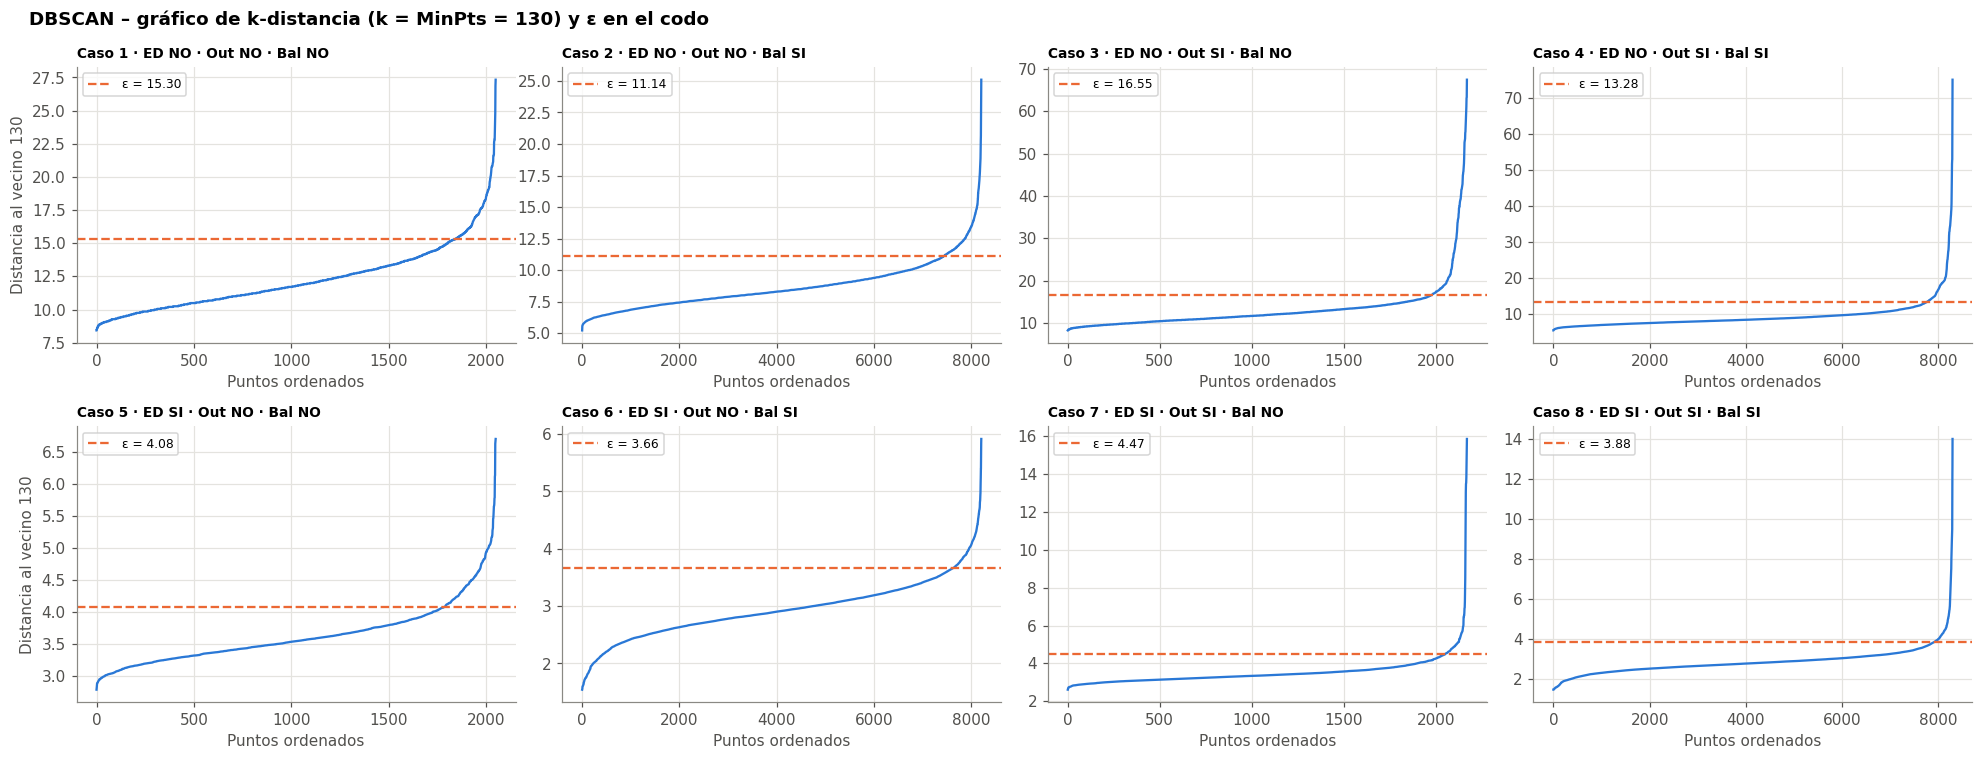

In [74]:
# ============================================================
# 8.2 DBSCAN: MinPts con la regla del curso y ε con el gráfico de k-distancia
# ============================================================
N_CARACTERISTICAS = DATOS_NS[1][0].shape[1]          # 65 columnas
MINPTS_REGLA = 2 * N_CARACTERISTICAS                 # regla del enunciado y de la diapositiva 6-03: 130
MINPTS_REGLA_2 = N_CARACTERISTICAS + 1               # segunda regla de la diapositiva 6-03: 66


def k_distancias(X, min_pts):
    """Distancia de cada punto a su min_pts-ésimo vecino más cercano, ordenada de menor a mayor
    (el propio punto cuenta como vecino, igual que en DBSCAN). Procedimiento del notebook 6-04."""
    distancias, _ = NearestNeighbors(n_neighbors=min_pts).fit(X).kneighbors(X)
    return np.sort(distancias[:, -1])


def eps_codo(X, min_pts):
    """ε en el codo del gráfico de k-distancia (k = min_pts). Retorna (ε, curva de k-distancias)."""
    curva = k_distancias(X, min_pts)
    return float(curva[indice_codo(curva)]), curva


KDIST = {}
EPS_CODO = {}
for k in casos:
    EPS_CODO[k], KDIST[k] = eps_codo(DATOS_NS[k][0], MINPTS_REGLA)


def graficar_kdistancia(curvas=KDIST, eps=EPS_CODO, min_pts=MINPTS_REGLA):
    """Gráfico de k-distancia de los 8 casos con el ε elegido en el codo (línea discontinua)."""
    fig, axes = plt.subplots(2, 4, figsize=(18, 7))
    for ax, k in zip(axes.ravel(), casos):
        ax.plot(curvas[k], color=COLOR_PRINCIPAL)
        ax.axhline(eps[k], ls="--", color=COLORES_SERIES[1], label=f"ε = {eps[k]:.2f}")
        c = casos[k]
        ax.set_title(f"Caso {k} · ED {c['normalizacion'][-3:-1]} · Out {c['outliers']} · Bal {c['balanceo']}",
                     loc="left", fontsize=9)
        ax.set_xlabel("Puntos ordenados")
        ax.legend(fontsize=8, loc="upper left")
    for ax in axes[:, 0]:
        ax.set_ylabel(f"Distancia al vecino {min_pts}")
    fig.suptitle(f"DBSCAN – gráfico de k-distancia (k = MinPts = {min_pts}) y ε en el codo",
                 x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


graficar_kdistancia()

#### 8.2.2 DBSCAN con la regla del enunciado (Figura 3)
DBSCAN con MinPts = 130 y el ε del codo y, como contraste, con la segunda regla de la diapositiva 6-03 (MinPts = 66).

In [75]:
# ============================================================
# 8.2.2 DBSCAN con la regla del enunciado (Figura 3)
# ============================================================
def resumen_dbscan(etiquetas):
    """Número de clusters (sin ruido) y % de ruido de un resultado de DBSCAN."""
    etiquetas = np.asarray(etiquetas)
    return len(set(etiquetas[etiquetas != -1])), (etiquetas == -1).mean() * 100


MODELOS_DBSCAN = {}
for k in casos:
    X_ns, _ = DATOS_NS[k]
    db_k = DBSCAN(eps=EPS_CODO[k], min_samples=MINPTS_REGLA).fit(X_ns)
    MODELOS_DBSCAN[k] = db_k
    registrar_clustering("DBSCAN", k, X_ns, db_k.labels_, db_k,
                         {"eps": round(EPS_CODO[k], 2), "min_samples": MINPTS_REGLA})

# Segunda regla de la diapositiva 6-03 (MinPts = características + 1), con su propio ε del codo
filas_reglas = {}
for k in casos:
    X_ns, _ = DATOS_NS[k]
    eps_66, _ = eps_codo(X_ns, MINPTS_REGLA_2)
    etiquetas_66 = DBSCAN(eps=eps_66, min_samples=MINPTS_REGLA_2).fit(X_ns).labels_
    n_130, r_130 = resumen_dbscan(MODELOS_DBSCAN[k].labels_)
    n_66, r_66 = resumen_dbscan(etiquetas_66)
    filas_reglas[k] = {f"ε (MinPts={MINPTS_REGLA})": round(EPS_CODO[k], 2), f"Clusters ({MINPTS_REGLA})": n_130,
                       f"% ruido ({MINPTS_REGLA})": round(r_130, 1),
                       f"ε (MinPts={MINPTS_REGLA_2})": round(eps_66, 2), f"Clusters ({MINPTS_REGLA_2})": n_66,
                       f"% ruido ({MINPTS_REGLA_2})": round(r_66, 1)}
REGLAS_DBSCAN = pd.DataFrame(filas_reglas).T
REGLAS_DBSCAN.index.name = "Caso"
display(REGLAS_DBSCAN)

DBSCAN | caso 1 | clusters: 1 | ruido: 3 | inercia: nan | silhouette: nan
DBSCAN | caso 2 | clusters: 1 | ruido: 47 | inercia: nan | silhouette: nan
DBSCAN | caso 3 | clusters: 1 | ruido: 72 | inercia: nan | silhouette: nan
DBSCAN | caso 4 | clusters: 1 | ruido: 175 | inercia: nan | silhouette: nan
DBSCAN | caso 5 | clusters: 1 | ruido: 15 | inercia: nan | silhouette: nan
DBSCAN | caso 6 | clusters: 1 | ruido: 30 | inercia: nan | silhouette: nan
DBSCAN | caso 7 | clusters: 1 | ruido: 24 | inercia: nan | silhouette: nan
DBSCAN | caso 8 | clusters: 1 | ruido: 85 | inercia: nan | silhouette: nan


,ε (MinPts=130),Clusters (130),% ruido (130),ε (MinPts=66),Clusters (66),% ruido (66)
Caso,,,,,,
1,15.30,1.0,0.1,13.11,1.0,0.6
2,11.14,1.0,0.6,9.85,1.0,0.9
3,16.55,1.0,3.3,15.17,1.0,3.5
4,13.28,1.0,2.1,13.00,1.0,1.5
5,4.08,1.0,0.7,3.86,1.0,0.9
6,3.66,1.0,0.4,3.47,1.0,0.5
7,4.47,1.0,1.1,4.29,1.0,1.2
8,3.88,1.0,1.0,3.68,1.0,1.0


#### 8.2.3 Sensibilidad a ε y prueba complementaria
Ruido y número de clusters al reducir ε. La prueba complementaria busca el ε más cercano al codo que separa al menos 2 clusters (bajando MinPts a 66 y a 10 si hace falta); se reporta aparte y no reemplaza la regla.

In [76]:
# ============================================================
# 8.2.3 Sensibilidad a ε y prueba complementaria (ε por debajo del codo)
# ============================================================
FRACCIONES_EPS = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]       # ε = fracción × ε del codo


def sensibilidad_eps(fracciones=FRACCIONES_EPS, min_pts=MINPTS_REGLA):
    """Número de clusters y % de ruido de DBSCAN al reducir ε desde el codo (MinPts fijo)."""
    filas = {}
    for k in casos:
        X_ns, _ = DATOS_NS[k]
        for f in fracciones:
            n, r = resumen_dbscan(DBSCAN(eps=EPS_CODO[k] * f, min_samples=min_pts).fit(X_ns).labels_)
            filas[(k, f"{f:.0%} del codo")] = f"{n} cl · {r:.0f} % ruido"
    tabla = pd.Series(filas).unstack()
    tabla.index.name = "Caso"
    return tabla[[f"{f:.0%} del codo" for f in fracciones]]


SENSIBILIDAD_DBSCAN = sensibilidad_eps()
display(SENSIBILIDAD_DBSCAN)

# Prueba complementaria: el ε más cercano al codo que separa al menos 2 clusters.
# MinPts baja por las reglas de la diapositiva 6-03: 130 (2 × características) → 66 (características + 1)
# → 10 (reducido "si los datos contienen mucho ruido o se desea detectar grupos más pequeños").
ESCALERA_MINPTS = [MINPTS_REGLA, MINPTS_REGLA_2, 10]
PASO_EPS, FRACCION_MINIMA = 0.02, 0.40


def dbscan_complementario(X, escalera=ESCALERA_MINPTS):
    """Busca la configuración más cercana a la regla que produce al menos 2 clusters: para cada
    MinPts de la escalera, reduce ε desde el codo en pasos de 2 % hasta el 40 % del codo y se
    queda con el primero que separa 2 o más clusters. Retorna un diccionario con la configuración."""
    for min_pts in escalera:
        eps_0, _ = eps_codo(X, min_pts)
        for f in np.arange(1.0, FRACCION_MINIMA - 1e-9, -PASO_EPS):
            modelo = DBSCAN(eps=eps_0 * f, min_samples=min_pts).fit(X)
            n, r = resumen_dbscan(modelo.labels_)
            if n >= 2:
                etiquetas = modelo.labels_
                sil = silhouette_score(np.asarray(X)[etiquetas != -1], etiquetas[etiquetas != -1],
                                       random_state=SEMILLA)
                return {"MinPts": min_pts, "% del codo": round(f * 100), "eps": eps_0 * f, "Clusters": n,
                        "% ruido": r, "Silhouette": sil, "modelo": modelo}
    return None


DBSCAN_COMPLEMENTARIO = {k: dbscan_complementario(DATOS_NS[k][0]) for k in casos}
TABLA_DBSCAN_COMPLEMENTARIO = pd.DataFrame({
    k: {"MinPts": d["MinPts"], "% del codo": d["% del codo"], "ε": round(d["eps"], 2),
        "Clusters": d["Clusters"], "% ruido": round(d["% ruido"], 1), "Silhouette (sin ruido)": round(d["Silhouette"], 4),
        "Tamaño de cada cluster": tamanos_clusters(d["modelo"].labels_)}
    for k, d in DBSCAN_COMPLEMENTARIO.items() if d is not None}).T
TABLA_DBSCAN_COMPLEMENTARIO.index.name = "Caso"
display(TABLA_DBSCAN_COMPLEMENTARIO)


def mascara_sinteticos(k):
    """Registros sintéticos de SMOTENC en un caso balanceado. SMOTENC conserva los registros
    reales al inicio y agrega los sintéticos al final, así que son las filas posteriores al
    número de registros reales (entrenamiento base menos los outliers eliminados, si aplica)."""
    reales = len(X_train_base) - casos[k]["reporte"].get("Filas eliminadas (outliers)", 0)
    return np.arange(len(DATOS_NS[k][0])) >= reales


def sinteticos_por_cluster(casos_balanceados=(2, 4, 6, 8)):
    """% de registros sintéticos en cada cluster de la prueba complementaria de DBSCAN y de K-Means."""
    filas = {}
    for k in casos_balanceados:
        sint = mascara_sinteticos(k)
        etiquetas_db = DBSCAN_COMPLEMENTARIO[k]["modelo"].labels_
        fila = {"% sintéticos en el caso": round(sint.mean() * 100, 1)}
        fila.update({f"DBSCAN {nombre_cluster(c)}": round(sint[etiquetas_db == c].mean() * 100, 1)
                     for c in sorted(set(etiquetas_db))})
        fila.update({f"K-Means C{c}": round(sint[ETIQUETAS_KMEANS[k] == c].mean() * 100, 1)
                     for c in range(K_OPTIMO[k])})
        filas[k] = fila
    tabla = pd.DataFrame(filas).T
    tabla.index.name = "Caso"
    return tabla


print("% de registros sintéticos (SMOTENC) por cluster:")
display(sinteticos_por_cluster())

,100% del codo,90% del codo,80% del codo,70% del codo,60% del codo,50% del codo
Caso,,,,,,
1,1 cl · 0 % ruido,1 cl · 1 % ruido,1 cl · 2 % ruido,1 cl · 14 % ruido,1 cl · 58 % ruido,0 cl · 100 % ruido
2,1 cl · 1 % ruido,1 cl · 1 % ruido,1 cl · 4 % ruido,1 cl · 16 % ruido,2 cl · 63 % ruido,1 cl · 98 % ruido
3,1 cl · 3 % ruido,1 cl · 4 % ruido,1 cl · 5 % ruido,1 cl · 9 % ruido,1 cl · 38 % ruido,1 cl · 94 % ruido
4,1 cl · 2 % ruido,1 cl · 3 % ruido,1 cl · 4 % ruido,1 cl · 7 % ruido,1 cl · 18 % ruido,2 cl · 67 % ruido
5,1 cl · 1 % ruido,1 cl · 3 % ruido,1 cl · 15 % ruido,1 cl · 90 % ruido,0 cl · 100 % ruido,0 cl · 100 % ruido
6,1 cl · 0 % ruido,1 cl · 2 % ruido,1 cl · 9 % ruido,1 cl · 37 % ruido,2 cl · 79 % ruido,1 cl · 95 % ruido
7,1 cl · 1 % ruido,1 cl · 2 % ruido,1 cl · 4 % ruido,1 cl · 16 % ruido,1 cl · 89 % ruido,0 cl · 100 % ruido
8,1 cl · 1 % ruido,1 cl · 2 % ruido,1 cl · 4 % ruido,1 cl · 14 % ruido,1 cl · 54 % ruido,1 cl · 88 % ruido


,MinPts,% del codo,ε,Clusters,% ruido,Silhouette (sin ruido),Tamaño de cada cluster
Caso,,,,,,,
1,130,68,10.4,2,20.2,0.3848,Ruido: 414 (20%) · C0: 1514 (74%) · C1: 122 (6%)
2,130,64,7.13,4,40.6,0.4333,Ruido: 3329 (41%) · C0: 2442 (30%) · C1: 1664 ...
3,10,66,7.55,2,15.8,0.2197,Ruido: 342 (16%) · C0: 1822 (84%) · C1: 6 (0%)
4,130,54,7.17,3,45.3,0.4768,Ruido: 3756 (45%) · C0: 2743 (33%) · C1: 1666 ...
5,10,92,3.14,2,7.0,0.2122,Ruido: 144 (7%) · C0: 1899 (93%) · C1: 7 (0%)
6,130,62,2.27,2,72.0,0.3814,Ruido: 5911 (72%) · C0: 1877 (23%) · C1: 420 (5%)
7,10,60,2.12,6,83.7,0.0249,Ruido: 1817 (84%) · C0: 105 (5%) · C1: 169 (8%...
8,130,54,2.1,2,81.1,0.4403,Ruido: 6729 (81%) · C0: 1436 (17%) · C1: 131 (2%)


% de registros sintéticos (SMOTENC) por cluster:


,% sintéticos en el caso,DBSCAN Ruido,DBSCAN C0,DBSCAN C1,DBSCAN C2,DBSCAN C3,K-Means C0,K-Means C1
Caso,,,,,,,,
2,47.5,30.3,57.0,76.0,28.0,33.4,42.0,55.3
4,46.4,31.4,50.5,76.1,14.5,NaN,40.0,55.7
6,47.5,35.4,78.5,79.0,NaN,NaN,42.1,55.2
8,46.4,38.2,81.5,82.4,NaN,NaN,39.9,56.0


### 8.3 Evaluación de los 3 datos de prueba
Asigna los 3 registros reales de prueba: K-Means con `predict` y DBSCAN con el *core sample* más cercano a menos de ε (o ruido). *Documento, sección 9.2.*

In [77]:
# ============================================================
# 8.3 Evaluación de los 3 datos de prueba (INDICES_DEMO)
# ============================================================
def predecir_dbscan(modelo, X_nuevo):
    """DBSCAN no tiene predict: cada punto nuevo se asigna al cluster de su core sample más
    cercano si está a una distancia ≤ ε; si no, es ruido (-1). Así no se reentrena el modelo."""
    nucleos = modelo.components_
    etiquetas_nucleos = modelo.labels_[modelo.core_sample_indices_]
    if len(nucleos) == 0:
        return np.full(len(X_nuevo), -1)
    distancia, indice = NearestNeighbors(n_neighbors=1).fit(nucleos).kneighbors(np.asarray(X_nuevo))
    return np.where(distancia[:, 0] <= modelo.eps, etiquetas_nucleos[indice[:, 0]], -1)


def demo_clustering(k):
    """Cluster asignado a los 3 registros de demostración del caso k por K-Means, DBSCAN (regla
    del enunciado) y DBSCAN (prueba complementaria), junto con su nivel real."""
    X_demo, y_demo = obtener_datos_demo(k)
    X_demo = X_demo[DATOS_NS[k][0].columns]
    tabla = pd.DataFrame({
        "Caso": k, "Nivel real": [CLASES[v] for v in y_demo],
        "K-Means": [nombre_cluster(c) for c in predecir_kmeans(k, X_demo)],
        "DBSCAN (regla)": [nombre_cluster(c) for c in predecir_dbscan(MODELOS_DBSCAN[k], X_demo)],
        "DBSCAN (complementario)": [nombre_cluster(c) for c in
                                    predecir_dbscan(DBSCAN_COMPLEMENTARIO[k]["modelo"], X_demo)],
    }, index=X_demo.index)
    return tabla


DEMO_CLUSTERING = pd.concat([demo_clustering(k) for k in casos])
display(DEMO_CLUSTERING)

,Caso,Nivel real,K-Means,DBSCAN (regla),DBSCAN (complementario)
3576,1,Nivel 1,C0,C0,Ruido
397,1,Nivel 3,C1,C0,C0
4354,1,Nivel 4,C1,C0,C0
3576,2,Nivel 1,C0,Ruido,Ruido
397,2,Nivel 3,C1,C0,Ruido
4354,2,Nivel 4,C1,C0,Ruido
3576,3,Nivel 1,C0,C0,Ruido
397,3,Nivel 3,C1,C0,C0
4354,3,Nivel 4,C1,C0,C0
3576,4,Nivel 1,C0,C0,Ruido


#### 8.3.1 Tres estudiantes hipotéticos
Asigna los 3 estudiantes de la sección 4.9 con los mismos métodos.

In [78]:
# ============================================================
# 8.3.1 Tres estudiantes hipotéticos (casos construidos a mano, como en los notebooks 6-03 y 6-04)
# ============================================================
# ESTUDIANTES_HIPOTETICOS y obtener_datos_hipoteticos se definen en la sección 4.9, porque los mismos
# 3 estudiantes se usan también en el módulo supervisado (sección 7.5).


def preparar_hipoteticos(k):
    """Los 3 estudiantes hipotéticos (sección 4.9) en la versión del caso k, con las mismas 65
    columnas, en el mismo orden, que los datos agrupados."""
    return obtener_datos_hipoteticos(k)[DATOS_NS[k][0].columns]


def demo_hipoteticos(k):
    """Cluster asignado a los 3 estudiantes hipotéticos en el caso k por K-Means, DBSCAN (regla
    del enunciado) y DBSCAN (prueba complementaria). Usa las mismas funciones de asignación de 8.3."""
    X_h = preparar_hipoteticos(k)
    return pd.DataFrame({
        "Caso": k,
        "K-Means": [nombre_cluster(c) for c in predecir_kmeans(k, X_h)],
        "DBSCAN (regla)": [nombre_cluster(c) for c in predecir_dbscan(MODELOS_DBSCAN[k], X_h)],
        "DBSCAN (complementario)": [nombre_cluster(c) for c in
                                    predecir_dbscan(DBSCAN_COMPLEMENTARIO[k]["modelo"], X_h)],
    }, index=X_h.index)


display(ESTUDIANTES_HIPOTETICOS[COLUMNAS_NUMERICAS_NS + ["FAMI_ESTRATOVIVIENDA", "FAMI_EDUCACIONMADRE",
                                                         "COLE_AREA_UBICACION", "COLE_NATURALEZA"]])
DEMO_HIPOTETICOS = pd.concat([demo_hipoteticos(k) for k in casos])
display(DEMO_HIPOTETICOS)

,PUNT_LECTURA_CRITICA,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES,EDAD,FAMI_ESTRATOVIVIENDA,FAMI_EDUCACIONMADRE,COLE_AREA_UBICACION,COLE_NATURALEZA
Perfil,,,,,,,,,
Perfil bajo,38,35,33,36.0,19.0,Estrato 1,Primaria completa,RURAL,OFICIAL
Perfil medio,55,52,50,50.0,17.0,Estrato 2,Secundaria (Bachillerato) completa,URBANO,OFICIAL
Perfil alto,75,73,72,85.0,16.0,Estrato 5,Educación profesional completa,URBANO,NO OFICIAL


,Caso,K-Means,DBSCAN (regla),DBSCAN (complementario)
Perfil,,,,
Perfil bajo,1,C0,C0,C1
Perfil medio,1,C0,C0,C0
Perfil alto,1,C1,C0,Ruido
Perfil bajo,2,C0,C0,C0
Perfil medio,2,C0,C0,C2
Perfil alto,2,C1,C0,C1
Perfil bajo,3,C0,C0,C0
Perfil medio,3,C0,C0,C0
Perfil alto,3,C1,C0,C0


### 8.4 Tabla de la Figura 3 y gráficas de silhouette
Tabla de la Figura 3 (`tabla_figura3()`) con los clusters y el % de ruido de DBSCAN con la regla y el silhouette de la prueba complementaria. *Documento, sección 9.1.*

,Normalización,Outliers,Balanceo,K-Means Inertia,K-Means Silhouette,DBSCAN Silhouette,DBSCAN Clusters,DBSCAN % ruido,DBSCAN Silhouette (complementario)
Caso,,,,,,,,,
1,CC(SI) y ED(NO),NO,NO,519267.7,0.4308,NaN,1,0.1,0.3848
2,CC(SI) y ED(NO),NO,SI,2041823.3,0.5559,NaN,1,0.6,0.4333
3,CC(SI) y ED(NO),SI,NO,701971.7,0.4118,NaN,1,3.3,0.2197
4,CC(SI) y ED(NO),SI,SI,2421023.2,0.5473,NaN,1,2.1,0.4768
5,CC(SI) y ED(SI),NO,NO,22278.7,0.1760,NaN,1,0.7,0.2122
6,CC(SI) y ED(SI),NO,SI,79717.7,0.2427,NaN,1,0.4,0.3814
7,CC(SI) y ED(SI),SI,NO,24075.9,0.1694,NaN,1,1.1,0.0249
8,CC(SI) y ED(SI),SI,SI,81264.1,0.2462,NaN,1,1.0,0.4403


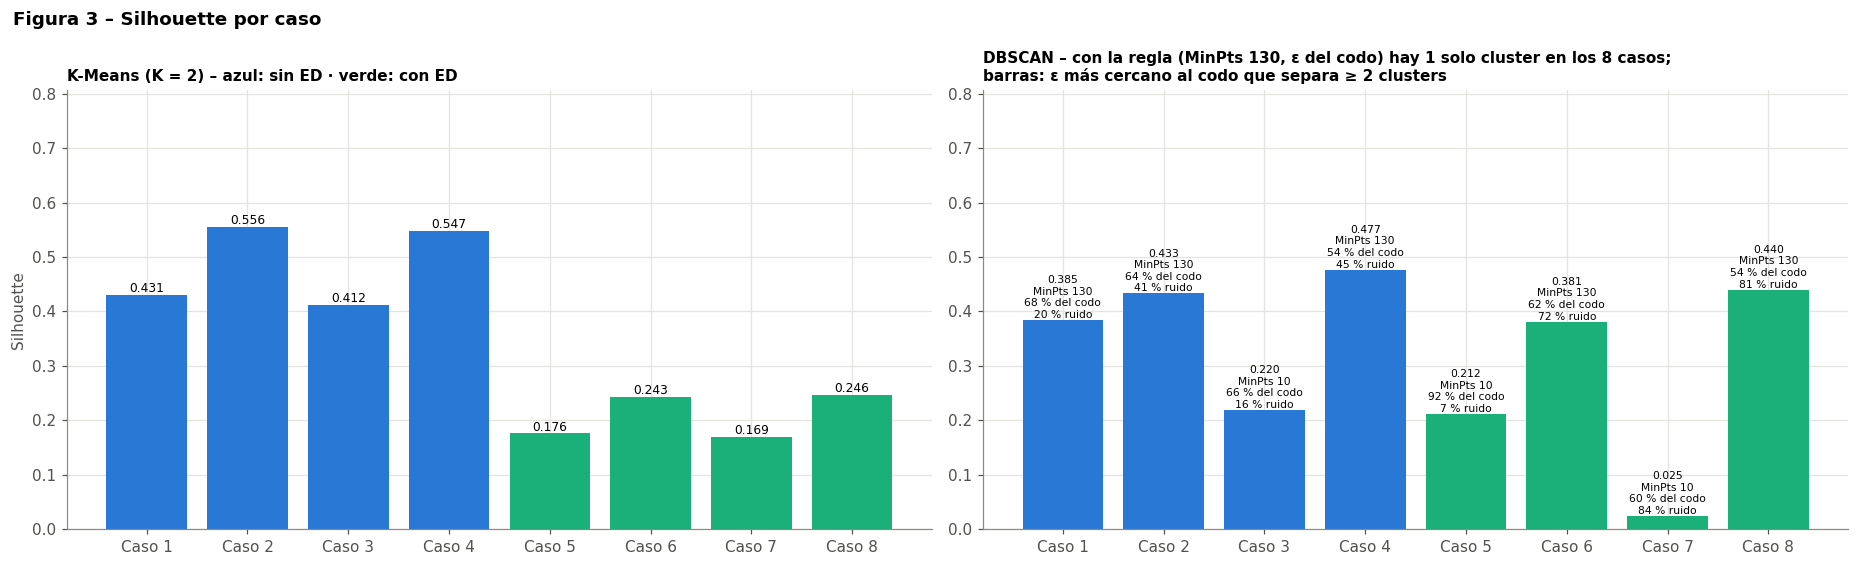

In [79]:
# ============================================================
# 8.4 Tabla de la Figura 3 y gráficas de silhouette
# ============================================================
FIGURA3 = tabla_figura3()
FIGURA3["DBSCAN Clusters"] = [RESULTADOS_CLUSTERING[("DBSCAN", k)]["Clusters"] for k in casos]
FIGURA3["DBSCAN % ruido"] = [round(RESULTADOS_CLUSTERING[("DBSCAN", k)]["Ruido"] / len(DATOS_NS[k][0]) * 100, 1)
                             for k in casos]
FIGURA3["DBSCAN Silhouette (complementario)"] = TABLA_DBSCAN_COMPLEMENTARIO["Silhouette (sin ruido)"]
for columna in ["K-Means Inertia", "K-Means Silhouette", "DBSCAN Silhouette", "DBSCAN Silhouette (complementario)"]:
    FIGURA3[columna] = pd.to_numeric(FIGURA3[columna]).round(4 if "Silhouette" in columna else 1)
display(FIGURA3)


def graficar_silhouette_figura3():
    """Las 2 gráficas de la Figura 3: silhouette de K-Means (8 barras) y de DBSCAN (8 barras).
    En DBSCAN, la regla del enunciado deja 1 solo cluster (silhouette no definido), así que las
    barras son de la prueba complementaria y cada una indica MinPts, % del codo y % de ruido."""
    etiquetas_x = [f"Caso {k}" for k in casos]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.2))

    s_km = [RESULTADOS_CLUSTERING[("K-Means", k)]["Silhouette"] for k in casos]
    barras = ax1.bar(etiquetas_x, s_km, color=[COLORES_SERIES[0] if k <= 4 else COLORES_SERIES[2] for k in casos])
    ax1.bar_label(barras, fmt="%.3f", fontsize=8)
    ax1.set_title(f"K-Means (K = {', '.join(str(v) for v in sorted(set(K_OPTIMO.values())))}) – "
                  "azul: sin ED · verde: con ED", loc="left", fontsize=10)
    ax1.set_ylabel("Silhouette")

    s_db = [DBSCAN_COMPLEMENTARIO[k]["Silhouette"] for k in casos]
    barras = ax2.bar(etiquetas_x, s_db, color=[COLORES_SERIES[0] if k <= 4 else COLORES_SERIES[2] for k in casos])
    notas = [f"{DBSCAN_COMPLEMENTARIO[k]['Silhouette']:.3f}\nMinPts {DBSCAN_COMPLEMENTARIO[k]['MinPts']}"
             f"\n{DBSCAN_COMPLEMENTARIO[k]['% del codo']} % del codo\n{DBSCAN_COMPLEMENTARIO[k]['% ruido']:.0f} % ruido"
             for k in casos]
    ax2.bar_label(barras, labels=notas, fontsize=7)
    ax2.set_ylim(0, max(max(s_db), max(s_km)) * 1.45)
    ax1.set_ylim(0, max(max(s_db), max(s_km)) * 1.45)
    ax2.set_title("DBSCAN – con la regla (MinPts 130, ε del codo) hay 1 solo cluster en los 8 casos;\n"
                  "barras: ε más cercano al codo que separa ≥ 2 clusters", loc="left", fontsize=10)
    fig.suptitle("Figura 3 – Silhouette por caso", x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


graficar_silhouette_figura3()

### 8.5 Comparación entre K-Means y DBSCAN
*Documento, sección 9.3.*

### 8.6 Visualización 2D con PCA
PCA ajustado con los datos agrupados, solo para graficar: centroides de K-Means (X negra) y ruido de DBSCAN en gris. *Documento, sección 10.*

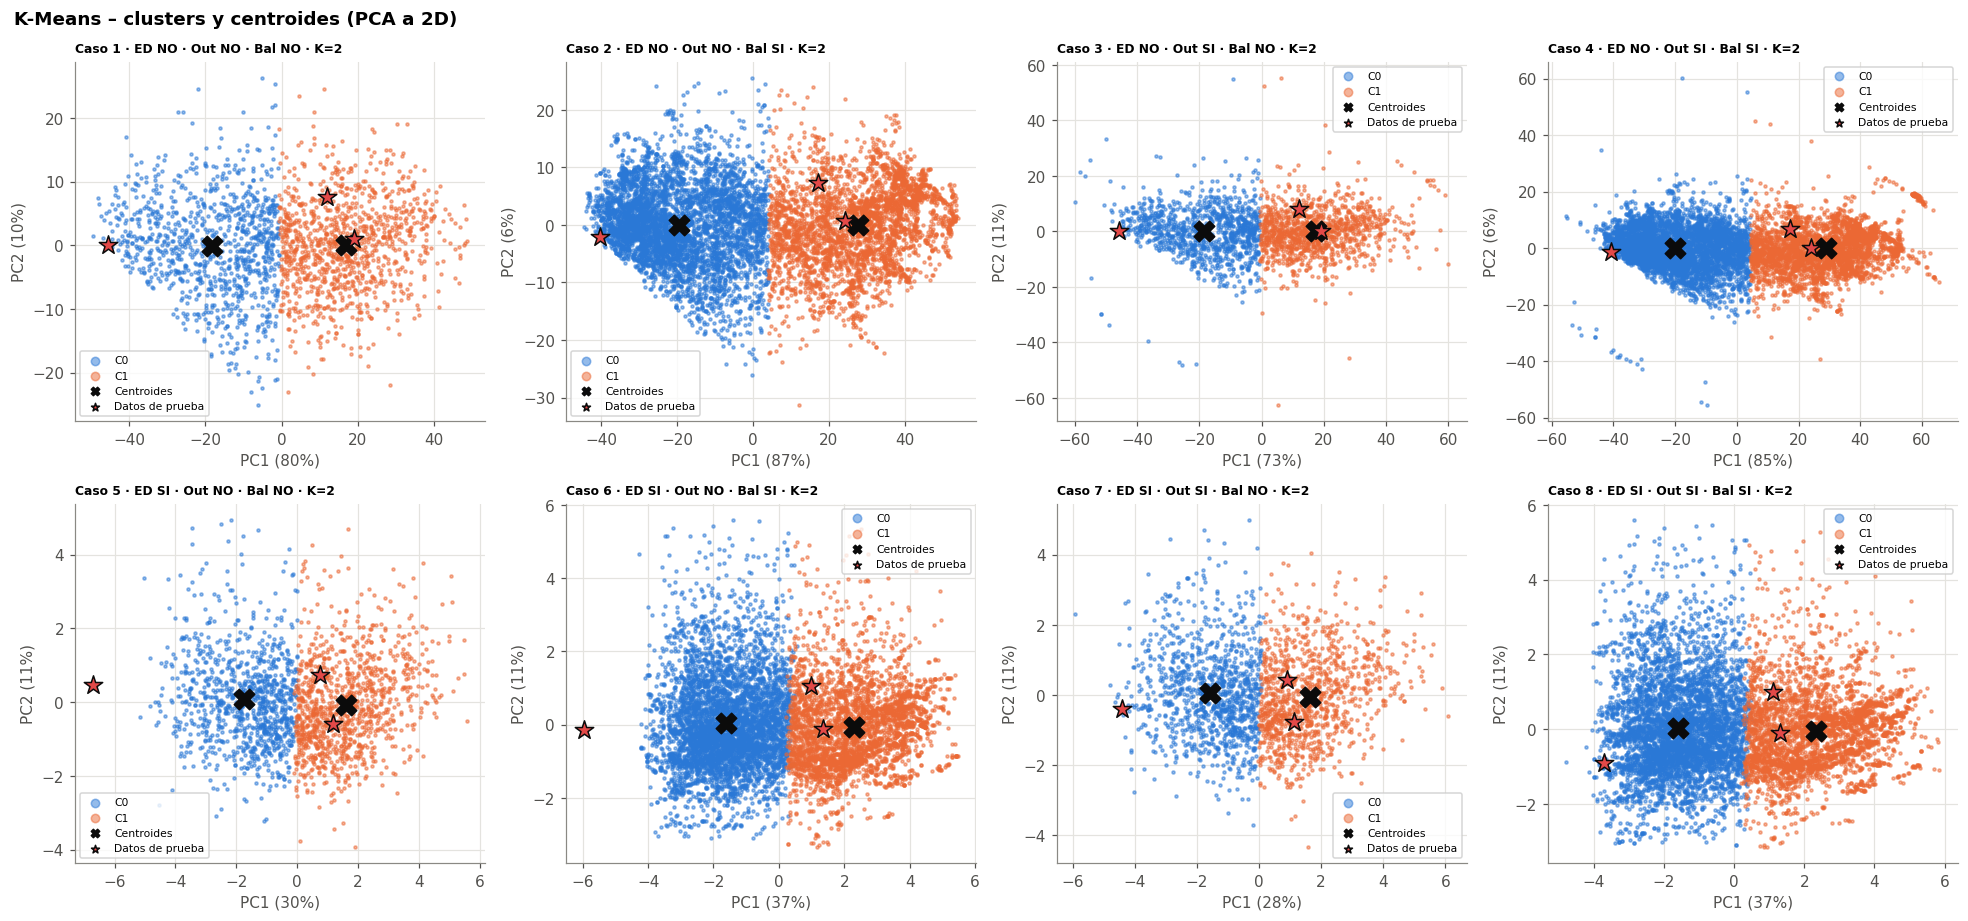

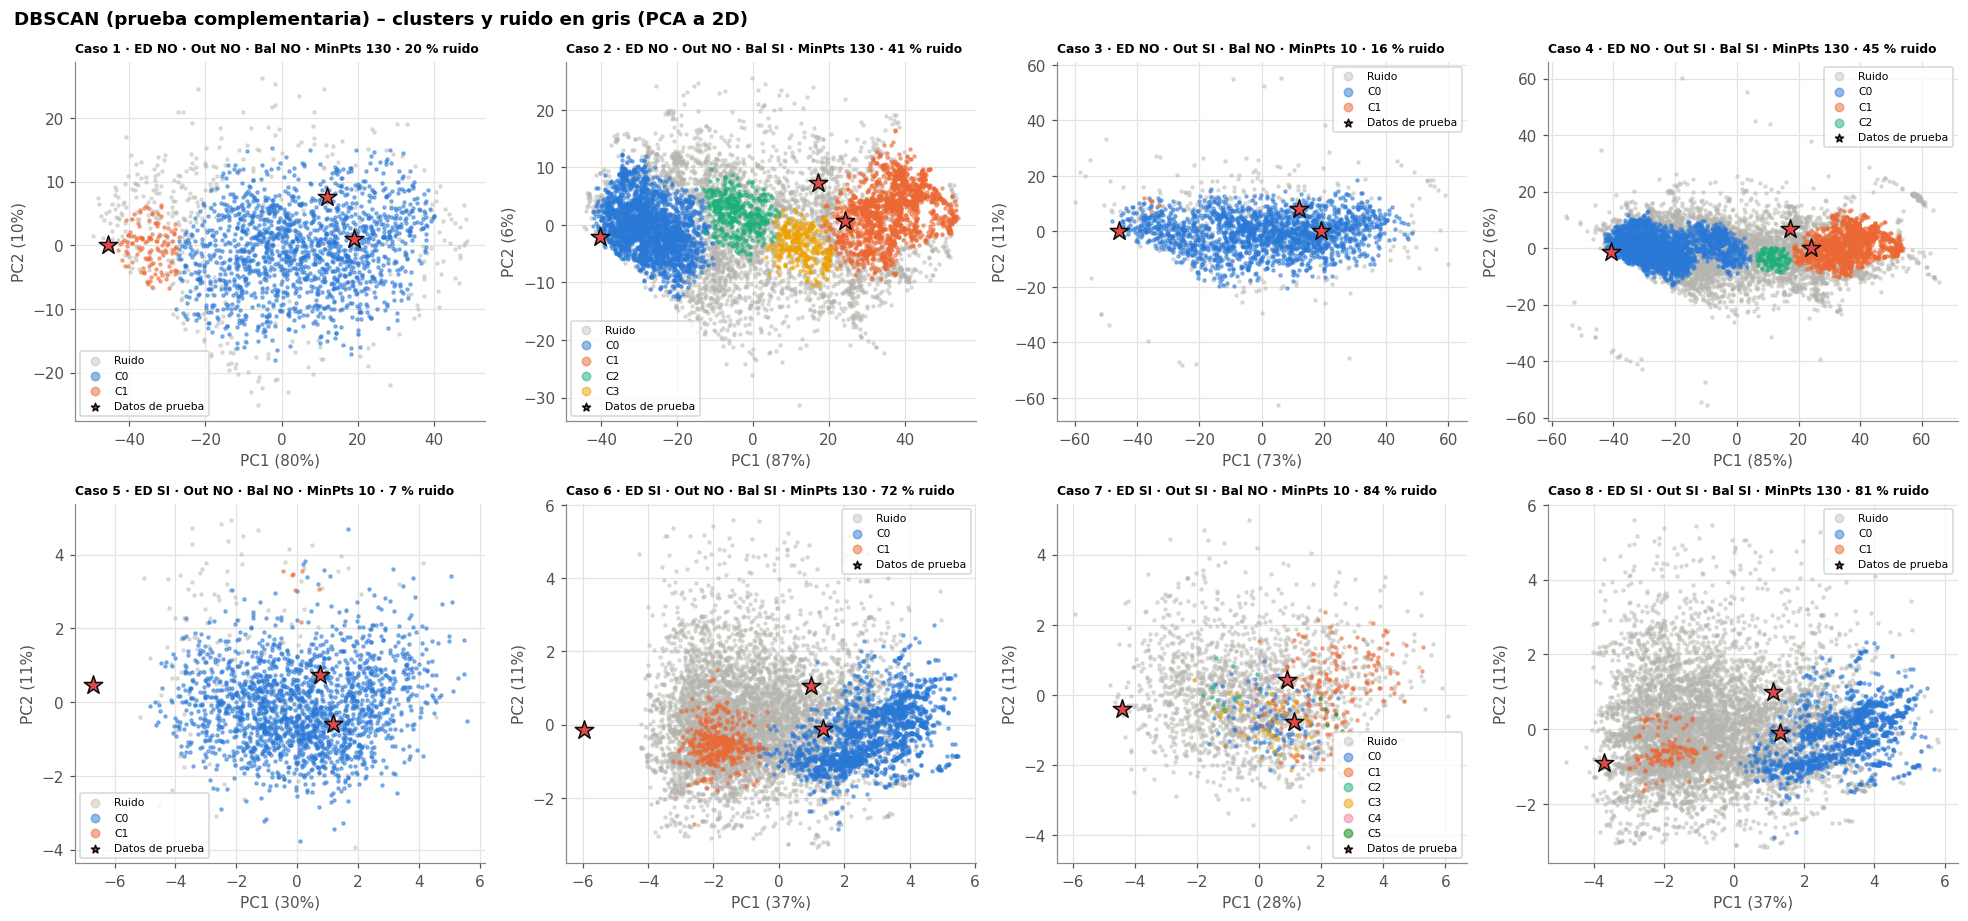

In [80]:
# ============================================================
# 8.6 Visualización 2D con PCA (solo para graficar)
# ============================================================
def graficar_pca_clusters(tecnica):
    """Clusters de los 8 casos proyectados a 2D con PCA (ajustado con los datos de cada caso).
    K-Means: centroides con una X negra. DBSCAN (prueba complementaria): ruido en gris.
    Los 3 registros de demostración se marcan con estrellas."""
    fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
    for ax, k in zip(axes.ravel(), casos):
        X_ns, _ = DATOS_NS[k]
        pca = PCA(n_components=2, random_state=SEMILLA).fit(X_ns)
        X_2d = pca.transform(X_ns)
        if tecnica == "K-Means":
            etiquetas = ETIQUETAS_KMEANS[k]
        else:
            etiquetas = DBSCAN_COMPLEMENTARIO[k]["modelo"].labels_
        if (etiquetas == -1).any():
            ax.scatter(X_2d[etiquetas == -1, 0], X_2d[etiquetas == -1, 1], s=4, c="#b5b4ae", alpha=0.4,
                       label="Ruido")
        for c in sorted(set(etiquetas) - {-1}):
            ax.scatter(X_2d[etiquetas == c, 0], X_2d[etiquetas == c, 1], s=4, alpha=0.5,
                       color=COLORES_SERIES[c % len(COLORES_SERIES)], label=f"C{c}")
        if tecnica == "K-Means":
            centros = pca.transform(pd.DataFrame(MODELOS_KMEANS[k].cluster_centers_, columns=X_ns.columns))
            centros = centros[[original for original, _ in sorted(MAPA_KMEANS[k].items(), key=lambda par: par[1])]]
            ax.scatter(centros[:, 0], centros[:, 1], s=180, c="#0b0b0b", marker="X", label="Centroides")
        X_demo, _ = obtener_datos_demo(k)
        demo_2d = pca.transform(X_demo[X_ns.columns])
        ax.scatter(demo_2d[:, 0], demo_2d[:, 1], s=160, marker="*", c="#e34948", edgecolor="#0b0b0b",
                   label="Datos de prueba")
        c = casos[k]
        detalle = (f"K={K_OPTIMO[k]}" if tecnica == "K-Means" else
                   f"MinPts {DBSCAN_COMPLEMENTARIO[k]['MinPts']} · {DBSCAN_COMPLEMENTARIO[k]['% ruido']:.0f} % ruido")
        ax.set_title(f"Caso {k} · ED {c['normalizacion'][-3:-1]} · Out {c['outliers']} · Bal {c['balanceo']} · "
                     f"{detalle}", loc="left", fontsize=8)
        ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
        ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
        leyenda = ax.legend(fontsize=7, loc="best")
        for marca in leyenda.legend_handles:
            marca.set_sizes([30])
    titulo = ("K-Means – clusters y centroides (PCA a 2D)" if tecnica == "K-Means" else
              "DBSCAN (prueba complementaria) – clusters y ruido en gris (PCA a 2D)")
    fig.suptitle(titulo, x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


graficar_pca_clusters("K-Means")
graficar_pca_clusters("DBSCAN")

### 8.7 Interpretación de los clusters y validación externa
Tabla cruzada cluster × nivel real (la etiqueta solo se usa aquí) y perfil de cada cluster: promedio de las numéricas y, en el estrato y la educación de la madre, la mediana y porcentajes. *Documento, sección 10.*

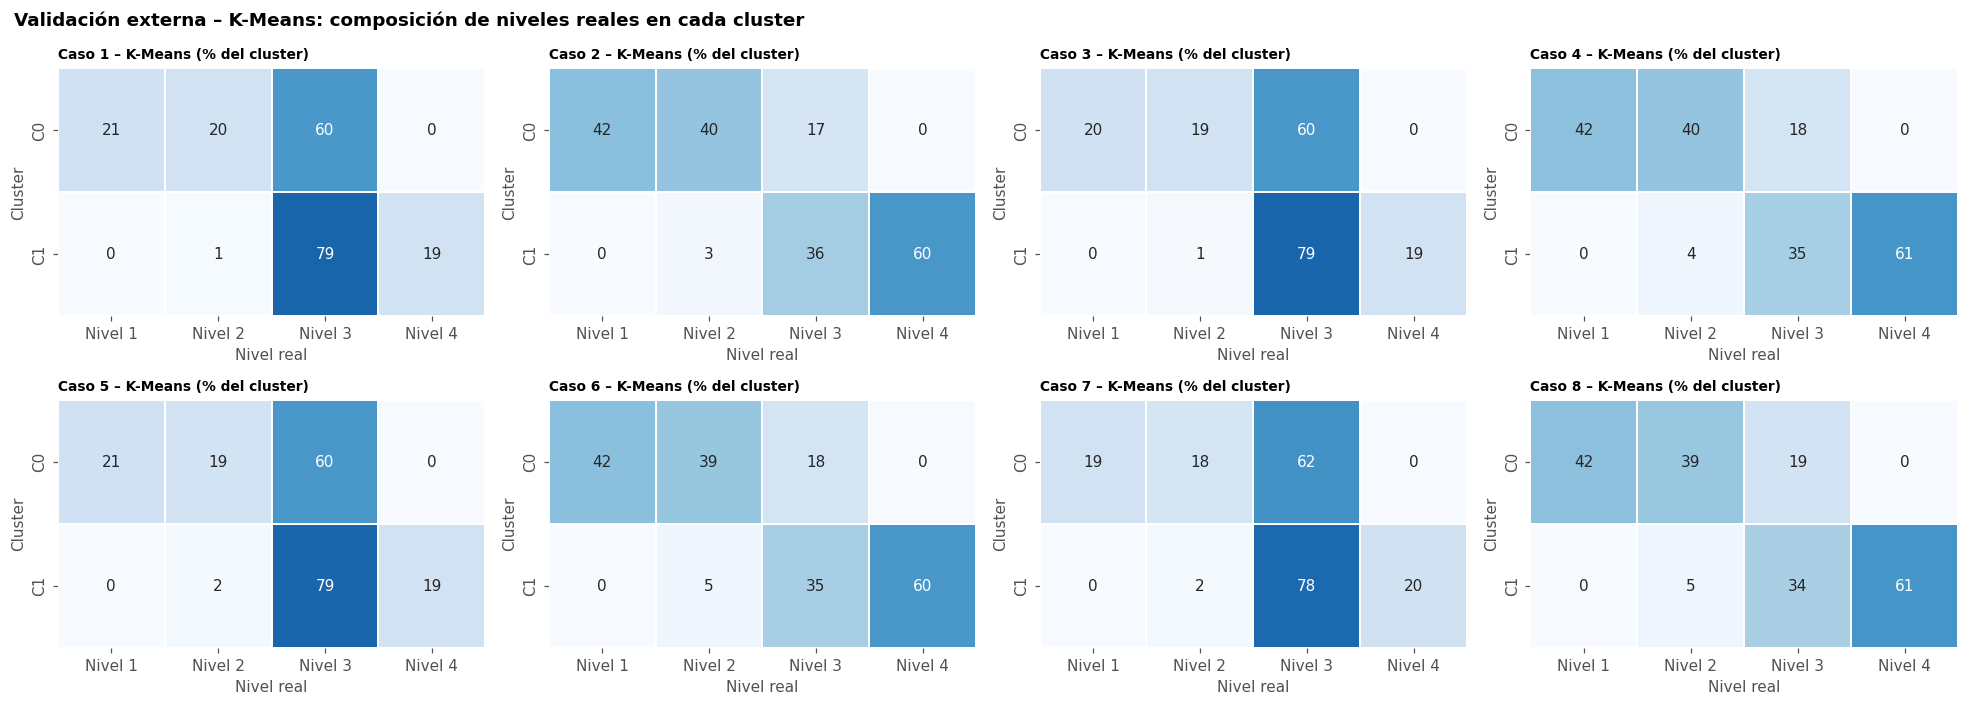

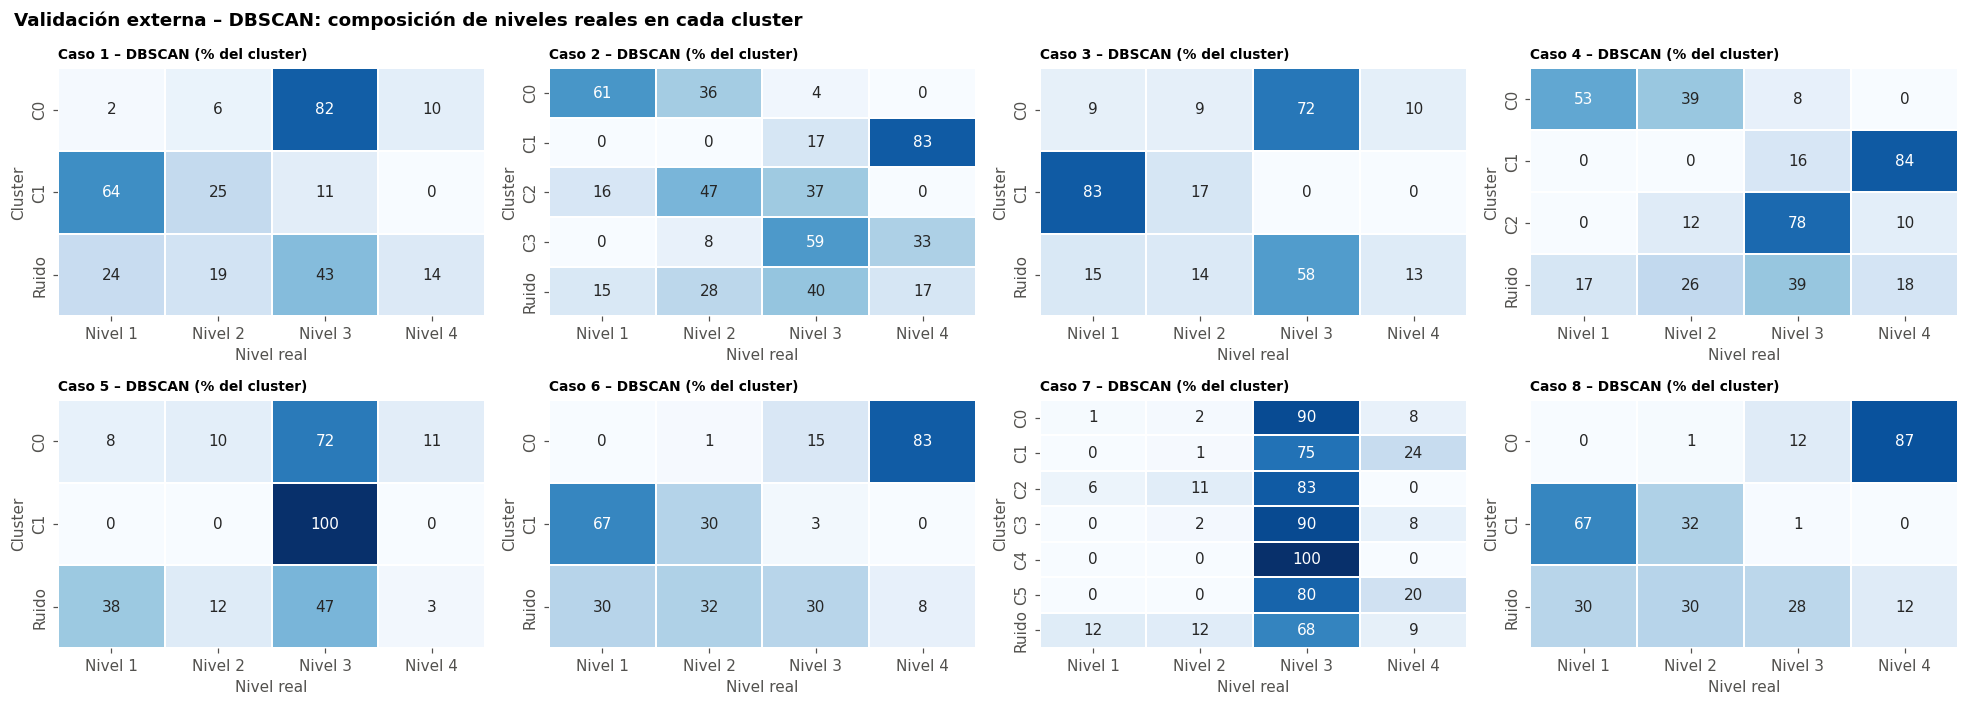

,Registros,PUNT_LECTURA_CRITICA,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES,EDAD,Estrato (mediana),% estrato 3 o más,% sin estrato,Educación madre (mediana),% Nivel 1,% Nivel 4
Caso 1 · C0,989,48.9,45.1,42.5,44.2,17.1,Estrato 2,23.7,5.0,Secundaria (Bachillerato) completa,20.6,0.0
Caso 1 · C1,1061,64.4,61.0,61.2,64.3,16.6,Estrato 2,41.9,0.8,Secundaria (Bachillerato) completa,0.1,19.3
Caso 2 · C0,4816,45.0,41.4,38.8,42.0,17.2,Estrato 2,17.9,7.9,Secundaria (Bachillerato) completa,42.4,0.0
Caso 2 · C1,3392,66.5,64.2,63.7,67.4,16.5,Estrato 2,40.1,0.8,Técnica o tecnológica completa,0.4,60.5
Caso 3 · C0,1053,48.6,45.0,42.4,44.0,17.6,Estrato 2,25.4,4.4,Secundaria (Bachillerato) completa,20.4,0.1
Caso 3 · C1,1117,64.5,61.0,61.3,64.6,16.9,Estrato 2,42.2,0.8,Técnica o tecnológica incompleta,0.2,19.3
Caso 4 · C0,4898,44.9,41.4,39.0,41.7,18.0,Estrato 2,17.8,8.2,Secundaria (Bachillerato) completa,42.1,0.0
Caso 4 · C1,3398,67.0,64.7,64.1,68.6,16.6,Estrato 2,42.9,0.6,Técnica o tecnológica completa,0.3,61.0
Caso 5 · C0,990,49.1,45.5,43.2,44.4,17.1,Estrato 2,19.2,5.1,Secundaria (Bachillerato) completa,20.6,0.2
Caso 5 · C1,1060,64.2,60.6,60.6,64.1,16.5,Estrato 2,46.1,0.7,Técnica o tecnológica completa,0.1,19.2


In [81]:
# ============================================================
# 8.7 Interpretación de los clusters y validación externa
# ============================================================
def graficar_validacion_externa(tecnica="K-Means"):
    """Tabla cruzada cluster × nivel real de matemáticas (como una matriz de confusión) en los
    8 casos. Cada fila suma 100 %: muestra la composición de niveles dentro de cada cluster.
    La etiqueta real solo se usa aquí, después de agrupar."""
    fig, axes = plt.subplots(2, 4, figsize=(18, 6.5))
    for ax, k in zip(axes.ravel(), casos):
        _, y_ext = DATOS_NS[k]
        etiquetas = (ETIQUETAS_KMEANS[k] if tecnica == "K-Means"
                     else DBSCAN_COMPLEMENTARIO[k]["modelo"].labels_)
        cruce = pd.crosstab(pd.Series(etiquetas).map(nombre_cluster).to_numpy(), y_ext.to_numpy(),
                            normalize="index").reindex(columns=CLASES, fill_value=0) * 100
        sns.heatmap(cruce, annot=True, fmt=".0f", cmap="Blues", cbar=False, linewidths=1,
                    linecolor="white", vmin=0, vmax=100, ax=ax)
        ax.set_title(f"Caso {k} – {tecnica} (% del cluster)", loc="left", fontsize=9)
        ax.set_xlabel("Nivel real")
        ax.set_ylabel("Cluster")
        ax.grid(False)
    fig.suptitle(f"Validación externa – {tecnica}: composición de niveles reales en cada cluster",
                 x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


def perfil_clusters(k, columnas=COLUMNAS_NUMERICAS_NS):
    """Perfil de cada cluster de K-Means en el caso k, en la escala original (en los casos 5–8 se
    toman los mismos registros de su par sin escalar), con el tamaño y el % de Nivel 1 y Nivel 4.
    - Variables numéricas: promedio.
    - Estrato y educación de la madre: son ordinales, así que no promediamos sus códigos.
      Reportamos la categoría mediana con su nombre y, en el estrato, el % de estudiantes en
      estrato 3 o superior y el % sin estrato."""
    X_original = DATOS_NS[k - 4][0] if k > 4 else DATOS_NS[k][0]
    _, y_ext = DATOS_NS[k]
    etiquetas = ETIQUETAS_KMEANS[k]
    perfil = X_original[columnas].groupby(etiquetas).mean().round(1)
    estrato = X_original["FAMI_ESTRATOVIVIENDA"].round().astype(int)
    madre = X_original["FAMI_EDUCACIONMADRE"].round().astype(int)

    def mediana_con_nombre(codigos, orden):
        # interpolation="lower" devuelve siempre una categoría que existe, nunca un valor intermedio
        mediana = codigos.groupby(etiquetas).quantile(0.5, interpolation="lower").astype(int)
        return mediana.map(dict(enumerate(orden)))

    perfil["Estrato (mediana)"] = mediana_con_nombre(estrato, VARIABLES_ORDINALES["FAMI_ESTRATOVIVIENDA"])
    perfil["% estrato 3 o más"] = ((estrato >= 3).groupby(etiquetas).mean() * 100).round(1)
    perfil["% sin estrato"] = ((estrato == 0).groupby(etiquetas).mean() * 100).round(1)
    perfil["Educación madre (mediana)"] = mediana_con_nombre(madre, VARIABLES_ORDINALES["FAMI_EDUCACIONMADRE"])
    perfil.index = [f"Caso {k} · C{c}" for c in perfil.index]
    perfil.insert(0, "Registros", np.bincount(etiquetas))
    for nivel in ("Nivel 1", "Nivel 4"):
        perfil[f"% {nivel}"] = (y_ext.eq(nivel).groupby(etiquetas).mean() * 100).round(1).to_numpy()
    return perfil


graficar_validacion_externa("K-Means")
graficar_validacion_externa("DBSCAN")
PERFILES_KMEANS = pd.concat([perfil_clusters(k) for k in casos])
display(PERFILES_KMEANS)

### 8.8 Resumen de K-Means y DBSCAN

In [82]:
# ============================================================
# 8.8 Resumen de K-Means y DBSCAN
# ============================================================
def resumen_bloque4():
    """Silhouette medio de K-Means por factor de preprocesamiento (escalado, outliers y balanceo)."""
    config = pd.DataFrame({k: {"ED": c["normalizacion"][-3:-1], "Outliers": c["outliers"],
                               "Balanceo": c["balanceo"]} for k, c in casos.items()}).T
    config["K-Means Silhouette"] = [RESULTADOS_CLUSTERING[("K-Means", k)]["Silhouette"] for k in casos]
    config["DBSCAN Silhouette (complementario)"] = [DBSCAN_COMPLEMENTARIO[k]["Silhouette"] for k in casos]
    return pd.concat({factor: config.groupby(factor)[["K-Means Silhouette",
                                                      "DBSCAN Silhouette (complementario)"]].mean()
                      for factor in ("ED", "Outliers", "Balanceo")}).round(4)


PROMEDIOS_BLOQUE4 = resumen_bloque4()
display(PROMEDIOS_BLOQUE4)

K-Means Silhouette  DBSCAN Silhouette (complementario)
         ED                                                        
ED       NO              0.4864                              0.3786
         SI              0.2086                              0.2647
Outliers NO              0.3513                              0.3529
         SI              0.3437                              0.2904
Balanceo NO              0.2970                              0.2104
         SI              0.3980                              0.4329